# Cell 1: Setup & Paths (Enhanced)

In [ ]:
# @title
# Cell 1: Setup & Paths (Using Clean CSV Files)
from google.colab import drive
import os
from pathlib import Path
from typing import Any, Dict, List, Optional, Union
import json
import warnings
warnings.filterwarnings('ignore')

# Mount drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
else:
    print("Drive already mounted, reusing existing mount")

# Define paths
BASE_DIR = Path("/content/drive/MyDrive/Awingi_ASR_Processed_Data")
DATA_DIR = BASE_DIR / "processed"
WORK_DIR = BASE_DIR / "awingi_asr_working"
MODEL_DIR = WORK_DIR / "xlsr_awingi"
CACHE_DIR = WORK_DIR / "cache"

# Create directories
for path in [WORK_DIR, MODEL_DIR, CACHE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Path to CSV files (clean splits)
TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV = DATA_DIR / "val.csv"
TEST_CSV = DATA_DIR / "test.csv"

print("✅ Drive ready")
print(f"📂 Working dir: {WORK_DIR}")
print(f"📂 Data dir: {DATA_DIR}")
print(f"📊 Using clean CSV splits:")
print(f"   - Train: {TRAIN_CSV}")
print(f"   - Validation: {VAL_CSV}")
print(f"   - Test: {TEST_CSV}")

Drive already mounted, reusing existing mount
✅ Drive ready
📂 Working dir: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working
📂 Data dir: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed
📊 Using clean CSV splits:
   - Train: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/train.csv
   - Validation: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/val.csv
   - Test: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/test.csv


# Cell 1.5: Memory Cleaning Function

In [ ]:
# @title
# Cell 1.5: Memory Cleaning Function (Run this first to free up resources)

import gc
import torch
import numpy as np
import psutil
import subprocess
import sys

def clean_memory(aggressive=False):
    """
    Comprehensive memory cleaning function for Colab

    Args:
        aggressive (bool): If True, performs more aggressive cleanup including IPC removal
    """
    print("="*60)
    print("🧹 Starting Memory Cleanup")
    print("="*60)

    # Get initial memory stats
    if torch.cuda.is_available():
        gpu_memory_before = torch.cuda.memory_allocated() / 1024**3
        gpu_cached_before = torch.cuda.memory_reserved() / 1024**3
        print(f"   GPU Memory (before): {gpu_memory_before:.2f} GB allocated, {gpu_cached_before:.2f} GB cached")

    ram_before = psutil.virtual_memory()
    print(f"   RAM (before): {ram_before.used / 1024**3:.2f} GB used, {ram_before.percent}%")

    # 1. Clear Python garbage collector
    print("\n📦 Clearing Python garbage...")
    collected = gc.collect()
    print(f"   Garbage collector: collected {collected} objects")

    # 2. Clear CUDA cache
    if torch.cuda.is_available():
        print("\n🔄 Clearing CUDA cache...")
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

        # Reset peak memory stats
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.reset_accumulated_memory_stats()

        gpu_memory_after = torch.cuda.memory_allocated() / 1024**3
        gpu_cached_after = torch.cuda.memory_reserved() / 1024**3
        print(f"   GPU Memory (after): {gpu_memory_after:.2f} GB allocated, {gpu_cached_after:.2f} GB cached")
        print(f"   Freed: {(gpu_memory_before - gpu_memory_after):.2f} GB")

    # 3. Clear numpy cache
    print("\n🗑️ Clearing numpy cache...")
    np.seterr(all='ignore')

    # 4. Aggressive cleanup if requested
    if aggressive:
        print("\n🔨 Performing aggressive cleanup...")

        # Clear all variables in main namespace (except critical ones)
        import sys
        main_module = sys.modules['__main__']
        protected = ['In', 'Out', 'exit', 'quit', 'get_ipython', 'clean_memory', 'WORK_DIR', 'DATA_DIR', 'BASE_DIR', 'MODEL_DIR']

        deleted = 0
        for var in dir(main_module):
            if not var.startswith('_') and var not in protected:
                try:
                    delattr(main_module, var)
                    deleted += 1
                except:
                    pass
        print(f"   Cleared {deleted} variables from main namespace")

        # Clear IPython outputs if in notebook
        try:
            from IPython import get_ipython
            ipython = get_ipython()
            if ipython:
                ipython.run_line_magic('reset', '-f')
                print("   IPython namespace reset")
        except:
            pass

        # Remove shared memory files (common cause of memory leaks in Colab)
        try:
            subprocess.run(['sudo', 'rm', '-rf', '/dev/shm/*'], check=False)
            print("   Cleared /dev/shm/ (shared memory)")
        except:
            pass

        # Clear matplotlib cache
        try:
            import matplotlib
            matplotlib.pyplot.close('all')
            print("   Closed all matplotlib figures")
        except:
            pass

    # 5. Final RAM check
    ram_after = psutil.virtual_memory()
    print(f"\n📊 RAM (after): {ram_after.used / 1024**3:.2f} GB used, {ram_after.percent}%")
    print(f"   RAM freed: {(ram_before.used - ram_after.used) / 1024**3:.2f} GB")

    print("="*60)
    print("✅ Memory cleanup complete!")
    print("="*60)

    return {
        'gpu_freed': gpu_memory_before - gpu_memory_after if torch.cuda.is_available() else 0,
        'ram_freed': (ram_before.used - ram_after.used) / 1024**3,
        'collected': collected
    }

# Run the cleanup
results = clean_memory(aggressive=False)  # Set to True if you need more aggressive cleanup

print(f"\n📈 Summary: Freed {results['ram_freed']:.2f} GB RAM", end='')
if torch.cuda.is_available():
    print(f" and {results['gpu_freed']:.2f} GB GPU memory")
else:
    print()

🧹 Starting Memory Cleanup
   GPU Memory (before): 0.00 GB allocated, 0.00 GB cached
   RAM (before): 1.41 GB used, 13.7%

📦 Clearing Python garbage...
   Garbage collector: collected 47 objects

🔄 Clearing CUDA cache...
   GPU Memory (after): 0.00 GB allocated, 0.00 GB cached
   Freed: 0.00 GB

🗑️ Clearing numpy cache...

📊 RAM (after): 1.53 GB used, 14.7%
   RAM freed: -0.12 GB
✅ Memory cleanup complete!

📈 Summary: Freed -0.12 GB RAM and 0.00 GB GPU memory


# DataSet Analysis


STARTING COMPREHENSIVE ASR DATASET ANALYSIS
ASR DATASET SPLIT ANALYSIS

✅ Loaded train.csv: 6,598 utterances

✅ Loaded val.csv: 392 utterances

✅ Loaded test.csv: 390 utterances

1. SPEAKER DISTRIBUTION

TRAIN Split:
  • Unique speakers: 70
  • Total utterances: 6,598
  • Utterances per speaker:
    - Min: 66
    - Max: 105
    - Mean: 94.26
    - Std: 7.48
  • Speaker distribution:
    - 51-100 utterances: 67 speakers
    - 100+ utterances: 3 speakers

VAL Split:
  • Unique speakers: 4
  • Total utterances: 392
  • Utterances per speaker:
    - Min: 92
    - Max: 100
    - Mean: 98.00
    - Std: 4.00
  • Speaker distribution:
    - 51-100 utterances: 4 speakers

TEST Split:
  • Unique speakers: 4
  • Total utterances: 390
  • Utterances per speaker:
    - Min: 94
    - Max: 100
    - Mean: 97.50
    - Std: 2.52
  • Speaker distribution:
    - 51-100 utterances: 4 speakers

2. SPEAKER OVERLAP ANALYSIS (DATA LEAKAGE CHECK)

✅ Train-Val speaker overlap: 0 speakers

✅ Train-Test speaker 

Processing train: 100%|██████████| 6598/6598 [47:09<00:00,  2.33it/s]



TRAIN Duration Statistics:
  • Total: 12.04 hours
  • Mean: 6.57 seconds
  • Std: 4.42 seconds
  • Range: 0.54s - 44.48s
  • Failed files: 0 (0.0%)
  • Duration percentiles:
    - 10th: 2.27s
    - 25th: 3.36s
    - 50th: 5.47s
    - 75th: 8.67s
    - 90th: 12.32s
    - 95th: 15.14s
    - 99th: 21.22s

📊 Calculating durations for val split...


Processing val: 100%|██████████| 392/392 [02:47<00:00,  2.34it/s]



VAL Duration Statistics:
  • Total: 0.76 hours
  • Mean: 7.02 seconds
  • Std: 4.74 seconds
  • Range: 0.84s - 25.98s
  • Failed files: 0 (0.0%)
  • Duration percentiles:
    - 10th: 2.36s
    - 25th: 3.46s
    - 50th: 5.71s
    - 75th: 9.49s
    - 90th: 13.85s
    - 95th: 16.94s
    - 99th: 21.09s

📊 Calculating durations for test split...


Processing test: 100%|██████████| 390/390 [02:42<00:00,  2.39it/s]



TEST Duration Statistics:
  • Total: 0.73 hours
  • Mean: 6.77 seconds
  • Std: 4.33 seconds
  • Range: 1.12s - 23.14s
  • Failed files: 0 (0.0%)
  • Duration percentiles:
    - 10th: 2.33s
    - 25th: 3.26s
    - 50th: 5.63s
    - 75th: 9.14s
    - 90th: 13.62s
    - 95th: 15.44s
    - 99th: 17.95s

4. SUMMARY

📊 DATASET SUMMARY
  • Total unique speakers: 78
  • Total utterances: 7,380
  • Total duration: 13.54 hours

TRAIN:
  • Speakers: 70 (89.7% of total)
  • Utterances: 6,598 (89.4%)
  • Duration: 12.04 hours (88.9%)

VAL:
  • Speakers: 4 (5.1% of total)
  • Utterances: 392 (5.3%)
  • Duration: 0.76 hours (5.6%)

TEST:
  • Speakers: 4 (5.1% of total)
  • Utterances: 390 (5.3%)
  • Duration: 0.73 hours (5.4%)

5. SPLIT RATIOS

📈 By Utterances:
  • Train: 89.4% (6,598)
  • Validation: 5.3% (392)
  • Test: 5.3% (390)

📈 By Duration:
  • Train: 88.9% (12.04h)
  • Validation: 5.6% (0.76h)
  • Test: 5.4% (0.73h)

6. RECOMMENDATIONS

For a well-structured ASR dataset:
  ✓ Each split sho

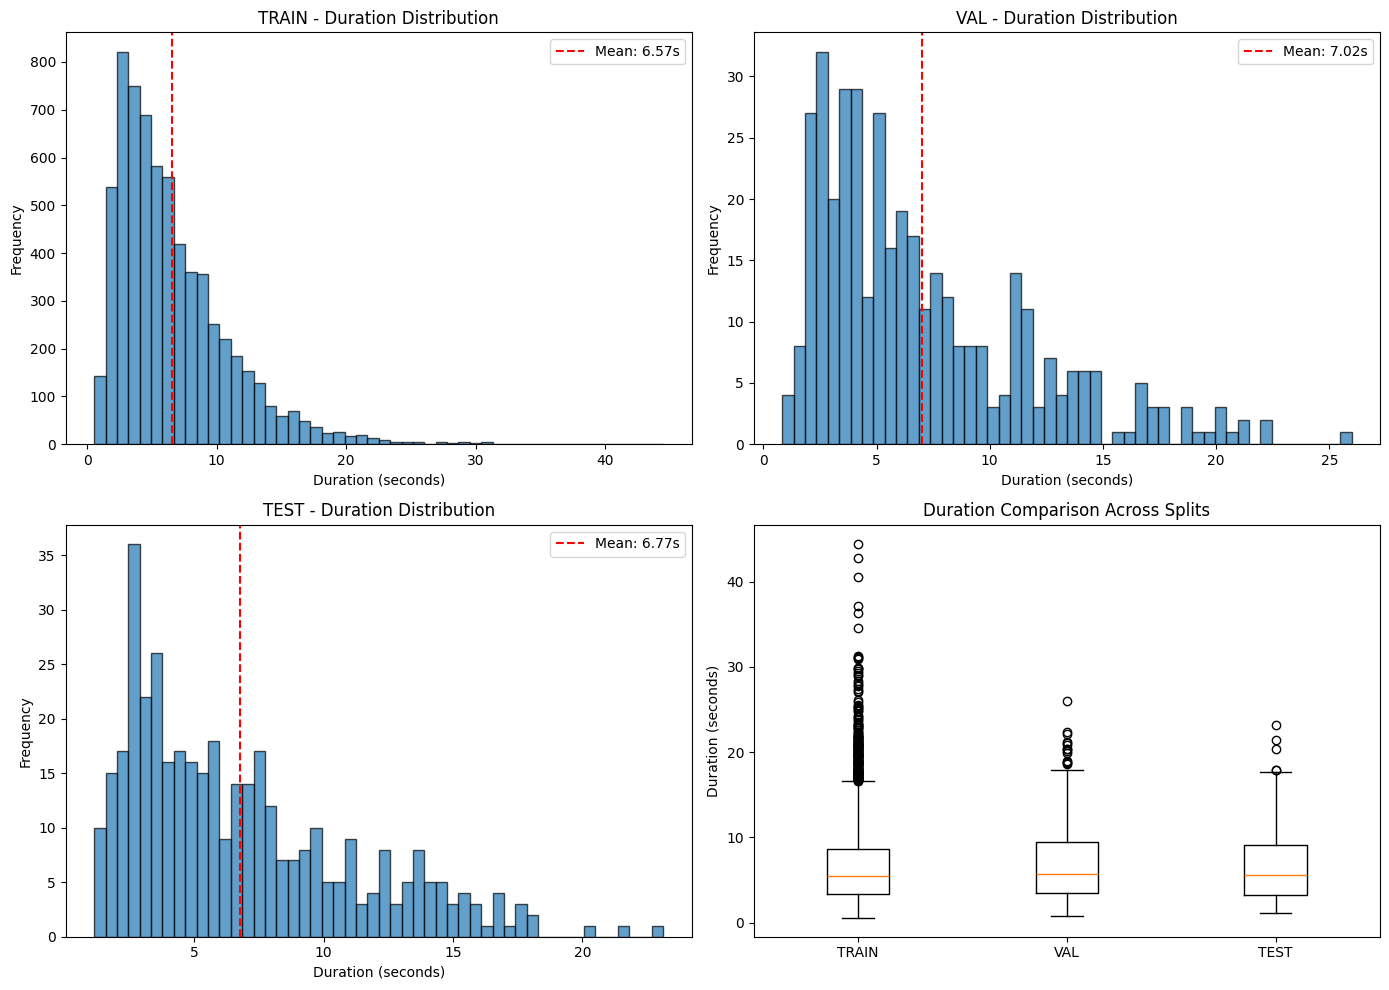


📊 Duration plot saved as 'duration_analysis.png'

✅ ANALYSIS COMPLETE


In [ ]:
# @title
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
import torchaudio
import librosa
from tqdm import tqdm
import time
import pickle
import hashlib
import json
warnings.filterwarnings('ignore')

def get_cache_key(train_path, val_path, test_path):
    """Generate a cache key based on file stats to detect changes"""
    cache_data = []
    for path in [train_path, val_path, test_path]:
        if Path(path).exists():
            stat = Path(path).stat()
            cache_data.append(f"{path}_{stat.st_size}_{stat.st_mtime}")
    return hashlib.md5("".join(cache_data).encode()).hexdigest()

def load_cached_analysis(cache_dir, cache_key):
    """Load cached analysis results if they exist"""
    cache_file = cache_dir / f"analysis_cache_{cache_key}.pkl"
    if cache_file.exists():
        try:
            with open(cache_file, 'rb') as f:
                cached = pickle.load(f)
            print(f"\n📦 Loaded cached analysis from {cache_file}")
            return cached
        except Exception as e:
            print(f"\n⚠️ Failed to load cache: {e}")
    return None

def save_cached_analysis(cache_dir, cache_key, speaker_stats, duration_stats, datasets_info):
    """Save analysis results to cache"""
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_file = cache_dir / f"analysis_cache_{cache_key}.pkl"

    # Store only serializable data (exclude actual DataFrames)
    cache_data = {
        'speaker_stats': speaker_stats,
        'duration_stats': duration_stats,
        'datasets_info': datasets_info,
        'timestamp': time.time()
    }

    try:
        with open(cache_file, 'wb') as f:
            pickle.dump(cache_data, f)
        print(f"\n💾 Analysis cached to {cache_file}")
    except Exception as e:
        print(f"\n⚠️ Failed to save cache: {e}")

def analyze_asr_splits(train_path, val_path, test_path, cache_dir=None, force_recompute=False):
    """
    Analyze train, validation, and test splits for ASR dataset with caching

    Args:
        train_path: Path to train.csv
        val_path: Path to validation.csv
        test_path: Path to test.csv
        cache_dir: Directory to store cache (if None, no caching)
        force_recompute: If True, ignore cache and recompute
    """

    # Setup caching
    if cache_dir:
        cache_dir = Path(cache_dir)
        cache_key = get_cache_key(train_path, val_path, test_path)

        if not force_recompute:
            cached = load_cached_analysis(cache_dir, cache_key)
            if cached:
                print("\n✅ Using cached analysis results")
                return cached['speaker_stats'], cached['duration_stats'], None

    # Load datasets
    print("="*80)
    print("ASR DATASET SPLIT ANALYSIS")
    print("="*80)

    datasets = {}
    datasets_info = {}
    for name, path in [('train', train_path), ('val', val_path), ('test', test_path)]:
        try:
            df = pd.read_csv(path)
            datasets[name] = df
            datasets_info[name] = {
                'path': str(path),
                'rows': len(df),
                'columns': list(df.columns),
                'sample_paths': df['path'].head(3).tolist() if 'path' in df.columns else []
            }
            print(f"\n✅ Loaded {name}.csv: {len(df):,} utterances")
        except FileNotFoundError:
            print(f"\n❌ {path} not found. Will skip {name} analysis.")
            datasets[name] = None
            datasets_info[name] = {'error': 'not found'}

    # 1. Speaker distribution analysis
    print("\n" + "="*80)
    print("1. SPEAKER DISTRIBUTION")
    print("="*80)

    speaker_stats = {}
    all_speakers = set()

    for name in ['train', 'val', 'test']:
        if datasets[name] is not None:
            speakers = datasets[name]['speaker_id'].unique()
            speaker_counts = datasets[name]['speaker_id'].value_counts()
            speaker_stats[name] = {
                'unique_speakers': int(len(speakers)),
                'total_utterances': int(len(datasets[name])),
                'speaker_counts': speaker_counts.to_dict(),
                'speakers': list(speakers)
            }
            all_speakers.update(speakers)

            print(f"\n{name.upper()} Split:")
            print(f"  • Unique speakers: {len(speakers)}")
            print(f"  • Total utterances: {len(datasets[name]):,}")
            print(f"  • Utterances per speaker:")
            print(f"    - Min: {speaker_counts.min()}")
            print(f"    - Max: {speaker_counts.max()}")
            print(f"    - Mean: {speaker_counts.mean():.2f}")
            print(f"    - Std: {speaker_counts.std():.2f}")

            # Distribution by speaker count
            print(f"  • Speaker distribution:")
            bins = [0, 5, 10, 20, 50, 100, float('inf')]
            labels = ['1-5', '6-10', '11-20', '21-50', '51-100', '100+']
            hist = pd.cut(speaker_counts, bins=bins, labels=labels).value_counts().sort_index()
            for range_label, count in hist.items():
                if count > 0:
                    print(f"    - {range_label} utterances: {count} speakers")

    # 2. Speaker overlap analysis (data leakage check)
    print("\n" + "="*80)
    print("2. SPEAKER OVERLAP ANALYSIS (DATA LEAKAGE CHECK)")
    print("="*80)

    if all(datasets[name] is not None for name in ['train', 'val', 'test']):
        train_speakers = set(speaker_stats['train']['speakers'])
        val_speakers = set(speaker_stats['val']['speakers'])
        test_speakers = set(speaker_stats['test']['speakers'])

        train_val_overlap = train_speakers & val_speakers
        train_test_overlap = train_speakers & test_speakers
        val_test_overlap = val_speakers & test_speakers

        print(f"\n✅ Train-Val speaker overlap: {len(train_val_overlap)} speakers")
        if len(train_val_overlap) > 0:
            print(f"   ❌ WARNING: {len(train_val_overlap)} speakers found in both!")
            print(f"   Overlapping speakers: {sorted(train_val_overlap)[:10]}...")

        print(f"\n✅ Train-Test speaker overlap: {len(train_test_overlap)} speakers")
        if len(train_test_overlap) > 0:
            print(f"   ❌ WARNING: {len(train_test_overlap)} speakers found in both!")
            print(f"   Overlapping speakers: {sorted(train_test_overlap)[:10]}...")

        print(f"\n✅ Val-Test speaker overlap: {len(val_test_overlap)} speakers")
        if len(val_test_overlap) > 0:
            print(f"   ❌ WARNING: {len(val_test_overlap)} speakers found in both!")

        # Store overlap stats
        speaker_stats['overlap'] = {
            'train_val': len(train_val_overlap),
            'train_test': len(train_test_overlap),
            'val_test': len(val_test_overlap)
        }
    else:
        print("\n⚠️ Cannot perform overlap analysis - missing some split files")

    # 3. Duration analysis
    print("\n" + "="*80)
    print("3. AUDIO DURATION ANALYSIS")
    print("="*80)

    duration_stats = {}
    total_duration = 0

    for name in ['train', 'val', 'test']:
        if datasets[name] is not None:
            print(f"\n📊 Calculating durations for {name} split...")

            durations = []
            error_count = 0
            error_files = []

            # Process with progress bar
            for idx, row in tqdm(datasets[name].iterrows(), total=len(datasets[name]), desc=f"Processing {name}"):
                try:
                    audio_path = row['path']
                    # Try torchaudio first (faster)
                    info = torchaudio.info(audio_path)
                    duration = info.num_frames / info.sample_rate
                    durations.append(duration)
                except:
                    try:
                        # Fallback to librosa
                        duration = librosa.get_duration(filename=audio_path)
                        durations.append(duration)
                    except Exception as e:
                        error_count += 1
                        error_files.append(str(audio_path))
                        durations.append(0)  # Placeholder for failed files

            # Convert to numpy array
            durations = np.array(durations)
            valid_durations = durations[durations > 0]

            split_duration = valid_durations.sum() / 3600  # Convert to hours
            total_duration += split_duration

            duration_stats[name] = {
                'durations': durations.tolist(),  # Convert to list for serialization
                'valid_count': int(len(valid_durations)),
                'error_count': error_count,
                'error_files': error_files[:10],  # Store only first 10 errors
                'total_hours': float(split_duration),
                'mean_seconds': float(valid_durations.mean()) if len(valid_durations) > 0 else 0,
                'std_seconds': float(valid_durations.std()) if len(valid_durations) > 0 else 0,
                'min_seconds': float(valid_durations.min()) if len(valid_durations) > 0 else 0,
                'max_seconds': float(valid_durations.max()) if len(valid_durations) > 0 else 0,
                'percentiles': {}
            }

            # Duration percentiles
            if len(valid_durations) > 0:
                percentiles = [10, 25, 50, 75, 90, 95, 99]
                for p in percentiles:
                    duration_stats[name]['percentiles'][p] = float(np.percentile(valid_durations, p))

            print(f"\n{name.upper()} Duration Statistics:")
            print(f"  • Total: {split_duration:.2f} hours")
            print(f"  • Mean: {duration_stats[name]['mean_seconds']:.2f} seconds")
            print(f"  • Std: {duration_stats[name]['std_seconds']:.2f} seconds")
            print(f"  • Range: {duration_stats[name]['min_seconds']:.2f}s - {duration_stats[name]['max_seconds']:.2f}s")
            print(f"  • Failed files: {error_count} ({error_count/len(durations)*100:.1f}%)")

            if len(valid_durations) > 0:
                print(f"  • Duration percentiles:")
                for p, val in duration_stats[name]['percentiles'].items():
                    print(f"    - {p}th: {val:.2f}s")

    # 4. Summary
    print("\n" + "="*80)
    print("4. SUMMARY")
    print("="*80)

    total_speakers = len(all_speakers)
    total_utterances = sum(len(df) for df in datasets.values() if df is not None)

    print(f"\n📊 DATASET SUMMARY")
    print(f"  • Total unique speakers: {total_speakers}")
    print(f"  • Total utterances: {total_utterances:,}")
    print(f"  • Total duration: {total_duration:.2f} hours")

    for name in ['train', 'val', 'test']:
        if datasets[name] is not None:
            stats = speaker_stats[name]
            pct_speakers = (stats['unique_speakers'] / total_speakers) * 100
            pct_utterances = (stats['total_utterances'] / total_utterances) * 100
            pct_duration = (duration_stats[name]['total_hours'] / total_duration) * 100 if name in duration_stats else 0

            print(f"\n{name.upper()}:")
            print(f"  • Speakers: {stats['unique_speakers']} ({pct_speakers:.1f}% of total)")
            print(f"  • Utterances: {stats['total_utterances']:,} ({pct_utterances:.1f}%)")
            if name in duration_stats:
                print(f"  • Duration: {duration_stats[name]['total_hours']:.2f} hours ({pct_duration:.1f}%)")

    # 5. Split ratios
    print("\n" + "="*80)
    print("5. SPLIT RATIOS")
    print("="*80)

    if all(datasets[name] is not None for name in ['train', 'val', 'test']):
        train_utt = len(datasets['train'])
        val_utt = len(datasets['val'])
        test_utt = len(datasets['test'])
        total_utt = train_utt + val_utt + test_utt

        train_dur = duration_stats['train']['total_hours'] if 'train' in duration_stats else 0
        val_dur = duration_stats['val']['total_hours'] if 'val' in duration_stats else 0
        test_dur = duration_stats['test']['total_hours'] if 'test' in duration_stats else 0

        print(f"\n📈 By Utterances:")
        print(f"  • Train: {train_utt/total_utt*100:.1f}% ({train_utt:,})")
        print(f"  • Validation: {val_utt/total_utt*100:.1f}% ({val_utt:,})")
        print(f"  • Test: {test_utt/total_utt*100:.1f}% ({test_utt:,})")

        if train_dur > 0:
            total_dur = train_dur + val_dur + test_dur
            print(f"\n📈 By Duration:")
            print(f"  • Train: {train_dur/total_dur*100:.1f}% ({train_dur:.2f}h)")
            print(f"  • Validation: {val_dur/total_dur*100:.1f}% ({val_dur:.2f}h)")
            print(f"  • Test: {test_dur/total_dur*100:.1f}% ({test_dur:.2f}h)")

    # 6. Recommendations
    print("\n" + "="*80)
    print("6. RECOMMENDATIONS")
    print("="*80)

    print("\nFor a well-structured ASR dataset:")
    print("  ✓ Each split should have disjoint speakers (no overlap)")
    print("  ✓ Train: 80-90% of data")
    print("  ✓ Validation: 5-10% of data")
    print("  ✓ Test: 5-10% of data")
    print("  ✓ Each speaker should have multiple utterances (5+ ideal)")
    print("  ✓ Audio durations should be balanced across splits")

    issues_found = False

    if all(datasets[name] is not None for name in ['train', 'val', 'test']):
        if 'overlap' in speaker_stats:
            if speaker_stats['overlap']['train_val'] > 0 or speaker_stats['overlap']['train_test'] > 0:
                print("\n❌ CRITICAL ISSUE: Speaker overlap detected!")
                print("   This invalidates ASR evaluation. Re-split with disjoint speakers.")
                issues_found = True

        # Check split ratios
        train_pct = len(datasets['train']) / total_utt * 100
        val_pct = len(datasets['val']) / total_utt * 100
        test_pct = len(datasets['test']) / total_utt * 100

        if train_pct < 70 or train_pct > 90:
            print(f"\n⚠️ Train split size ({train_pct:.1f}%) is outside ideal range (70-90%)")
            issues_found = True

        if val_pct < 5 or val_pct > 15:
            print(f"\n⚠️ Validation split size ({val_pct:.1f}%) is outside ideal range (5-15%)")
            issues_found = True

        if test_pct < 5 or test_pct > 15:
            print(f"\n⚠️ Test split size ({test_pct:.1f}%) is outside ideal range (5-15%)")
            issues_found = True

    if not issues_found:
        print("\n✅ No major issues detected! Dataset appears well-structured.")

    # Save to cache if enabled
    if cache_dir:
        save_cached_analysis(cache_dir, cache_key, speaker_stats, duration_stats, datasets_info)

    return speaker_stats, duration_stats, datasets

def check_duplicate_entries(train_df, val_df, test_df):
    """
    Check for duplicate audio entries across splits
    """
    print("\n" + "="*80)
    print("DUPLICATE AUDIO ENTRIES CHECK")
    print("="*80)

    train_paths = set(train_df['path'].tolist())
    val_paths = set(val_df['path'].tolist())
    test_paths = set(test_df['path'].tolist())

    train_val_dup = train_paths & val_paths
    train_test_dup = train_paths & test_paths
    val_test_dup = val_paths & test_paths

    print(f"\nTrain-Val duplicate entries: {len(train_val_dup)}")
    if len(train_val_dup) > 0:
        print(f"  ❌ Found {len(train_val_dup)} duplicate audio files!")
        print(f"  Examples: {list(train_val_dup)[:5]}")

    print(f"\nTrain-Test duplicate entries: {len(train_test_dup)}")
    if len(train_test_dup) > 0:
        print(f"  ❌ Found {len(train_test_dup)} duplicate audio files!")
        print(f"  Examples: {list(train_test_dup)[:5]}")

    print(f"\nVal-Test duplicate entries: {len(val_test_dup)}")
    if len(val_test_dup) > 0:
        print(f"  ❌ Found {len(val_test_dup)} duplicate audio files!")
        print(f"  Examples: {list(val_test_dup)[:5]}")

    return {
        'train_val': len(train_val_dup),
        'train_test': len(train_test_dup),
        'val_test': len(val_test_dup)
    }

def plot_duration_distribution(duration_stats, save_path=None):
    """
    Optional: Plot duration distributions (requires matplotlib)
    """
    try:
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        # Duration histograms
        for idx, (name, stats) in enumerate(duration_stats.items()):
            if idx < 3:
                ax = axes[idx // 2, idx % 2]
                durations = np.array(stats['durations'])
                durations = durations[durations > 0]
                ax.hist(durations, bins=50, edgecolor='black', alpha=0.7)
                ax.set_title(f'{name.upper()} - Duration Distribution')
                ax.set_xlabel('Duration (seconds)')
                ax.set_ylabel('Frequency')
                ax.axvline(stats['mean_seconds'], color='red', linestyle='--', label=f'Mean: {stats["mean_seconds"]:.2f}s')
                ax.legend()

        # Box plot comparison
        ax = axes[1, 1]
        data = [np.array(stats['durations'])[np.array(stats['durations']) > 0] for stats in duration_stats.values()]
        ax.boxplot(data, labels=[name.upper() for name in duration_stats.keys()])
        ax.set_title('Duration Comparison Across Splits')
        ax.set_ylabel('Duration (seconds)')

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150)
            print(f"\n📊 Duration plot saved as '{save_path}'")
        plt.show()

    except ImportError:
        print("\n⚠️ matplotlib not installed. Skipping plots.")
        print("   Install with: pip install matplotlib")

# Main execution
if __name__ == "__main__":
    from google.colab import drive
    import os
    from pathlib import Path

    # Mount drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")

    # Define paths (assuming WORK_DIR and DATA_DIR are defined in Cell 1)
    # If running standalone, define them here:
    BASE_DIR = Path("/content/drive/MyDrive/Awingi_ASR_Processed_Data")
    DATA_DIR = BASE_DIR / "processed"
    WORK_DIR = BASE_DIR / "awingi_asr_working"
    CACHE_DIR = WORK_DIR / "analysis_cache"  # Cache directory for analysis

    train_file = DATA_DIR / "train.csv"
    val_file = DATA_DIR / "val.csv"
    test_file = DATA_DIR / "test.csv"

    print("\n" + "="*80)
    print("STARTING COMPREHENSIVE ASR DATASET ANALYSIS")
    print("="*80)

    # Set force_recompute=False to use cache when available
    # Set force_recompute=True to force fresh analysis
    FORCE_RECOMPUTE = False

    # Run full analysis with caching
    speaker_stats, duration_stats, datasets = analyze_asr_splits(
        train_file,
        val_file,
        test_file,
        cache_dir=CACHE_DIR,
        force_recompute=FORCE_RECOMPUTE
    )

    if datasets is not None:  # Only run these if we have actual dataframes
        # Check duplicates
        duplicate_stats = check_duplicate_entries(datasets['train'], datasets['val'], datasets['test'])

        # Save analysis summary to Drive
        summary_file = CACHE_DIR / "analysis_summary.json"
        summary = {
            'timestamp': time.time(),
            'speaker_stats': speaker_stats,
            'duration_stats': {k: {**v, 'durations': []} for k, v in duration_stats.items()},  # Remove durations
            'duplicate_stats': duplicate_stats
        }
        with open(summary_file, 'w') as f:
            json.dump(summary, f, indent=2)
        print(f"\n📊 Analysis summary saved to {summary_file}")

        # Plot distributions (optional)
        try:
            plot_file = CACHE_DIR / "duration_analysis.png"
            plot_duration_distribution(duration_stats, save_path=plot_file)
        except Exception as e:
            print(f"\n⚠️ Could not generate plots: {e}")

    print("\n" + "="*80)
    print("✅ ANALYSIS COMPLETE")
    print("="*80)
    print(f"📁 Cache directory: {CACHE_DIR}")
    print(f"   - Set FORCE_RECOMPUTE=True to refresh analysis")
    print(f"   - Cache invalidates when CSV files change")

# Cell 2: Package Management (Pinned versions for stability)

In [ ]:
# @title
# Cell 2: Package Management (Corrected Versions)
# Run this cell, then RESTART RUNTIME before proceeding

!pip uninstall -y torch torchaudio torchvision transformers datasets numpy -q

!pip install -q \
torch \
torchaudio \
torchvision \
transformers \
datasets \
evaluate \
jiwer \
accelerate \
peft \
numpy \
soundfile \
librosa


print("✅ Packages installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.6/915.6 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 96.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 110.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 110.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.5/527.5 kB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 112.6 MB/s eta 0:00:00
✅ Packages installed.


# Cell 3: Imports & Globals

In [ ]:
# @title
# Cell 3: Imports & Globals
import torch
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import evaluate
import logging
import json
import psutil
import time
import glob
from pathlib import Path
from dataclasses import dataclass
from torch.utils.data import Dataset

from datasets import Dataset as HFDataset, load_from_disk, load_dataset

from transformers import (
    Wav2Vec2CTCTokenizer,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Processor,
    Wav2Vec2ForCTC,
    TrainingArguments,
    Trainer,
    TrainerCallback,
)

# Load WER metric once globally (inherited)
wer_metric = evaluate.load("wer")

print("✅ Imports completed.")

✅ Imports completed.


# Cell 4: Logging

In [ ]:
# @title
# Cell 4: Enhanced Logging to Drive with Resume Support
import logging
import sys
from datetime import datetime
import json
import csv
import pandas as pd
from pathlib import Path
import torch
import os

class DriveLogger:
    """
    Custom logger that saves all metrics to Google Drive
    Enhanced with session tracking and resume capabilities for Colab
    """
    def __init__(self, log_dir, experiment_name=None, resume=False):
        self.log_dir = Path(log_dir)
        self.log_dir.mkdir(parents=True, exist_ok=True)

        # Handle experiment name with resume logic
        if experiment_name is None:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            self.experiment_name = f"awingi_asr_exp_{timestamp}"
        else:
            self.experiment_name = experiment_name

        # Create experiment directory
        self.exp_dir = self.log_dir / self.experiment_name
        self.exp_dir.mkdir(parents=True, exist_ok=True)

        # Setup files
        self.log_file = self.exp_dir / "training.log"
        self.metrics_file = self.exp_dir / "metrics.csv"
        self.config_file = self.exp_dir / "config.json"
        self.session_file = self.exp_dir / "sessions.json"
        self.checkpoint_file = self.exp_dir / "last_checkpoint.txt"

        # Initialize or load session tracking
        self.session_id = datetime.now().strftime("%Y%m%d_%H%M%S")
        self.sessions = self._load_sessions()

        # Add current session
        self.sessions.append({
            "session_id": self.session_id,
            "start_time": datetime.now().isoformat(),
            "resumed_from": resume,
            "checkpoint_path": None,
            "steps_completed": 0,
            "max_step": 0,
            "interrupted": False
        })
        self._save_sessions()

        # Initialize metrics CSV with session tracking
        self._init_metrics_file(resume)

        # Configure logging
        self._setup_logging()

        print(f"\n📁 Logging to: {self.exp_dir}")
        print(f"📊 Metrics CSV: {self.metrics_file}")
        print(f"📝 Log file: {self.log_file}")
        print(f"🆔 Session ID: {self.session_id}")
        if resume:
            print(f"🔄 Resumed training - Session {self.session_id}")

        # Log initial session info
        self.logger.info(f"📊 Session tracking initialized")

    def _init_metrics_file(self, resume):
        """Initialize metrics CSV with session column if needed"""
        file_exists = self.metrics_file.exists()

        if not file_exists:
            # New file - create with all columns (including CER)
            with open(self.metrics_file, 'w', newline='', encoding='utf-8') as f:
                writer = csv.writer(f)
                writer.writerow([
                    'step', 'epoch', 'train_loss', 'eval_loss', 'eval_wer', 'eval_cer',
                    'learning_rate', 'timestamp', 'gpu_memory_used',
                    'session_id', 'checkpoint_saved'
                ])
            print("✅ Created new metrics file with session tracking and CER")

        elif resume:
            # If resuming, check if file has CER column
            try:
                df = pd.read_csv(self.metrics_file, nrows=0)
                if 'eval_cer' not in df.columns:
                    # Backup old file and create new with CER column
                    backup_file = self.metrics_file.with_suffix('.backup.csv')
                    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                    backup_file = self.exp_dir / f"metrics_backup_{timestamp}.csv"
                    self.metrics_file.rename(backup_file)
                    print(f"⚠️ Created backup of old metrics: {backup_file}")

                    # Create new file with CER column
                    with open(self.metrics_file, 'w', newline='', encoding='utf-8') as f:
                        writer = csv.writer(f)
                        writer.writerow([
                            'step', 'epoch', 'train_loss', 'eval_loss', 'eval_wer', 'eval_cer',
                            'learning_rate', 'timestamp', 'gpu_memory_used',
                            'session_id', 'checkpoint_saved'
                        ])
                    print("✅ Created new metrics file with CER tracking")
            except Exception as e:
                print(f"⚠️ Could not check metrics file format: {e}")

    def _load_sessions(self):
        """Load session tracking data"""
        if self.session_file.exists():
            try:
                with open(self.session_file, 'r', encoding='utf-8') as f:
                    return json.load(f)
            except:
                return []
        return []

    def _save_sessions(self):
        """Save session tracking data"""
        try:
            with open(self.session_file, 'w', encoding='utf-8') as f:
                json.dump(self.sessions, f, indent=2, ensure_ascii=False)
        except Exception as e:
            print(f"⚠️ Could not save sessions: {e}")

    def save_last_checkpoint(self, step, checkpoint_path):
        """Record last saved checkpoint"""
        try:
            # Update current session
            for session in self.sessions:
                if session["session_id"] == self.session_id:
                    session["checkpoint_path"] = str(checkpoint_path)
                    session["max_step"] = max(session.get("max_step", 0), step)
                    break

            # Save to checkpoint file
            with open(self.checkpoint_file, 'w', encoding='utf-8') as f:
                f.write(f"{step},{checkpoint_path},{datetime.now().isoformat()}")

            # Save sessions
            self._save_sessions()

            self.logger.info(f"💾 Last checkpoint recorded: step {step} at {checkpoint_path}")
        except Exception as e:
            self.logger.error(f"❌ Failed to save checkpoint info: {e}")

    def get_last_checkpoint(self):
        """Get last saved checkpoint info"""
        if self.checkpoint_file.exists():
            try:
                with open(self.checkpoint_file, 'r', encoding='utf-8') as f:
                    content = f.read().strip().split(',')
                    if len(content) >= 2:
                        step = int(content[0])
                        path = content[1]
                        timestamp = content[2] if len(content) > 2 else None
                        return step, path, timestamp
            except Exception as e:
                self.logger.warning(f"⚠️ Could not read checkpoint file: {e}")
        return None, None, None

    def mark_session_interrupted(self):
        """Mark current session as interrupted"""
        for session in self.sessions:
            if session["session_id"] == self.session_id:
                session["interrupted"] = True
                session["end_time"] = datetime.now().isoformat()
                break
        self._save_sessions()
        self.logger.warning(f"⚠️ Session {self.session_id[-8:]} marked as interrupted")

    def _setup_logging(self):
        """Setup logging to both console and file with session ID in format"""
        # Create logger
        self.logger = logging.getLogger(f"Awingi-ASR-{self.experiment_name}")
        self.logger.setLevel(logging.INFO)
        self.logger.handlers = []  # Clear existing handlers

        # Create formatter that will include session_id
        class SessionFormatter(logging.Formatter):
            def format(self, record):
                # Add session_id short form to record
                if not hasattr(record, 'session_id'):
                    record.session_id = '--------'
                return super().format(record)

        # Format with session ID
        formatter = SessionFormatter(
            "%(asctime)s | [%(session_id)s] | %(levelname)s | %(message)s",
            datefmt="%Y-%m-%d %H:%M:%S"
        )

        # Custom filter to add session_id to log records
        class SessionFilter(logging.Filter):
            def __init__(self, session_id):
                super().__init__()
                self.session_id = session_id[-8:]  # Last 8 chars for readability
            def filter(self, record):
                record.session_id = self.session_id
                return True

        # File handler
        file_handler = logging.FileHandler(self.log_file, mode='a', encoding='utf-8')
        file_handler.setLevel(logging.INFO)
        file_handler.setFormatter(formatter)
        file_handler.addFilter(SessionFilter(self.session_id))
        self.logger.addHandler(file_handler)

        # Console handler
        console_handler = logging.StreamHandler(sys.stdout)
        console_handler.setLevel(logging.INFO)
        console_handler.setFormatter(formatter)
        console_handler.addFilter(SessionFilter(self.session_id))
        self.logger.addHandler(console_handler)

    def log_metrics(self, step, epoch, train_loss=None, eval_loss=None,
                   eval_wer=None, eval_cer=None, learning_rate=None, additional_metrics=None,
                   checkpoint_saved=False):
        """Log metrics to CSV and console with session tracking"""
        # Get GPU memory if available
        gpu_memory = None
        if torch.cuda.is_available():
            gpu_memory = torch.cuda.memory_allocated() / 1024**3  # Convert to GB

        # Format values - ensure they're properly converted to strings
        train_loss_str = f"{train_loss:.4f}" if train_loss is not None else ""
        eval_loss_str = f"{eval_loss:.4f}" if eval_loss is not None else ""
        eval_wer_str = f"{eval_wer:.4f}" if eval_wer is not None else ""
        eval_cer_str = f"{eval_cer:.4f}" if eval_cer is not None else ""

        # CRITICAL FIX: Ensure learning_rate is properly formatted as a single value
        if learning_rate is not None:
            # Convert to float if it's a string or other type
            try:
                lr_float = float(learning_rate)
                lr_str = f"{lr_float:.6f}"
            except (ValueError, TypeError):
                lr_str = str(learning_rate)
        else:
            lr_str = ""

        gpu_str = f"{gpu_memory:.2f}" if gpu_memory is not None else ""

        # Append to CSV with session info
        try:
            with open(self.metrics_file, 'a', newline='', encoding='utf-8') as f:
                writer = csv.writer(f)
                # IMPORTANT: Write exactly 11 fields in the correct order
                writer.writerow([
                    step,
                    epoch,
                    train_loss_str,
                    eval_loss_str,
                    eval_wer_str,
                    eval_cer_str,
                    lr_str,  # Single string, not a list/tuple
                    datetime.now().isoformat(),
                    gpu_str,
                    self.session_id,
                    checkpoint_saved
                ])
        except Exception as e:
            print(f"⚠️ Could not write to metrics file: {e}")

        # Update session stats
        for session in self.sessions:
            if session["session_id"] == self.session_id:
                session["steps_completed"] = session.get("steps_completed", 0) + 1
                if step > session.get("max_step", 0):
                    session["max_step"] = step
                break
        self._save_sessions()

        # Log to console/file with session indicator
        msg_parts = []
        if train_loss is not None:
            msg_parts.append(f"Train Loss: {train_loss:.4f}")
        if eval_loss is not None:
            msg_parts.append(f"Eval Loss: {eval_loss:.4f}")
        if eval_wer is not None:
            msg_parts.append(f"WER: {eval_wer:.4f}")
        if eval_cer is not None:
            msg_parts.append(f"CER: {eval_cer:.4f}")
        if learning_rate is not None:
            try:
                lr_float = float(learning_rate)
                msg_parts.append(f"LR: {lr_float:.6f}")
            except (ValueError, TypeError):
                msg_parts.append(f"LR: {learning_rate}")
        if gpu_memory is not None:
            msg_parts.append(f"GPU: {gpu_memory:.2f}GB")
        if checkpoint_saved:
            msg_parts.append(f"💾 Checkpoint saved")

        # Add additional metrics if provided - but don't add them to CSV, only to console
        if additional_metrics and isinstance(additional_metrics, dict):
            for key, value in additional_metrics.items():
                if isinstance(value, float):
                    msg_parts.append(f"{key}: {value:.4f}")
                else:
                    msg_parts.append(f"{key}: {value}")

        msg = f"Step {step:5d} | Epoch {epoch:6.2f} | " + " | ".join(msg_parts)
        self.logger.info(msg)

    def get_clean_metrics(self):
        """Return deduplicated metrics (keep most recent per step)"""
        df = self.get_metrics_dataframe()
        if df is not None and not df.empty:
            try:
                # Convert timestamp to datetime
                df['timestamp'] = pd.to_datetime(df['timestamp'])
                # Sort by timestamp (most recent first) and drop duplicates
                df_clean = df.sort_values('timestamp', ascending=False)\
                             .drop_duplicates(subset=['step'], keep='first')\
                             .sort_values('step')
                return df_clean
            except Exception as e:
                self.logger.error(f"❌ Error cleaning metrics: {e}")
                return df
        return df

    def get_session_summary(self):
        """Print summary of all training sessions"""
        print("\n" + "="*70)
        print("📊 TRAINING SESSIONS SUMMARY")
        print("="*70)
        for i, session in enumerate(self.sessions):
            status = "🔴 INTERRUPTED" if session.get("interrupted") else "✅ COMPLETED"
            print(f"\nSession {i+1}: {session['session_id']} {status}")
            print(f"  Started: {session['start_time']}")
            if 'end_time' in session:
                print(f"  Ended:   {session['end_time']}")
            print(f"  Resumed: {session.get('resumed_from', False)}")
            print(f"  Steps in session: {session.get('steps_completed', 0)}")
            print(f"  Max step reached: {session.get('max_step', 0)}")
            if session.get('checkpoint_path'):
                print(f"  Last checkpoint: {session['checkpoint_path']}")
        print("="*70)

    def log_epoch_summary(self, epoch, train_loss, eval_loss, eval_wer, eval_cer, learning_rate):
        """Log epoch summary with session info"""
        self.logger.info("="*70)
        self.logger.info(f"📊 EPOCH {epoch:.2f} SUMMARY")
        self.logger.info(f"   Train Loss: {train_loss:.4f}")
        self.logger.info(f"   Eval Loss: {eval_loss:.4f}")
        self.logger.info(f"   WER: {eval_wer:.4f}")
        self.logger.info(f"   CER: {eval_cer:.4f}")
        self.logger.info(f"   Learning Rate: {learning_rate:.6f}")
        self.logger.info("="*70)

    def save_config(self, config_dict):
        """Save training configuration with session info"""
        # Add session info to config
        config_dict['session_id'] = self.session_id
        config_dict['session_start'] = datetime.now().isoformat()

        # Load existing config if resuming
        if self.config_file.exists():
            try:
                with open(self.config_file, 'r', encoding='utf-8') as f:
                    existing_config = json.load(f)

                # Ensure resumed_sessions exists
                if 'resumed_sessions' not in existing_config:
                    existing_config['resumed_sessions'] = []

                # Add this session's config
                existing_config['resumed_sessions'].append(config_dict)
                config_dict = existing_config
            except Exception as e:
                self.logger.warning(f"⚠️ Could not load existing config: {e}")

        # Save config
        try:
            with open(self.config_file, 'w', encoding='utf-8') as f:
                json.dump(config_dict, f, indent=2, ensure_ascii=False)
            self.logger.info(f"✅ Configuration saved to {self.config_file}")
        except Exception as e:
            self.logger.error(f"❌ Could not save config: {e}")

    def save_model_info(self, model, processor, final_metrics):
        """Save model and processor info with session tracking"""
        model_info = {
            "model_type": model.__class__.__name__,
            "model_config": model.config.to_dict() if hasattr(model, 'config') else {},
            "processor_type": processor.__class__.__name__,
            "final_metrics": final_metrics,
            "session_id": self.session_id,
            "timestamp": datetime.now().isoformat()
        }

        try:
            info_file = self.exp_dir / "model_info.json"
            with open(info_file, 'w', encoding='utf-8') as f:
                json.dump(model_info, f, indent=2, ensure_ascii=False)
            self.logger.info(f"✅ Model info saved to {info_file}")
        except Exception as e:
            self.logger.error(f"❌ Could not save model info: {e}")

    def get_metrics_dataframe(self):
        """Load metrics as pandas DataFrame"""
        if self.metrics_file.exists():
            try:
                return pd.read_csv(self.metrics_file)
            except Exception as e:
                self.logger.error(f"❌ Could not load metrics dataframe: {e}")
                return None
        return None

    def get_last_step(self):
        """Get the last step number from metrics (useful for resuming)"""
        df = self.get_metrics_dataframe()
        if df is not None and not df.empty:
            return df['step'].max()
        return 0

    def cleanup_old_sessions(self, keep_last_n=5):
        """Clean up old session data to save space"""
        if len(self.sessions) > keep_last_n:
            # Keep only last N sessions
            self.sessions = self.sessions[-keep_last_n:]
            self._save_sessions()
            self.logger.info(f"🧹 Cleaned up old sessions, keeping last {keep_last_n}")

# Initialize the drive logger with resume support
def setup_drive_logging(base_log_dir, experiment_name=None, resume=False):
    """Setup drive logging with experiment tracking and resume support"""

    if resume and experiment_name:
        # When resuming, check if experiment exists
        exp_dir = Path(base_log_dir) / experiment_name
        if not exp_dir.exists():
            print(f"⚠️ Experiment {experiment_name} not found. Starting new session.")
            resume = False

    drive_logger = DriveLogger(base_log_dir, experiment_name, resume)

    # Log initial message
    drive_logger.logger.info("="*70)
    if resume:
        drive_logger.logger.info(f"🔄 RESUMING AWINGI ASR TRAINING - Session {drive_logger.session_id[-8:]}")
    else:
        drive_logger.logger.info(f"🚀 STARTING AWINGI ASR TRAINING - Session {drive_logger.session_id[-8:]}")
    drive_logger.logger.info("="*70)
    drive_logger.logger.info(f"Experiment: {drive_logger.experiment_name}")
    drive_logger.logger.info(f"Log directory: {drive_logger.exp_dir}")
    drive_logger.logger.info(f"Python version: {sys.version}")
    drive_logger.logger.info(f"PyTorch version: {torch.__version__}")
    drive_logger.logger.info(f"CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        drive_logger.logger.info(f"CUDA device: {torch.cuda.get_device_name(0)}")
    drive_logger.logger.info(f"Last recorded step: {drive_logger.get_last_step()}")
    drive_logger.logger.info("="*70)

    return drive_logger

# ===== ACTUAL INITIALIZATION =====
# Setup logging directory in Drive
LOG_DIR = WORK_DIR / "training_logs"  # Make sure WORK_DIR is defined earlier

# For NEW training session:
drive_logger = setup_drive_logging(LOG_DIR, experiment_name="awingi_xlsr_v1", resume=False)

# For RESUMED training session (uncomment when resuming):
# drive_logger = setup_drive_logging(LOG_DIR, experiment_name="awingi_xlsr_v1", resume=True)

print(f"\n✅ Drive logger initialized and ready!")
print(f"📁 All logs will be saved to: {drive_logger.exp_dir}")

# Optional: Show any existing sessions
if len(drive_logger.sessions) > 1:
    print("\n📋 Previous training sessions detected:")
    drive_logger.get_session_summary()


📁 Logging to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1
📊 Metrics CSV: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/metrics.csv
📝 Log file: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/training.log
🆔 Session ID: 20260315_200607
2026-03-15 20:06:08 | [5_200607] | INFO | 📊 Session tracking initialized


INFO:Awingi-ASR-awingi_xlsr_v1:📊 Session tracking initialized


2026-03-15 20:06:08 | [5_200607] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


2026-03-15 20:06:08 | [5_200607] | INFO | 🚀 STARTING AWINGI ASR TRAINING - Session 5_200607


INFO:Awingi-ASR-awingi_xlsr_v1:🚀 STARTING AWINGI ASR TRAINING - Session 5_200607


... (17 outputs left out)

INFO:Awingi-ASR-awingi_xlsr_v1:Last recorded step: 0


2026-03-15 20:06:08 | [5_200607] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================



✅ Drive logger initialized and ready!
📁 All logs will be saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1

📋 Previous training sessions detected:

📊 TRAINING SESSIONS SUMMARY

Session 1: 20260314_150444 🔴 INTERRUPTED
  Started: 2026-03-14T15:04:44.037707
  Ended:   2026-03-14T15:16:50.665816
  Resumed: False
  Steps in session: 0
  Max step reached: 12500
  Last checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi/checkpoint-12500

Session 2: 20260314_154128 ✅ COMPLETED
  Started: 2026-03-14T15:41:28.289835
  Resumed: False
  Steps in session: 25
  Max step reached: 13550
  Last checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi/checkpoint-13500

Session 3: 20260314_162725 ✅ COMPLETED
  Started: 2026-03-14T16:27:25.952588
  Resumed: False
  Steps in session: 0
  Max step reached: 13500
  Last checkpoint: /content/drive/MyDrive/Awingi_ASR_Processed_D

# Cell 5: Load CSV Data (Inherited from final)

In [ ]:
# @title
# Cell 5: Load CSV Data
from datasets import Dataset, DatasetDict  # Add this import!

drive_logger.logger.info("="*60)
drive_logger.logger.info("📂 LOADING CSV DATASET FILES")
drive_logger.logger.info("="*60)

try:
    # Load CSV files
    train_df = pd.read_csv(TRAIN_CSV)
    val_df = pd.read_csv(VAL_CSV)
    test_df = pd.read_csv(TEST_CSV)

    drive_logger.logger.info(f"✅ Successfully loaded CSV files:")
    drive_logger.logger.info(f"   - Train: {TRAIN_CSV}")
    drive_logger.logger.info(f"   - Validation: {VAL_CSV}")
    drive_logger.logger.info(f"   - Test: {TEST_CSV}")
except Exception as e:
    drive_logger.logger.error(f"❌ Failed to load CSV files: {e}")
    raise RuntimeError(f"Failed to load CSV files: {e}")

# Log dataset statistics
drive_logger.logger.info("\n📊 DATASET STATISTICS:")
drive_logger.logger.info(f"   Train samples: {len(train_df):,}")
drive_logger.logger.info(f"   Validation samples: {len(val_df):,}")
drive_logger.logger.info(f"   Test samples: {len(test_df):,}")
drive_logger.logger.info(f"   Total samples: {len(train_df) + len(val_df) + len(test_df):,}")

# Validate required columns
required_cols = ["path", "sentence", "speaker_id"]
missing_cols = [col for col in required_cols if col not in train_df.columns]
if missing_cols:
    drive_logger.logger.error(f"❌ Missing required columns: {missing_cols}")
    raise ValueError(f"Missing required columns: {missing_cols}")
else:
    drive_logger.logger.info("✅ All required columns present")

# Check for null values
null_counts = train_df.isnull().sum()
if null_counts.any():
    drive_logger.logger.warning(f"⚠️ Null values found in train set:\n{null_counts[null_counts > 0]}")
else:
    drive_logger.logger.info("✅ No null values in train set")

# Speaker statistics
train_speakers = train_df['speaker_id'].nunique()
val_speakers = val_df['speaker_id'].nunique()
test_speakers = test_df['speaker_id'].nunique()

drive_logger.logger.info("\n👥 SPEAKER STATISTICS:")
drive_logger.logger.info(f"   Train speakers: {train_speakers}")
drive_logger.logger.info(f"   Validation speakers: {val_speakers}")
drive_logger.logger.info(f"   Test speakers: {test_speakers}")
drive_logger.logger.info(f"   Total unique speakers: {len(set(train_df['speaker_id']) | set(val_df['speaker_id']) | set(test_df['speaker_id']))}")

# Check for speaker leakage
train_speaker_set = set(train_df['speaker_id'])
val_speaker_set = set(val_df['speaker_id'])
test_speaker_set = set(test_df['speaker_id'])

train_val_overlap = train_speaker_set & val_speaker_set
train_test_overlap = train_speaker_set & test_speaker_set
val_test_overlap = val_speaker_set & test_speaker_set

if len(train_val_overlap) > 0 or len(train_test_overlap) > 0 or len(val_test_overlap) > 0:
    drive_logger.logger.warning("⚠️ SPEAKER LEAKAGE DETECTED:")
    drive_logger.logger.warning(f"   Train-Val overlap: {len(train_val_overlap)} speakers")
    drive_logger.logger.warning(f"   Train-Test overlap: {len(train_test_overlap)} speakers")
    drive_logger.logger.warning(f"   Val-Test overlap: {len(val_test_overlap)} speakers")
else:
    drive_logger.logger.info("✅ No speaker leakage between splits")

# Sample data check
drive_logger.logger.info("\n📝 Sample data check:")
drive_logger.logger.info(f"   First audio path: {train_df['path'].iloc[0]}")
drive_logger.logger.info(f"   First text sample: {train_df['sentence'].iloc[0][:100]}...")
drive_logger.logger.info(f"   First speaker ID: {train_df['speaker_id'].iloc[0]}")

# Convert to HuggingFace Dataset format (for compatibility with training)
drive_logger.logger.info("\n🔄 Converting to HuggingFace Dataset format...")

def prepare_dataset_dict(df):
    """Convert pandas DataFrame to HuggingFace Dataset"""
    # Rename columns to match expected names
    df_renamed = df[['path', 'sentence', 'speaker_id']].rename(
        columns={'path': 'audio_path', 'sentence': 'text'}
    )
    return Dataset.from_pandas(df_renamed)

raw_datasets = DatasetDict({
    "train": prepare_dataset_dict(train_df),
    "val": prepare_dataset_dict(val_df),
    "test": prepare_dataset_dict(test_df)
})

drive_logger.logger.info("✅ Conversion complete")
drive_logger.logger.info(f"   Train dataset size: {len(raw_datasets['train'])}")
drive_logger.logger.info(f"   Validation dataset size: {len(raw_datasets['val'])}")
drive_logger.logger.info(f"   Test dataset size: {len(raw_datasets['test'])}")

# Verify the datasets have the expected columns
drive_logger.logger.info("\n🔍 Verifying dataset columns:")
drive_logger.logger.info(f"   Train columns: {raw_datasets['train'].column_names}")
drive_logger.logger.info(f"   Sample from train: {raw_datasets['train'][0]}")

# Explicit schema
AUDIO_COL = "audio_path"
TEXT_COL  = "text"

drive_logger.logger.info("="*60)
drive_logger.logger.info("✅ CSV data loaded and validated successfully")
drive_logger.logger.info("="*60)

2026-03-15 20:06:18 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-03-15 20:06:18 | [5_200607] | INFO | 📂 LOADING CSV DATASET FILES


INFO:Awingi-ASR-awingi_xlsr_v1:📂 LOADING CSV DATASET FILES


2026-03-15 20:06:18 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


... (60 outputs left out)

2026-03-15 20:06:19 | [5_200607] | INFO | ✅ CSV data loaded and validated successfully


INFO:Awingi-ASR-awingi_xlsr_v1:✅ CSV data loaded and validated successfully


2026-03-15 20:06:19 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


# Cell 6: Vocabulary & Processor

In [ ]:
# @title
# Cell 6: Vocabulary & Processor
# Check if vocab.json exists, if not create it (inherited from final)
vocab_path = WORK_DIR / "vocab.json"

drive_logger.logger.info("📝 Setting up vocabulary and processor...")

if not vocab_path.exists():
    drive_logger.logger.info("Creating new vocabulary from training data...")

    # Use the already loaded train_df from Cell 5
    def extract_all_chars_from_df(df):
        texts = df['sentence'].tolist()
        all_text = " ".join([t for t in texts if t and t.strip()])
        return list(set(all_text))

    all_chars = extract_all_chars_from_df(train_df)
    vocab_list = sorted(all_chars)
    vocab_dict = {v: i for i, v in enumerate(vocab_list)}

    # Standard CTC tokens
    vocab_dict["|"] = len(vocab_dict)  # Word delimiter
    vocab_dict["[UNK]"] = len(vocab_dict)  # Unknown token
    vocab_dict["[PAD]"] = len(vocab_dict)  # Padding token

    with open(vocab_path, "w", encoding='utf-8') as f:
        json.dump(vocab_dict, f, ensure_ascii=False, indent=2)

    drive_logger.logger.info(f"✅ Vocabulary created with {len(vocab_dict)} tokens")
    drive_logger.logger.info(f"   Character set size: {len(all_chars)}")
    drive_logger.logger.info(f"   Sample chars: {''.join(list(all_chars)[:20])}...")
else:
    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab_dict = json.load(f)
    drive_logger.logger.info(f"✅ Using existing vocabulary from {vocab_path}")
    drive_logger.logger.info(f"   Vocabulary size: {len(vocab_dict)} tokens")

# Initialize tokenizer
tokenizer = Wav2Vec2CTCTokenizer(
    str(vocab_path),
    unk_token="[UNK]",
    pad_token="[PAD]",
    word_delimiter_token="|",
)
drive_logger.logger.info("✅ Tokenizer initialized")

# Initialize feature extractor
feature_extractor = Wav2Vec2FeatureExtractor(
    feature_size=1,
    sampling_rate=16000,
    padding_value=0.0,
    do_normalize=True,
    return_attention_mask=True,  # Keep True for XLSR
)
drive_logger.logger.info("✅ Feature extractor initialized")

# Initialize processor
processor = Wav2Vec2Processor(
    tokenizer=tokenizer,
    feature_extractor=feature_extractor,
)
drive_logger.logger.info("✅ Processor initialized and ready for training")

# Log vocabulary stats
drive_logger.logger.info(f"📊 Vocabulary stats:")
drive_logger.logger.info(f"   - Total tokens: {len(tokenizer.get_vocab())}")
drive_logger.logger.info(f"   - Special tokens: [PAD], [UNK], |")
drive_logger.logger.info(f"   - Sample tokens: {list(tokenizer.get_vocab().keys())[:10]}...")

2026-03-15 20:06:44 | [5_200607] | INFO | 📝 Setting up vocabulary and processor...


INFO:Awingi-ASR-awingi_xlsr_v1:📝 Setting up vocabulary and processor...


2026-03-15 20:06:44 | [5_200607] | INFO | ✅ Using existing vocabulary from /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/vocab.json


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Using existing vocabulary from /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/vocab.json


2026-03-15 20:06:44 | [5_200607] | INFO |    Vocabulary size: 262 tokens


INFO:Awingi-ASR-awingi_xlsr_v1:   Vocabulary size: 262 tokens


... (10 outputs left out)

2026-03-15 20:06:44 | [5_200607] | INFO |    - Special tokens: [PAD], [UNK], |


INFO:Awingi-ASR-awingi_xlsr_v1:   - Special tokens: [PAD], [UNK], |


2026-03-15 20:06:44 | [5_200607] | INFO |    - Sample tokens: [' ', 'ሀ', 'ሁ', 'ሂ', 'ሃ', 'ሄ', 'ህ', 'ሆ', 'ለ', 'ሉ']...


INFO:Awingi-ASR-awingi_xlsr_v1:   - Sample tokens: [' ', 'ሀ', 'ሁ', 'ሂ', 'ሃ', 'ሄ', 'ህ', 'ሆ', 'ለ', 'ሉ']...


# Cell 7: Model Loading (with progressive unfreezing)

In [ ]:
# @title
# Cell 7: Model Loading (with progressive unfreezing)
drive_logger.logger.info("="*60)
drive_logger.logger.info("🤖 LOADING MODEL")
drive_logger.logger.info("="*60)

model = Wav2Vec2ForCTC.from_pretrained(
    "facebook/wav2vec2-xls-r-300m",
    ctc_loss_reduction="mean",
    pad_token_id=tokenizer.pad_token_id,
    vocab_size=len(tokenizer),
    torch_dtype=torch.float32,
    ignore_mismatched_sizes=True,
)

drive_logger.logger.info("✅ Model loaded from HuggingFace")

# Set CTC configs
model.config.ctc_zero_infinity = True
model.config.pad_token_id = tokenizer.pad_token_id
model.config.blank_token_id = tokenizer.pad_token_id
drive_logger.logger.info("✅ CTC configs set")

# SpecAugment (carefully configured)
model.config.apply_spec_augment = True
model.config.mask_time_prob = 0.05  # Lower for stability
model.config.mask_time_length = 10
drive_logger.logger.info("✅ SpecAugment configured")
drive_logger.logger.info(f"   - mask_time_prob: {model.config.mask_time_prob}")
drive_logger.logger.info(f"   - mask_time_length: {model.config.mask_time_length}")

# Freeze feature encoder initially (progressive unfreezing)
model.freeze_feature_encoder()
drive_logger.logger.info("✅ Feature encoder frozen (progressive unfreezing)")

# Enable gradient checkpointing to save VRAM (inherited)
model.gradient_checkpointing_enable()
drive_logger.logger.info("✅ Gradient checkpointing enabled")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device, dtype=torch.float32)

drive_logger.logger.info(f"🖥 Device: {device}")
if torch.cuda.is_available():
    drive_logger.logger.info(f"   GPU: {torch.cuda.get_device_name(0)}")
    drive_logger.logger.info(f"   GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
drive_logger.logger.info(f"🔤 Vocab size: {model.config.vocab_size}")
drive_logger.logger.info(f"📊 Model dtype: {next(model.parameters()).dtype}")
drive_logger.logger.info(f"📊 Model parameters: {sum(p.numel() for p in model.parameters()):,}")
drive_logger.logger.info(f"📊 Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
drive_logger.logger.info("="*60)
drive_logger.logger.info("✅ Model loaded with gradient checkpointing")

2026-03-15 20:06:46 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-03-15 20:06:46 | [5_200607] | INFO | 🤖 LOADING MODEL


INFO:Awingi-ASR-awingi_xlsr_v1:🤖 LOADING MODEL


2026-03-15 20:06:46 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


... (33 outputs left out)

2026-03-15 20:07:08 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-03-15 20:07:08 | [5_200607] | INFO | ✅ Model loaded with gradient checkpointing


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Model loaded with gradient checkpointing


# Cell 8: Dataset with Caching (Inherited from final)

In [ ]:
# @title
# Cell 8: Preprocessing with Caching (COMPLETELY REWRITTEN - STABLE VERSION)
import hashlib
import pickle
from pathlib import Path
import traceback
from datasets import Dataset, concatenate_datasets
import gc

def verify_cache_integrity(cache_path, expected_keys=['input_values', 'labels', 'input_length']):
    """
    Verify that a cached dataset is valid and contains expected keys.
    """
    try:
        if not cache_path.exists():
            return False

        # Try to load a small sample
        dataset = HFDataset.load_from_disk(str(cache_path))

        if len(dataset) == 0:
            drive_logger.logger.warning(f"⚠️ Cache at {cache_path} is empty")
            return False

        # Check first sample for required keys
        sample = dataset[0]
        for key in expected_keys:
            if key not in sample:
                drive_logger.logger.warning(f"⚠️ Cache missing required key: {key}")
                return False

        drive_logger.logger.info(f"✅ Cache verified: {len(dataset)} samples, keys: {list(sample.keys())}")
        return dataset

    except Exception as e:
        drive_logger.logger.warning(f"⚠️ Cache verification failed: {e}")
        return False

def create_dataset_cache(dataset, cache_path, processor, num_proc=1, force_recreate=False):
    """
    Create or load a cached version of the processed dataset.
    Now properly checks for existing cache and only processes if needed.
    """
    cache_path = Path(cache_path)

    # Check if cache exists and is valid
    if not force_recreate:
        drive_logger.logger.info(f"🔍 Checking for existing cache at {cache_path}")
        cached_dataset = verify_cache_integrity(cache_path)

        if cached_dataset is not False:  # Cache is valid
            drive_logger.logger.info(f"✅ Using existing cached dataset from {cache_path}")
            drive_logger.logger.info(f"   Loaded {len(cached_dataset)} samples")

            # Verify a sample to ensure it's usable
            sample = cached_dataset[0]
            if 'input_values' in sample and 'labels' in sample:
                drive_logger.logger.info(f"   ✓ Sample verification passed")
                drive_logger.logger.info(f"   ✓ input_values length: {len(sample['input_values'])}")
                drive_logger.logger.info(f"   ✓ labels length: {len(sample['labels'])}")
                return cached_dataset
            else:
                drive_logger.logger.warning(f"⚠️ Cache validation failed - missing required keys")
                drive_logger.logger.warning(f"   Found keys: {list(sample.keys())}")
                drive_logger.logger.warning(f"   Will recreate dataset")
        else:
            drive_logger.logger.info(f"🔄 No valid cache found, will process dataset")
    else:
        drive_logger.logger.info(f"🔄 Force recreation enabled, ignoring existing cache")

    # If we get here, we need to process the dataset
    drive_logger.logger.info(f"\n{'='*50}")
    drive_logger.logger.info(f"🔄 Processing dataset (this will take a while)...")
    drive_logger.logger.info(f"   Total samples: {len(dataset)}")
    drive_logger.logger.info(f"{'='*50}")

    def prepare_sample(sample):
        """Process a single audio sample with error handling - FIXED VERSION"""
        try:
            audio_path = sample['audio_path']
            text = sample['text']

            # Skip empty text
            if not text or not text.strip():
                drive_logger.logger.warning(f"⚠️ Skipping sample with empty text: {audio_path}")
                return {
                    'input_values': [],
                    'labels': [],
                    'input_length': 0
                }


            # Load audio
            audio, sr = sf.read(audio_path)

            # Convert to mono if stereo
            if len(audio.shape) > 1:
                audio = audio.mean(axis=-1)

            # Resample to 16kHz if needed
            if sr != 16000:
                #audio = librosa.resample(audio, orig_sr=sr, target_sr=16000, res_type='kaiser_best')
                import torchaudio, torch

                audio = torchaudio.functional.resample(
                    torch.tensor(audio),
                    sr,
                    16000
                ).numpy()


            # Truncate to max length (20 seconds to be safe)
            max_length = 20 * 16000
            if len(audio) > max_length:
                audio = audio[:max_length]

            # Process audio with feature extractor - GET NUMPY ARRAY DIRECTLY
            input_values = processor.feature_extractor(
                audio,
                sampling_rate=16000,
                return_tensors="np"
            ).input_values[0]

            # Process text with tokenizer - GET NUMPY ARRAY DIRECTLY
            labels = processor.tokenizer(
                text,
                return_tensors="np"
            ).input_ids[0]

            # Convert numpy arrays to lists for HF dataset compatibility
            return {
                'input_values': input_values.tolist(),
                'labels': labels.tolist(),
                'input_length': len(input_values)
            }

        except Exception as e:
            drive_logger.logger.error(f"❌ Error processing {sample.get('audio_path', 'unknown')}")
            drive_logger.logger.error(f"   Error type: {type(e).__name__}")
            drive_logger.logger.error(f"   Error message: {str(e)}")
            traceback.print_exc(limit=1)
            return None

    # Process the dataset
    drive_logger.logger.info("   Starting processing...")
    """
    # Process in smaller batches to avoid memory issues
    processed_dataset = dataset.map(
        prepare_sample,
        remove_columns=dataset.column_names,
        num_proc=1,
        writer_batch_size=4,
        keep_in_memory=False,# IMPORTANT FIX
        desc="Processing audio files",
        load_from_cache_file=False
    )
    """

    SHARD_SIZE = 500
    all_shards = []
    processed_samples = []

    for i, sample in enumerate(dataset):

        if i % 200 == 0:
            drive_logger.logger.info(f"Processing {i}/{len(dataset)}")

        result = prepare_sample(sample)

        if result["input_length"] > 0:
            processed_samples.append(result)

        # Write shard
        if len(processed_samples) >= SHARD_SIZE:
            shard = Dataset.from_list(processed_samples)
            all_shards.append(shard)

            processed_samples = []
            gc.collect()

    # final shard
    if processed_samples:
        shard = Dataset.from_list(processed_samples)
        all_shards.append(shard)

    drive_logger.logger.info(f"Combining {len(all_shards)} shards")

    processed_dataset = concatenate_datasets(all_shards)



    # Filter out None values (failed samples)
    original_len = len(processed_dataset)
    processed_dataset = processed_dataset.filter(lambda x: x["input_length"] > 0)
    filtered_len = len(processed_dataset)

    if filtered_len < original_len:
        drive_logger.logger.warning(f"⚠️ Filtered out {original_len - filtered_len} failed samples")
        drive_logger.logger.warning(f"   Success rate: {filtered_len/original_len*100:.1f}%")

    # Add validation check
    if filtered_len == 0:
        drive_logger.logger.error("❌ No valid samples processed! Check your audio files.")
        raise RuntimeError("No valid samples processed! Check your audio files.")

    # Save to cache
    drive_logger.logger.info(f"💾 Saving cached dataset to {cache_path}")
    processed_dataset.save_to_disk(str(cache_path))
    drive_logger.logger.info(f"✅ Cache saved successfully!")

    return processed_dataset

# Define cache paths
#TRAIN_CACHE = Path("/content/train_cache")
#VAL_CACHE = Path("/content/val_cache")
#TEST_CACHE = Path("/content/test_cache")
TRAIN_CACHE = WORK_DIR / "train_cache"
VAL_CACHE = WORK_DIR / "val_cache"
TEST_CACHE = WORK_DIR / "test_cache"

drive_logger.logger.info("📊 Checking for cached datasets...")
drive_logger.logger.info("="*60)

# Set to False to use existing caches when available
# Set to True to force recreation (useful if you've changed preprocessing)
FORCE_RECREATE = False  # ← Set to False to use existing caches!

# Display cache status before processing
for name, cache_path in [("Train", TRAIN_CACHE), ("Validation", VAL_CACHE), ("Test", TEST_CACHE)]:
    if cache_path.exists():
        try:
            # Try to load metadata without full dataset
            import os
            files = list(cache_path.glob("*"))
            drive_logger.logger.info(f"📁 {name} cache exists: {cache_path}")
            drive_logger.logger.info(f"   Files: {len(files)} items")

            # Try to peek at the dataset size
            dataset = HFDataset.load_from_disk(str(cache_path))
            drive_logger.logger.info(f"   Samples: {len(dataset)}")
            if len(dataset) > 0:
                sample = dataset[0]
                drive_logger.logger.info(f"   Keys: {list(sample.keys())}")
        except Exception as e:
            drive_logger.logger.warning(f"⚠️ {name} cache exists but appears corrupted: {e}")
    else:
        drive_logger.logger.info(f"📁 {name} cache not found - will be created")

drive_logger.logger.info("="*60)

# Process each split with caching
processed_datasets = {}

# Process train set
drive_logger.logger.info("\n" + "="*50)
drive_logger.logger.info("📦 Processing TRAIN dataset")
drive_logger.logger.info("="*50)
processed_datasets["train"] = create_dataset_cache(
    raw_datasets["train"],
    TRAIN_CACHE,
    processor,
    num_proc=1,
    force_recreate=FORCE_RECREATE
)

# Process validation set
drive_logger.logger.info("\n" + "="*50)
drive_logger.logger.info("📦 Processing VALIDATION dataset")
drive_logger.logger.info("="*50)
processed_datasets["val"] = create_dataset_cache(
    raw_datasets["val"],
    VAL_CACHE,
    processor,
    num_proc=1,
    force_recreate=FORCE_RECREATE
)

# Process test set
drive_logger.logger.info("\n" + "="*50)
drive_logger.logger.info("📦 Processing TEST dataset")
drive_logger.logger.info("="*50)
processed_datasets["test"] = create_dataset_cache(
    raw_datasets["test"],
    TEST_CACHE,
    processor,
    num_proc=1,
    force_recreate=FORCE_RECREATE
)

drive_logger.logger.info(f"\n✅ Dataset processing complete:")
drive_logger.logger.info(f"   Train: {len(processed_datasets['train'])} samples")
drive_logger.logger.info(f"   Validation: {len(processed_datasets['val'])} samples")
drive_logger.logger.info(f"   Test: {len(processed_datasets['test'])} samples")

# Detailed verification
if len(processed_datasets['train']) > 0:
    drive_logger.logger.info(f"\n📝 Sample verification:")
    sample = processed_datasets["train"][0]

    drive_logger.logger.info(f"   input_values type: {type(sample['input_values'])}")
    drive_logger.logger.info(f"   input_values length: {len(sample['input_values'])}")
    drive_logger.logger.info(f"   input_values first 5: {sample['input_values'][:5]}")

    drive_logger.logger.info(f"   labels type: {type(sample['labels'])}")
    drive_logger.logger.info(f"   labels length: {len(sample['labels'])}")
    drive_logger.logger.info(f"   labels first 10: {sample['labels'][:10]}")

    # Decode the labels to verify
    try:
        decoded = processor.decode(sample['labels'])
        drive_logger.logger.info(f"   Decoded text preview: {decoded[:100]}...")
    except Exception as e:
        drive_logger.logger.warning(f"   Could not decode: {e}")

drive_logger.logger.info("\n💾 Dataset caching complete! Future runs will load instantly.")
drive_logger.logger.info("   To force reprocessing next time, set FORCE_RECREATE = True")

2026-03-15 20:09:09 | [5_200607] | INFO | 📊 Checking for cached datasets...


INFO:Awingi-ASR-awingi_xlsr_v1:📊 Checking for cached datasets...


2026-03-15 20:09:09 | [5_200607] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-03-15 20:09:09 | [5_200607] | INFO | 📁 Train cache exists: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/train_cache


INFO:Awingi-ASR-awingi_xlsr_v1:📁 Train cache exists: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/train_cache


... (108 outputs left out)

2026-03-15 20:10:10 | [5_200607] | INFO | 
💾 Dataset caching complete! Future runs will load instantly.


INFO:Awingi-ASR-awingi_xlsr_v1:
💾 Dataset caching complete! Future runs will load instantly.


2026-03-15 20:10:10 | [5_200607] | INFO |    To force reprocessing next time, set FORCE_RECREATE = True


INFO:Awingi-ASR-awingi_xlsr_v1:   To force reprocessing next time, set FORCE_RECREATE = True


# Cell 8.5: Copy local cache to Drive

In [ ]:
# @title
import shutil

shutil.copytree("/content/train_cache", WORK_DIR / "train_cache", dirs_exist_ok=True)
shutil.copytree("/content/val_cache", WORK_DIR / "val_cache", dirs_exist_ok=True)
shutil.copytree("/content/test_cache", WORK_DIR / "test_cache", dirs_exist_ok=True)


FileNotFoundError: [Errno 2] No such file or directory: '/content/train_cache'

# Cell 9: Data Collector

In [ ]:
# @title
# Cell 9: Data Collector (FIXED VERSION)
@dataclass
class DataCollatorCTCWithPadding:
    processor: Wav2Vec2Processor
    padding: bool = True

    def __call__(self, features):
        # Separate input_values and labels
        input_features = []
        label_features = []

        for feature in features:
            # Ensure input_values is properly formatted
            if isinstance(feature["input_values"], list):
                input_features.append({"input_values": feature["input_values"]})
            else:
                # Handle numpy arrays
                input_features.append({"input_values": feature["input_values"].tolist() if hasattr(feature["input_values"], 'tolist') else feature["input_values"]})

            # Ensure labels are properly formatted
            if isinstance(feature["labels"], list):
                label_features.append({"input_ids": feature["labels"]})
            else:
                # Handle scalar or numpy
                label_val = feature["labels"]
                if hasattr(label_val, 'tolist'):
                    label_val = label_val.tolist()
                if not isinstance(label_val, list):
                    label_val = [label_val]
                label_features.append({"input_ids": label_val})

        # Pad input_values
        batch = self.processor.feature_extractor.pad(
            input_features,
            padding=self.padding,
            return_tensors="pt"
        )

        # Pad labels
        labels_batch = self.processor.tokenizer.pad(
            label_features,
            padding=self.padding,
            return_tensors="pt"
        )

        # Replace padding with -100 for CTC loss
        labels = labels_batch["input_ids"]
        labels[labels == self.processor.tokenizer.pad_token_id] = -100

        batch["labels"] = labels
        return batch

data_collator = DataCollatorCTCWithPadding(processor=processor, padding=True)
print("✅ Data collator initialized")

✅ Data collator initialized


# Cell 10: Metric Computation Function (Enhanced)

In [ ]:
# @title
# Cell 10: Metric Computation Function (Enhanced with CER)
def compute_metrics(pred):
    if pred.predictions is None:
        return {"wer": 1.0, "cer": 1.0}

    # Process in chunks to avoid OOM (inherited)
    pred_ids = np.argmax(pred.predictions, axis=-1)

    # Decode in batches
    batch_size = 32
    pred_str = []
    for i in range(0, len(pred_ids), batch_size):
        batch_pred = pred_ids[i:i+batch_size]
        pred_str.extend(processor.batch_decode(batch_pred, skip_special_tokens=True))

    label_ids = pred.label_ids
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    label_str = []
    for i in range(0, len(label_ids), batch_size):
        batch_labels = label_ids[i:i+batch_size]
        label_str.extend(processor.batch_decode(batch_labels, skip_special_tokens=True))

    # Safety checks (inherited from 5hr)
    if (len(pred_str) == 0 or len(label_str) == 0 or
        any(len(p.strip()) == 0 for p in pred_str) or
        any(len(l.strip()) == 0 for l in label_str)):
        return {"wer": 1.0, "cer": 1.0}

    # Calculate WER using globally loaded metric
    wer = wer_metric.compute(predictions=pred_str, references=label_str)

    # Calculate CER (Character Error Rate)
    cer = 0.0
    total_chars = 0
    for pred, ref in zip(pred_str, label_str):
        # Simple Levenshtein distance at character level
        from difflib import SequenceMatcher
        cer += 1 - SequenceMatcher(None, pred, ref).ratio()
        total_chars += 1

    if total_chars > 0:
        cer = cer / total_chars
    else:
        cer = 1.0

    return {
        "wer": wer,
        "cer": cer
    }

print("✅ Metrics function defined with WER and CER")

✅ Metrics function defined with WER and CER


# Cell 11: Progressive Unfreezing Callback (Enhanced)

In [ ]:
# @title
# Cell 11: Progressive Unfreezing Callback (Combined approach)
class ProgressiveUnfreezeCallback(TrainerCallback):
    def __init__(self):
        self.stage = 0  # 0: frozen, 1: encoder only, 2: full

    def on_step_begin(self, args, state, control, model=None, **kwargs):
        if model is None:
            return

        # Stage 1: Unfreeze encoder after 1000 steps
        if state.global_step >= 1000 and self.stage == 0:
            drive_logger.logger.info("🔓 Stage 1: Unfreezing encoder")
            for param in model.wav2vec2.encoder.parameters():
                param.requires_grad = True
            self.stage = 1

        # Stage 2: Unfreeze feature extractor after 3000 steps
        if state.global_step >= 3000 and self.stage == 1:
            drive_logger.logger.info("🔓 Stage 2: Unfreezing feature extractor")
            for param in model.wav2vec2.feature_extractor.parameters():
                param.requires_grad = True
            self.stage = 2

print("✅ Progressive unfreezing callback defined")

✅ Progressive unfreezing callback defined


# Cell 12: Training Arguments (Core logic preserved)

In [ ]:
# @title
# Cell 12: Training Arguments (FIXED)
os.environ["TENSORBOARD_LOGGING_DIR"] = str(WORK_DIR / "logs")

training_args = TrainingArguments(
    output_dir=str(MODEL_DIR),
    eval_strategy="steps",
    save_strategy="steps",
    per_device_train_batch_size=1,  # Reduced to 1 for stability
    gradient_accumulation_steps=4,   # Increased to maintain effective batch size
    per_device_eval_batch_size=1,    # Reduced to 1
    learning_rate=5e-6,              # Slightly reduced
    warmup_steps=100,
    num_train_epochs=15,
    fp16=False,  # Keep False for stability
    eval_steps=500,
    save_steps=500,
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,
    save_total_limit=3,  # Keep only 3 best models (pruning)
    report_to="none",
    max_grad_norm=1.0,
    dataloader_num_workers=0,  # CHANGED: Set to 0 to avoid multiprocessing issues
    dataloader_pin_memory=False,  # CHANGED: Disable pin_memory
    remove_unused_columns=False,
    #group_by_length=False,  # ADDED: Group similar length sequences
    length_column_name="input_length",  # Will need to add this
)

drive_logger.logger.info("✅ Training arguments configured")

2026-03-15 13:35:55 | [5_133253] | INFO | ✅ Training arguments configured


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Training arguments configured


# Cell 12.5: Drive Logging Callback

In [ ]:
# @title
# Cell 12.5: Drive Logging Callback (ADD THIS NEW CELL)
from transformers import TrainerCallback

class DriveLoggingCallback(TrainerCallback):
    """Custom callback to log metrics to Drive with session tracking"""
    def __init__(self, drive_logger):
        self.drive_logger = drive_logger
        self.step = 0
        self.last_saved_step = 0

    # In Cell 12.5, update the on_log method:
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs:
            # Check if this step corresponds to a checkpoint save
            checkpoint_saved = False
            if args.save_strategy == "steps" and args.save_steps > 0:
                if state.global_step > 0 and state.global_step % args.save_steps == 0:
                    checkpoint_saved = True
                    self.last_saved_step = state.global_step
            elif args.save_strategy == "epoch" and state.epoch is not None:
                # Check if we just completed an epoch (this will be logged in on_epoch_end)
                pass

            # Extract learning rate - ensure it's a single value
            lr = logs.get('learning_rate')
            if isinstance(lr, (list, tuple)) and len(lr) > 0:
                lr = lr[0]  # Take first element if it's a list
            elif hasattr(lr, 'item'):
                lr = lr.item()  # Convert tensor to number
            self.drive_logger.log_metrics(
                step=state.global_step,
                epoch=state.epoch if state.epoch is not None else 0,
                train_loss=logs.get('loss'),
                eval_loss=logs.get('eval_loss'),
                eval_wer=logs.get('eval_wer'),
                eval_cer=logs.get('eval_cer'),  # Added CER
                learning_rate=lr,
                checkpoint_saved=checkpoint_saved,
                additional_metrics={
                    'grad_norm': logs.get('grad_norm'),
                    'max_memory': logs.get('max_memory')
                }
            )

    def on_epoch_end(self, args, state, control, **kwargs):
        if state.epoch is not None:
            # Log epoch completion
            self.drive_logger.logger.info(f"✅ Completed epoch {state.epoch:.2f}")

            # If saving by epoch, mark checkpoint saved
            if args.save_strategy == "epoch":
                # Get the current best metrics if available
                best_wer = getattr(state, 'best_metric', None)
                best_wer_msg = f" (Best WER: {best_wer:.4f})" if best_wer else ""

                self.drive_logger.logger.info(f"💾 Checkpoint saved at epoch {state.epoch:.2f}{best_wer_msg}")

                # Log metrics with checkpoint_saved=True
                self.drive_logger.log_metrics(
                    step=state.global_step,
                    epoch=state.epoch,
                    checkpoint_saved=True,
                    additional_metrics={'best_wer': best_wer} if best_wer else None
                )

    def on_save(self, args, state, control, **kwargs):
        """Called when a checkpoint is saved"""
        self.drive_logger.logger.info(f"💾 Checkpoint saved at step {state.global_step}")

        # Record this checkpoint in the logger
        checkpoint_path = f"{args.output_dir}/checkpoint-{state.global_step}"
        self.drive_logger.save_last_checkpoint(state.global_step, checkpoint_path)

        # Log metrics with checkpoint_saved=True
        self.drive_logger.log_metrics(
            step=state.global_step,
            epoch=state.epoch if state.epoch is not None else 0,
            checkpoint_saved=True,
            additional_metrics={'save_trigger': 'on_save_callback'}
        )

    def on_train_begin(self, args, state, control, **kwargs):
        """Called at the beginning of training"""
        self.drive_logger.logger.info(f"\n{'='*60}")
        self.drive_logger.logger.info(f"🏁 TRAINING SESSION STARTED")
        self.drive_logger.logger.info(f"   Session ID: {self.drive_logger.session_id[-8:]}")
        self.drive_logger.logger.info(f"   Initial step: {state.global_step}")
        self.drive_logger.logger.info(f"{'='*60}\n")

    def on_train_end(self, args, state, control, **kwargs):
        """Called at the end of training"""
        self.drive_logger.logger.info(f"\n{'='*60}")
        self.drive_logger.logger.info(f"🏁 TRAINING SESSION COMPLETED")
        self.drive_logger.logger.info(f"   Session ID: {self.drive_logger.session_id[-8:]}")
        self.drive_logger.logger.info(f"   Final step: {state.global_step}")
        self.drive_logger.logger.info(f"   Final epoch: {state.epoch:.2f}")
        self.drive_logger.logger.info(f"{'='*60}\n")

        # Log final metrics
        self.drive_logger.log_metrics(
            step=state.global_step,
            epoch=state.epoch if state.epoch is not None else 0,
            additional_metrics={'training_completed': True}
        )

    def on_step_end(self, args, state, control, **kwargs):
        """Called at the end of each step - useful for tracking progress"""
        # You could add step-by-step logging here if needed
        pass

    def on_substep_end(self, args, state, control, **kwargs):
        """Called at the end of an substep during gradient accumulation"""
        pass

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        """Called after evaluation"""
        if metrics:
            wer = metrics.get('eval_wer')
            if wer is not None:
                self.drive_logger.logger.info(f"📊 Evaluation - Step {state.global_step}: WER = {wer:.4f}")

    def on_prediction_step(self, args, state, control, **kwargs):
        """Called during prediction step"""
        pass

    def on_init_end(self, args, state, control, **kwargs):
        """Called at the end of trainer initialization"""
        pass

# Cell 12.6: Learning Rate Finder

2026-03-14 16:32:50 | [4_162725] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


2026-03-14 16:32:50 | [4_162725] | INFO | 🚀 RUNNING LEARNING RATE FINDER


INFO:Awingi-ASR-awingi_xlsr_v1:🚀 RUNNING LEARNING RATE FINDER


2026-03-14 16:32:50 | [4_162725] | INFO | ============================================================


INFO:Awingi-ASR-awingi_xlsr_v1:============================================================


... (30 outputs left out)

2026-03-14 16:33:41 | [4_162725] | INFO | ✅ Auto-updated training_args.learning_rate to 5.89e-08


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Auto-updated training_args.learning_rate to 5.89e-08


2026-03-14 16:33:41 | [4_162725] | INFO |    Plot saved to /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/lr_finder_plot.png


INFO:Awingi-ASR-awingi_xlsr_v1:   Plot saved to /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/lr_finder_plot.png


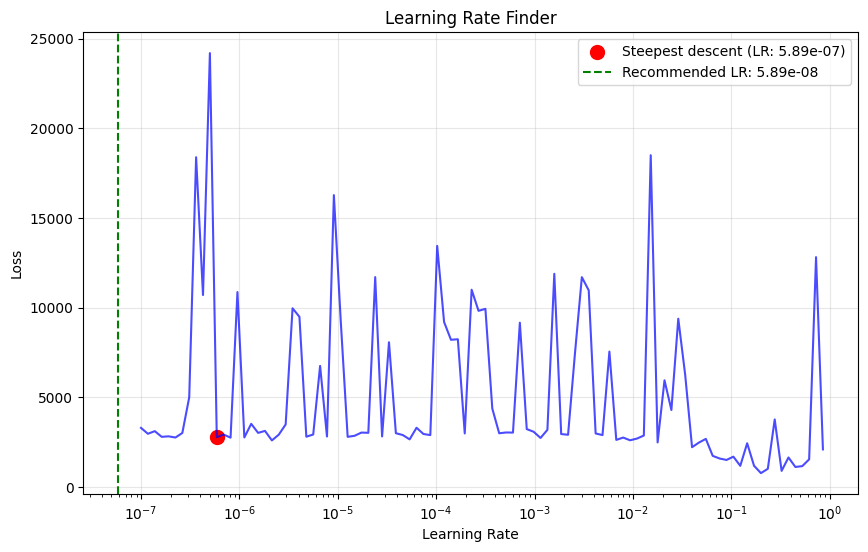

2026-03-14 16:33:42 | [4_162725] | INFO | 
✅ Current training_args.learning_rate = 5.89e-08


INFO:Awingi-ASR-awingi_xlsr_v1:
✅ Current training_args.learning_rate = 5.89e-08


In [ ]:
# @title
# Cell 12.6: Learning Rate Finder with Auto-Update
from torch.optim.lr_scheduler import LambdaLR
import math

def find_optimal_lr(model, train_dataset, processor, device,
                    start_lr=1e-7, end_lr=1, num_iter=100, auto_update=True):
    """
    Learning rate finder using the approach from fast.ai
    Gradually increases learning rate and tracks loss to find optimal range
    """
    drive_logger.logger.info("🔍 Starting Learning Rate Finder...")
    drive_logger.logger.info("="*60)

    # Create a small subset for LR finding (100 samples)
    import random
    random.seed(42)
    indices = random.sample(range(len(train_dataset)), min(100, len(train_dataset)))
    lr_find_dataset = train_dataset.select(indices)

    # Create data loader
    from torch.utils.data import DataLoader
    data_collator_lr = DataCollatorCTCWithPadding(processor=processor, padding=True)
    train_loader = DataLoader(
        lr_find_dataset,
        batch_size=1,
        shuffle=True,
        collate_fn=data_collator_lr
    )

    # Create optimizer
    optimizer = torch.optim.AdamW(model.parameters(), lr=start_lr)

    # Store losses and lrs
    losses = []
    lrs = []
    best_loss = float('inf')

    model.train()
    iteration = 0

    # Calculate multiplier for exponential increase
    multiplier = (end_lr / start_lr) ** (1/num_iter)

    drive_logger.logger.info(f"   Starting LR: {start_lr:.2e}")
    drive_logger.logger.info(f"   Ending LR: {end_lr:.2e}")
    drive_logger.logger.info(f"   Iterations: {num_iter}")
    drive_logger.logger.info("="*60)

    for batch in train_loader:
        if iteration >= num_iter:
            break

        # Move batch to device
        batch = {k: v.to(device) for k, v in batch.items()}

        # Forward pass
        outputs = model(**batch)
        loss = outputs.loss

        # Check for NaN/Inf
        if torch.isnan(loss) or torch.isinf(loss):
            drive_logger.logger.warning(f"   NaN/Inf detected at LR: {optimizer.param_groups[0]['lr']:.2e}")
            break

        # Store loss and LR
        current_lr = optimizer.param_groups[0]['lr']
        losses.append(loss.item())
        lrs.append(current_lr)

        # Track best loss
        if loss.item() < best_loss:
            best_loss = loss.item()

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Update learning rate (exponential increase)
        for param_group in optimizer.param_groups:
            param_group['lr'] *= multiplier

        if iteration % 20 == 0:
            drive_logger.logger.info(f"   Iter {iteration:3d} | LR: {current_lr:.2e} | Loss: {loss.item():.4f}")

        iteration += 1

    # Find optimal LR (point of steepest descent)
    if len(losses) > 2:
        # Smooth losses
        from scipy.ndimage import gaussian_filter1d
        smoothed = gaussian_filter1d(losses, sigma=1)

        # Find point of steepest descent
        gradients = np.gradient(smoothed)
        steepest_idx = np.argmin(gradients)

        # Get LR at that point (and divide by 10 for safety)
        optimal_lr = lrs[steepest_idx] / 10

        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"📊 Learning Rate Analysis Complete:")
        drive_logger.logger.info(f"   Recommended LR: {optimal_lr:.2e}")
        drive_logger.logger.info(f"   (Derived from steepest descent at LR: {lrs[steepest_idx]:.2e})")

        # Auto-update if requested
        if auto_update:
            global training_args
            training_args.learning_rate = optimal_lr
            drive_logger.logger.info(f"✅ Auto-updated training_args.learning_rate to {optimal_lr:.2e}")

        # Save plot
        try:
            import matplotlib.pyplot as plt
            plt.figure(figsize=(10, 6))
            plt.plot(lrs, losses, 'b-', alpha=0.7)
            plt.scatter(lrs[steepest_idx], losses[steepest_idx], color='red', s=100,
                       label=f'Steepest descent (LR: {lrs[steepest_idx]:.2e})')
            plt.axvline(optimal_lr, color='green', linestyle='--',
                       label=f'Recommended LR: {optimal_lr:.2e}')
            plt.xscale('log')
            plt.xlabel('Learning Rate')
            plt.ylabel('Loss')
            plt.title('Learning Rate Finder')
            plt.legend()
            plt.grid(True, alpha=0.3)

            save_path = drive_logger.exp_dir / "lr_finder_plot.png"
            plt.savefig(save_path, dpi=150)
            drive_logger.logger.info(f"   Plot saved to {save_path}")
            plt.show()
        except Exception as e:
            drive_logger.logger.warning(f"   Could not generate plot: {e}")

        return optimal_lr, lrs, losses
    else:
        drive_logger.logger.warning("⚠️ Not enough data points for LR analysis")
        return None, lrs, losses

# RUN THIS CELL TO FIND OPTIMAL LEARNING RATE
drive_logger.logger.info("="*60)
drive_logger.logger.info("🚀 RUNNING LEARNING RATE FINDER")
drive_logger.logger.info("="*60)

optimal_lr, lrs, losses = find_optimal_lr(
    model=model,
    train_dataset=processed_datasets['train'],
    processor=processor,
    device=device,
    start_lr=1e-7,
    end_lr=1,
    num_iter=100,
    auto_update=True  # Set to True to automatically update training_args
)

if optimal_lr:
    drive_logger.logger.info(f"\n✅ Current training_args.learning_rate = {training_args.learning_rate:.2e}")

# Now you can proceed to Cells 13 and 14 with the updated LR

# Cell 13: Trainer Setup with Resume Capability

In [ ]:
# @title
# Cell 13: Trainer Setup with Enhanced Resume Capability (FIXED)

import os
import glob
import json
from pathlib import Path
import torch
import pandas as pd
from transformers import Trainer
from transformers.trainer_utils import get_last_checkpoint

# ===== CHECKPOINT MANAGEMENT FUNCTIONS =====
def get_latest_checkpoint(output_dir):
    """Find the latest checkpoint in the output directory."""
    if not os.path.exists(output_dir):
        return None

    checkpoints = glob.glob(os.path.join(output_dir, "checkpoint-*"))
    if not checkpoints:
        return None

    try:
        latest = max(checkpoints, key=lambda x: int(x.split("-")[-1]))
        if os.path.exists(os.path.join(latest, "trainer_state.json")):
            return latest
    except (ValueError, IndexError):
        pass
    return None

def get_checkpoint_info(output_dir, drive_logger):
    """
    Enhanced checkpoint detection with session awareness
    Returns: (checkpoint_path, is_resume, step_to_resume)
    """
    if not os.path.exists(output_dir):
        drive_logger.logger.info(f"📁 Output directory {output_dir} does not exist yet")
        return None, False, 0

    # First, try to get the last checkpoint using HuggingFace's utility
    try:
        last_checkpoint = get_last_checkpoint(output_dir)
        if last_checkpoint is not None:
            step = int(last_checkpoint.split("-")[-1])
            drive_logger.logger.info(f"📌 Found HuggingFace checkpoint: step {step}")
            drive_logger.logger.info(f"   Path: {last_checkpoint}")

            # Record this checkpoint in logger for future reference
            drive_logger.save_last_checkpoint(step, last_checkpoint)

            return last_checkpoint, True, step
    except:
        pass

    # Fallback to our custom method
    checkpoints = glob.glob(os.path.join(output_dir, "checkpoint-*"))
    if not checkpoints:
        drive_logger.logger.info("📁 No checkpoints found in output directory")
        return None, False, 0

    try:
        # Get checkpoint with highest step number
        latest = max(checkpoints, key=lambda x: int(x.split("-")[-1]))
        step = int(latest.split("-")[-1])

        # Verify it's a valid checkpoint
        if os.path.exists(os.path.join(latest, "trainer_state.json")):
            drive_logger.logger.info(f"📌 Found latest checkpoint by step number: step {step}")
            drive_logger.logger.info(f"   Path: {latest}")

            # Record this checkpoint in logger for future reference
            drive_logger.save_last_checkpoint(step, latest)

            return latest, True, step
        else:
            drive_logger.logger.warning(f"⚠️ Checkpoint {latest} is missing trainer_state.json")

    except (ValueError, IndexError) as e:
        drive_logger.logger.warning(f"⚠️ Error parsing checkpoint: {e}")

    return None, False, 0

def verify_dataset_format(processed_datasets, drive_logger):
    """Verify dataset format and add length column if needed"""
    drive_logger.logger.info("\n🔍 Verifying dataset format...")

    # Check if datasets exist
    if 'train' not in processed_datasets:
        drive_logger.logger.error("❌ No training dataset found!")
        return processed_datasets

    # Add length columns for grouping if missing
    for split in ['train', 'val']:
        if split in processed_datasets:
            if 'input_length' not in processed_datasets[split].column_names:
                drive_logger.logger.info(f"📏 Adding length column to {split} split...")
                def add_length_column(sample):
                    sample['input_length'] = len(sample['input_values'])
                    return sample
                processed_datasets[split] = processed_datasets[split].map(add_length_column)
                drive_logger.logger.info(f"   ✅ Added input_length to {split} split")

    # Verify a few samples
    drive_logger.logger.info("\n📊 Sample verification:")
    for i in range(min(3, len(processed_datasets['train']))):
        sample = processed_datasets['train'][i]
        drive_logger.logger.info(f"  Sample {i}:")
        drive_logger.logger.info(f"    input_values type: {type(sample['input_values'])}")
        drive_logger.logger.info(f"    input_values length: {len(sample['input_values'])}")
        drive_logger.logger.info(f"    labels type: {type(sample['labels'])}")
        drive_logger.logger.info(f"    labels length: {len(sample['labels'])}")
        if len(sample['labels']) > 0:
            drive_logger.logger.info(f"    labels first 10: {sample['labels'][:10]}")

    return processed_datasets

# ===== MAIN SETUP CODE =====
drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info("🔄 TRAINER SETUP WITH ENHANCED RESUME CAPABILITY")
drive_logger.logger.info("="*70)

# Verify dataset format and add length columns if needed
processed_datasets = verify_dataset_format(processed_datasets, drive_logger)

# Get checkpoint information using enhanced method
checkpoint_path, is_resume, resume_step = get_checkpoint_info(training_args.output_dir, drive_logger)

# Log session information
drive_logger.logger.info(f"\n📋 Session Information:")
drive_logger.logger.info(f"   • Session ID: {drive_logger.session_id[-8:]}")
drive_logger.logger.info(f"   • Experiment: {drive_logger.experiment_name}")
drive_logger.logger.info(f"   • Output dir: {training_args.output_dir}")

if is_resume:
    drive_logger.logger.info(f"\n🔄 RESUME MODE ACTIVE")
    drive_logger.logger.info(f"   • Checkpoint: {checkpoint_path}")
    drive_logger.logger.info(f"   • Resuming from step: {resume_step}")
    drive_logger.logger.info(f"   • Previous sessions: {len(drive_logger.sessions) - 1}")

    # Log metrics summary from previous runs
    df = drive_logger.get_metrics_dataframe()
    if df is not None and not df.empty:
        # Get the latest metrics for this checkpoint step
        latest_metrics = df[df['step'] <= resume_step].iloc[-1] if len(df[df['step'] <= resume_step]) > 0 else None
        if latest_metrics is not None:
            drive_logger.logger.info(f"\n📊 Last recorded metrics at step {resume_step}:")
            if pd.notna(latest_metrics.get('eval_wer')):
                drive_logger.logger.info(f"   • Last WER: {latest_metrics['eval_wer']}")
            if pd.notna(latest_metrics.get('eval_loss')):
                drive_logger.logger.info(f"   • Last Eval Loss: {latest_metrics['eval_loss']}")
            if pd.notna(latest_metrics.get('train_loss')):
                drive_logger.logger.info(f"   • Last Train Loss: {latest_metrics['train_loss']}")
else:
    drive_logger.logger.info(f"\n🆕 FRESH START MODE")
    drive_logger.logger.info(f"   • No existing checkpoints found")
    drive_logger.logger.info(f"   • This is session {len(drive_logger.sessions)} for this experiment")

# IMPORTANT: Set environment variable to handle optimizer state mismatch
os.environ['TRANSFORMERS_OPTIMIZER_RESUME'] = 'force'  # This helps with optimizer state issues

# Recreate trainer with fixed datasets
drive_logger.logger.info("\n🤖 Initializing Trainer...")

# Create trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=processed_datasets['train'],
    eval_dataset=processed_datasets['val'],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[ProgressiveUnfreezeCallback(), DriveLoggingCallback(drive_logger)],
)

# Store checkpoint info in trainer for later use
trainer.resume_checkpoint = checkpoint_path if is_resume else None
trainer.is_resumed = is_resume
trainer.resume_step = resume_step if is_resume else 0

# IMPORTANT: If resuming, pre-load the trainer state from checkpoint
if is_resume and checkpoint_path:
    trainer_state_path = os.path.join(checkpoint_path, "trainer_state.json")
    if os.path.exists(trainer_state_path):
        try:
            with open(trainer_state_path, 'r') as f:
                trainer_state = json.load(f)

            # Set the trainer's internal state
            trainer.state.global_step = trainer_state.get('global_step', resume_step)
            trainer.state.epoch = trainer_state.get('epoch', 0)
            trainer.state.max_steps = trainer_state.get('max_steps', training_args.max_steps)

            drive_logger.logger.info(f"\n📊 Loaded trainer state from checkpoint:")
            drive_logger.logger.info(f"   • Global step: {trainer.state.global_step}")
            drive_logger.logger.info(f"   • Epoch: {trainer.state.epoch:.2f}")
        except Exception as e:
            drive_logger.logger.warning(f"⚠️ Could not load trainer state: {e}")

drive_logger.logger.info("✅ Trainer initialized successfully!")

# Optional: Show training configuration
drive_logger.logger.info("\n⚙️ Training Configuration:")
drive_logger.logger.info(f"   • Model: {model.__class__.__name__}")
drive_logger.logger.info(f"   • Train samples: {len(processed_datasets['train'])}")
drive_logger.logger.info(f"   • Val samples: {len(processed_datasets['val'])}")
drive_logger.logger.info(f"   • Batch size: {training_args.per_device_train_batch_size}")
drive_logger.logger.info(f"   • Gradient accumulation: {training_args.gradient_accumulation_steps}")
drive_logger.logger.info(f"   • Effective batch size: {training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps}")
drive_logger.logger.info(f"   • Learning rate: {training_args.learning_rate}")
drive_logger.logger.info(f"   • Max epochs: {training_args.num_train_epochs}")
drive_logger.logger.info(f"   • Save steps: {training_args.save_steps}")
drive_logger.logger.info(f"   • Eval steps: {training_args.eval_steps}")

# If resuming, warn about potential optimizer issues
if is_resume:
    drive_logger.logger.info("\n⚠️ NOTE: When resuming, you might encounter optimizer state mismatch.")
    drive_logger.logger.info("   The training loop in Cell 14 will handle this gracefully.")

drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info("✅ Cell 13 complete - Trainer is ready for Cell 14")
drive_logger.logger.info("="*70 + "\n")

2026-03-15 13:36:23 | [5_133253] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-03-15 13:36:23 | [5_133253] | INFO | 🔄 TRAINER SETUP WITH ENHANCED RESUME CAPABILITY


INFO:Awingi-ASR-awingi_xlsr_v1:🔄 TRAINER SETUP WITH ENHANCED RESUME CAPABILITY


2026-03-15 13:36:23 | [5_133253] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


... (102 outputs left out)

2026-03-15 13:36:27 | [5_133253] | INFO | ✅ Cell 13 complete - Trainer is ready for Cell 14


INFO:Awingi-ASR-awingi_xlsr_v1:✅ Cell 13 complete - Trainer is ready for Cell 14


2026-03-15 13:36:27 | [5_133253] | INFO | ======================================================================



INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================



# Cell 14: Sanity Check & Training

In [ ]:
# @title
# Cell 14: Sanity Check & Training (Fixed with Epoch Logging & Resume)

# Note: get_latest_checkpoint is defined in Cell 13 and available here

drive_logger.logger.info("🔍 Running sanity check...")

if len(processed_datasets['train']) > 0:
    sample = processed_datasets['train'][0]

    # Convert to tensor
    input_values = torch.tensor(sample["input_values"], dtype=torch.float32).unsqueeze(0).to(device)
    attention_mask = torch.ones_like(input_values, dtype=torch.long).to(device)

    with torch.no_grad():
        logits = model(input_values, attention_mask=attention_mask).logits
        pred_ids = torch.argmax(logits, dim=-1)

    drive_logger.logger.info("="*50)
    drive_logger.logger.info(f"Target:    {train_df.iloc[0]['sentence']}")
    drive_logger.logger.info(f"Prediction: {processor.batch_decode(pred_ids)[0]}")
    drive_logger.logger.info("="*50)

    # Check for NaN/INF
    has_inf = torch.any(torch.isinf(logits))
    has_nan = torch.any(torch.isnan(logits))

    if has_nan or has_inf:
        drive_logger.logger.error("❌ NaN/INF detected in forward pass! Training cannot proceed.")
        drive_logger.logger.error("   Check your audio preprocessing and model initialization.")
    else:
        drive_logger.logger.info("✅ Sanity check passed - starting training...")

        # Log training start with current state
        drive_logger.logger.info("="*60)
        drive_logger.logger.info("🚀 TRAINING BEGINS")
        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"Total epochs: {training_args.num_train_epochs}")
        drive_logger.logger.info(f"Batch size: {training_args.per_device_train_batch_size}")
        drive_logger.logger.info(f"Gradient accumulation: {training_args.gradient_accumulation_steps}")
        drive_logger.logger.info(f"Effective batch size: {training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps}")
        drive_logger.logger.info(f"Learning rate: {training_args.learning_rate}")
        drive_logger.logger.info(f"Checkpoint directory: {training_args.output_dir}")

        # Show current state if resuming
        resume_checkpoint = getattr(trainer, 'resume_checkpoint', None)
        if resume_checkpoint:
            drive_logger.logger.info(f"🔄 Resuming from checkpoint: {resume_checkpoint}")
            drive_logger.logger.info(f"   Current step: {trainer.state.global_step}")
            drive_logger.logger.info(f"   Current epoch: {trainer.state.epoch:.2f}")

            # Calculate and show progress
            if trainer.args.max_steps > 0:
                progress_pct = (trainer.state.global_step / trainer.args.max_steps) * 100
                drive_logger.logger.info(f"   Progress: {trainer.state.global_step}/{trainer.args.max_steps} steps ({progress_pct:.1f}%)")
        drive_logger.logger.info("="*60)

        # ===== ADD THIS: Setup best model saving =====
        BEST_MODEL_DIR = WORK_DIR / "best_model"
        BEST_MODEL_DIR.mkdir(exist_ok=True)
        best_wer = float('inf')

        class BestModelSaver(TrainerCallback):
            def __init__(self):
                self.best_wer = float('inf')

            def on_evaluate(self, args, state, control, metrics=None, **kwargs):
                if metrics and 'eval_wer' in metrics:
                    current_wer = metrics['eval_wer']
                    if current_wer < self.best_wer:
                        self.best_wer = current_wer
                        save_path = BEST_MODEL_DIR / f"best_model_step_{state.global_step}"
                        model.save_pretrained(save_path)
                        processor.save_pretrained(save_path)
                        drive_logger.logger.info(f"\n🏆 New best model saved! Step: {state.global_step}, WER: {current_wer:.4f}\n")

        trainer.add_callback(BestModelSaver())
        # ===== END OF ADDED CODE =====

        # Start training
        try:
            # Use the checkpoint from trainer.resume_checkpoint
            train_result = trainer.train(resume_from_checkpoint=trainer.resume_checkpoint)

            # Log training completed
            drive_logger.logger.info("="*60)
            drive_logger.logger.info("✅ TRAINING COMPLETED")
            drive_logger.logger.info("="*60)
            drive_logger.logger.info(f"Final training loss: {train_result.training_loss:.4f}")
            drive_logger.logger.info(f"Total steps: {train_result.global_step}")
            drive_logger.logger.info(f"Total epochs: {train_result.epoch:.2f}")

            # Evaluate on test set
            drive_logger.logger.info("\n📊 Evaluating on test set...")
            test_results = trainer.evaluate(eval_dataset=processed_datasets['test'])
            drive_logger.logger.info(f"Test WER: {test_results['eval_wer']:.4f}")
            drive_logger.logger.info(f"Test CER: {test_results['eval_cer']:.4f}")
            drive_logger.logger.info(f"Test loss: {test_results['eval_loss']:.4f}")

            # Save final model
            drive_logger.logger.info("\n💾 Saving final model...")
            save_path = f"{MODEL_DIR}/Awingi_ASR_XLSR_Model_final"
            trainer.save_model(save_path)
            processor.save_pretrained(save_path)

            # Save final metrics
            final_metrics = {
                'train_loss': train_result.training_loss,
                'test_wer': test_results['eval_wer'],
                'test_cer': test_results['eval_cer'],
                'test_loss': test_results['eval_loss'],
                'global_step': train_result.global_step,
                'epochs': train_result.epoch
            }
            drive_logger.save_model_info(model, processor, final_metrics)

            drive_logger.logger.info(f"✅ Final model saved to {save_path}")

        except ValueError as e:
            if "loaded state dict contains a parameter group that doesn't match" in str(e):
                drive_logger.logger.warning("\n⚠️ Optimizer state mismatch detected!")
                drive_logger.logger.warning("   This is common when resuming with different optimizer settings.")
                drive_logger.logger.warning("   Attempting to continue with current model state...")

                # Continue training without resuming (just use current model state)
                # But first make sure we're at the correct step
                drive_logger.logger.info(f"   Continuing from step {trainer.state.global_step}, epoch {trainer.state.epoch:.2f}")

                train_result = trainer.train(resume_from_checkpoint=None)

                # Process results normally
                drive_logger.logger.info("="*60)
                drive_logger.logger.info("✅ TRAINING COMPLETED")
                drive_logger.logger.info("="*60)
                drive_logger.logger.info(f"Final training loss: {train_result.training_loss:.4f}")
                drive_logger.logger.info(f"Total steps: {train_result.global_step}")
                drive_logger.logger.info(f"Total epochs: {train_result.epoch:.2f}")

                # Evaluate on test set
                drive_logger.logger.info("\n📊 Evaluating on test set...")
                test_results = trainer.evaluate(eval_dataset=processed_datasets['test'])
                drive_logger.logger.info(f"Test WER: {test_results['eval_wer']:.4f}")
                drive_logger.logger.info(f"Test CER: {test_results['eval_cer']:.4f}")
                drive_logger.logger.info(f"Test loss: {test_results['eval_loss']:.4f}")

                # Save final model
                drive_logger.logger.info("\n💾 Saving final model...")
                save_path = f"{MODEL_DIR}/Awingi_ASR_XLSR_Model_final"
                trainer.save_model(save_path)
                processor.save_pretrained(save_path)

                # Save final metrics
                final_metrics = {
                    'train_loss': train_result.training_loss,
                    'test_wer': test_results['eval_wer'],
                    'test_cer': test_results['eval_cer'],
                    'test_loss': test_results['eval_loss'],
                    'global_step': train_result.global_step,
                    'epochs': train_result.epoch
                }
                drive_logger.save_model_info(model, processor, final_metrics)

                drive_logger.logger.info(f"✅ Final model saved to {save_path}")
            else:
                raise

        except KeyboardInterrupt:
            # Handle manual interruption (Colab session timeout)
            drive_logger.logger.warning("⚠️ Training interrupted! Saving checkpoint...")

            # Save current state
            current_step = trainer.state.global_step
            current_epoch = trainer.state.epoch
            drive_logger.logger.info(f"📊 Current progress: Step {current_step}, Epoch {current_epoch:.2f}")

            # Save checkpoint
            checkpoint_path = f"{MODEL_DIR}/checkpoint-interrupted-step-{current_step}"
            trainer.save_model(checkpoint_path)
            drive_logger.logger.info(f"✅ Checkpoint saved to {checkpoint_path}")
            drive_logger.logger.info("🔄 To resume, run this cell again - it will automatically resume from the latest checkpoint")

        except Exception as e:
            drive_logger.logger.error(f"❌ Training failed with error: {str(e)}")
            import traceback
            traceback.print_exc()

        finally:
            # Always save latest checkpoint info
            drive_logger.logger.info("="*60)
            drive_logger.logger.info("📌 TRAINING SESSION ENDED")
            drive_logger.logger.info("="*60)
            latest = get_latest_checkpoint(training_args.output_dir)
            drive_logger.logger.info(f"Last checkpoint: {latest}")
            drive_logger.logger.info("To resume training, simply run this cell again.")

        # Clear memory
        del input_values, attention_mask, logits, pred_ids
        torch.cuda.empty_cache()
else:
    drive_logger.logger.error("❌ No training samples available!")

2026-03-15 13:36:36 | [5_133253] | INFO | 🔍 Running sanity check...


INFO:Awingi-ASR-awingi_xlsr_v1:🔍 Running sanity check...


2026-03-15 13:36:38 | [5_133253] | INFO | ==================================================


INFO:Awingi-ASR-awingi_xlsr_v1:==================================================


2026-03-15 13:36:38 | [5_133253] | INFO | Target:    ሚፂ ንጝ ዳር ንጝይ ቕፕ ናማ ሚፂ ሚፂ ንጝ ጚኾቺያኽ


INFO:Awingi-ASR-awingi_xlsr_v1:Target:    ሚፂ ንጝ ዳር ንጝይ ቕፕ ናማ ሚፂ ሚፂ ንጝ ጚኾቺያኽ


... (150 outputs left out)

2026-03-15 14:30:25 | [5_133253] | INFO | Step 23500 | Epoch  14.24 | GPU: 3.52GB | 💾 Checkpoint saved | save_trigger: on_save_callback


INFO:Awingi-ASR-awingi_xlsr_v1:Step 23500 | Epoch  14.24 | GPU: 3.52GB | 💾 Checkpoint saved | save_trigger: on_save_callback


2026-03-15 14:32:11 | [5_133253] | INFO | Step 23550 | Epoch  14.27 | Train Loss: 3.5478 | LR: 0.000005 | GPU: 3.52GB | grad_norm: 25.8683 | max_memory: None


INFO:Awingi-ASR-awingi_xlsr_v1:Step 23550 | Epoch  14.27 | Train Loss: 3.5478 | LR: 0.000005 | GPU: 3.52GB | grad_norm: 25.8683 | max_memory: None


# Cell 15.6: Test without LM

2026-03-15 20:12:46 | [5_200607] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-03-15 20:12:46 | [5_200607] | INFO | 🚀 STARTING MODEL TESTING


INFO:Awingi-ASR-awingi_xlsr_v1:🚀 STARTING MODEL TESTING


2026-03-15 20:12:46 | [5_200607] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


... (83 outputs left out)

2026-03-15 20:16:54 | [5_200607] | INFO | ================================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:================================================================================


+-----+-------------------------------------------------------+-------------------------------------------------------+---------+--------------+
|   # | Target                                                | Prediction                                            | Match   |   Similarity |
+=====+=======================================================+=======================================================+=========+==============+
|  13 | ፂኪጙ ጄሜርቱ ኢትዮኘያኽ                                       | ፂኪጙ ጄሜርቱ ኢትዮኘያኽ                                       | ✅      |         1    |
+-----+-------------------------------------------------------+-------------------------------------------------------+---------+--------------+
|  61 | አዝጋድኩ ጄርካኪላ ሻይ ላጛ ሊኻ ላጛርጛ ላጛ                          | አጋያዝኩ ጄርካኪላ ሻይ ላጛ ሊኻ ላጛርጛ ላጛ                          | ❌      |         0.96 |
+-----+-------------------------------------------------------+-------------------------------------------------------+---------+---

INFO:Awingi-ASR-awingi_xlsr_v1:📊 Plot saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/error_analysis_step_24500.png


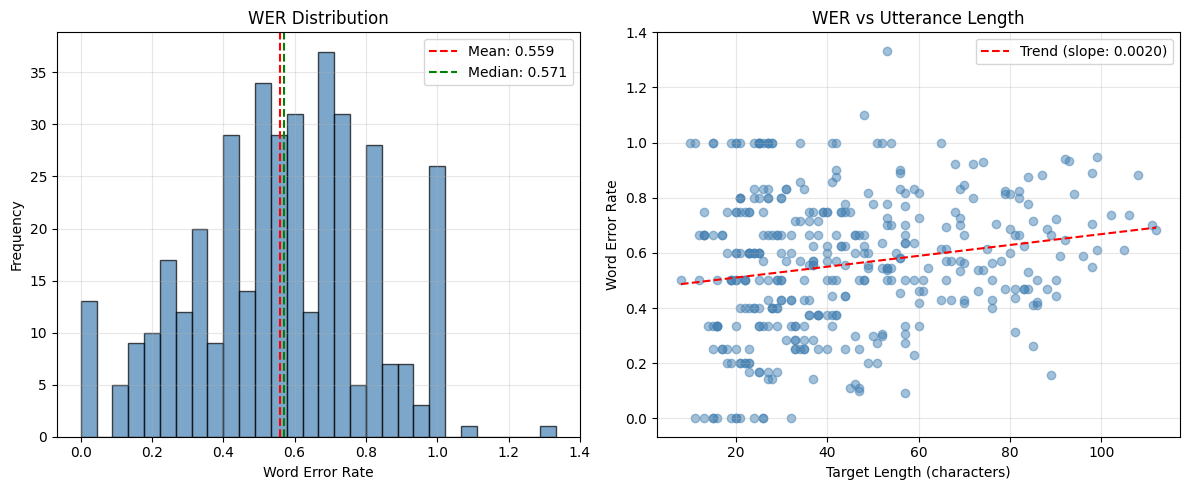

2026-03-15 20:16:57 | [5_200607] | INFO | 
💾 Test summary saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/test_summary_step_24500.json


INFO:Awingi-ASR-awingi_xlsr_v1:
💾 Test summary saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1/test_summary_step_24500.json


2026-03-15 20:16:57 | [5_200607] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-03-15 20:16:57 | [5_200607] | INFO | ✅ TESTING COMPLETE


INFO:Awingi-ASR-awingi_xlsr_v1:✅ TESTING COMPLETE


... (4 outputs left out)

2026-03-15 20:16:57 | [5_200607] | INFO | 📊 Final Test Character Accuracy: 0.4246


INFO:Awingi-ASR-awingi_xlsr_v1:📊 Final Test Character Accuracy: 0.4246


2026-03-15 20:16:57 | [5_200607] | INFO | 📁 Results saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1


INFO:Awingi-ASR-awingi_xlsr_v1:📁 Results saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/training_logs/awingi_xlsr_v1


In [ ]:
# @title
# Cell 15: Model Testing & Evaluation
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
from tabulate import tabulate
import random
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import Levenshtein

def load_best_model(model_dir, processor, device):
    """Load the best model from checkpoints based on validation WER"""
    drive_logger.logger.info("="*60)
    drive_logger.logger.info("🔍 LOADING BEST MODEL FOR TESTING")
    drive_logger.logger.info("="*60)

    # Get all checkpoints
    checkpoints = glob.glob(os.path.join(model_dir, "checkpoint-*"))
    if not checkpoints:
        drive_logger.logger.error("❌ No checkpoints found!")
        return None

    # Load trainer states to find best WER
    best_wer = float('inf')
    best_checkpoint = None
    best_metrics = {}

    for checkpoint in tqdm(checkpoints, desc="Analyzing checkpoints"):
        trainer_state_path = os.path.join(checkpoint, "trainer_state.json")
        if os.path.exists(trainer_state_path):
            with open(trainer_state_path, 'r') as f:
                state = json.load(f)
                if 'best_metric' in state and state['best_metric'] < best_wer:
                    best_wer = state['best_metric']
                    best_checkpoint = checkpoint
                    best_metrics = {
                        'step': state.get('global_step', 'N/A'),
                        'epoch': state.get('epoch', 'N/A'),
                        'wer': state['best_metric']
                    }

    if best_checkpoint:
        drive_logger.logger.info(f"\n✅ Best checkpoint found:")
        drive_logger.logger.info(f"   • Path: {best_checkpoint}")
        drive_logger.logger.info(f"   • Step: {best_metrics['step']}")
        drive_logger.logger.info(f"   • Epoch: {best_metrics['epoch']:.2f}")
        drive_logger.logger.info(f"   • Validation WER: {best_metrics['wer']:.4f}")

        # Load model
        from transformers import Wav2Vec2ForCTC
        model = Wav2Vec2ForCTC.from_pretrained(best_checkpoint).to(device)
        drive_logger.logger.info("✅ Model loaded successfully!")
        return model, best_checkpoint, best_metrics
    else:
        drive_logger.logger.error("❌ No valid checkpoint found!")
        return None, None, None

def transcribe_audio(model, processor, audio_path, device):
    """Transcribe a single audio file"""
    try:
        # Load and preprocess audio
        import soundfile as sf
        audio, sr = sf.read(audio_path)

        # Convert to mono if stereo
        if len(audio.shape) > 1:
            audio = audio.mean(axis=-1)

        # Resample to 16kHz if needed
        if sr != 16000:
            import torchaudio
            audio = torchaudio.functional.resample(
                torch.tensor(audio),
                sr,
                16000
            ).numpy()

        # Process with feature extractor
        inputs = processor(audio, sampling_rate=16000, return_tensors="pt").to(device)

        # Inference
        with torch.no_grad():
            logits = model(inputs.input_values).logits
            pred_ids = torch.argmax(logits, dim=-1)

        # Decode
        transcription = processor.batch_decode(pred_ids)[0]
        return transcription

    except Exception as e:
        drive_logger.logger.error(f"❌ Error transcribing {audio_path}: {e}")
        return None

def test_model_on_split(model, processor, test_df, device, num_samples=None, random_seed=42):
    """
    Test model on a dataset split and show detailed comparisons

    Args:
        model: Loaded model
        processor: Wav2Vec2Processor
        test_df: DataFrame with 'path' and 'sentence' columns
        device: torch device
        num_samples: Number of samples to test (None for all)
        random_seed: Random seed for sampling
    """
    drive_logger.logger.info("\n" + "="*60)
    drive_logger.logger.info("📊 DETAILED MODEL TESTING")
    drive_logger.logger.info("="*60)

    # Sample if requested
    if num_samples and num_samples < len(test_df):
        random.seed(random_seed)
        test_df = test_df.sample(n=num_samples, random_state=random_seed)
        drive_logger.logger.info(f"🎲 Testing on {num_samples} random samples (seed={random_seed})")
    else:
        drive_logger.logger.info(f"📊 Testing on all {len(test_df)} samples")

    results = []
    errors = []

    # Progress bar
    for idx, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Testing"):
        audio_path = row['path']
        target = row['sentence']

        # Transcribe
        prediction = transcribe_audio(model, processor, audio_path, device)

        if prediction is not None:
            # Calculate WER for this sample
            from evaluate import load
            wer_metric = load("wer")
            wer = wer_metric.compute(predictions=[prediction], references=[target])

            # Calculate character accuracy
            correct_chars = sum(1 for a, b in zip(prediction, target) if a == b)
            total_chars = max(len(prediction), len(target))
            char_acc = correct_chars / total_chars if total_chars > 0 else 0

            results.append({
                'audio_path': audio_path,
                'target': target,
                'prediction': prediction,
                'wer': wer,
                'char_acc': char_acc,
                'target_len': len(target),
                'pred_len': len(prediction)
            })
        else:
            errors.append(audio_path)

    # Create results DataFrame
    results_df = pd.DataFrame(results)

    # Calculate overall metrics
    if len(results_df) > 0:
        avg_wer = results_df['wer'].mean()
        avg_char_acc = results_df['char_acc'].mean()
        median_wer = results_df['wer'].median()

        drive_logger.logger.info("\n" + "="*60)
        drive_logger.logger.info("📈 OVERALL TEST METRICS")
        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"   • Samples tested: {len(results_df)}")
        drive_logger.logger.info(f"   • Average WER: {avg_wer:.4f}")
        drive_logger.logger.info(f"   • Median WER: {median_wer:.4f}")
        drive_logger.logger.info(f"   • Average Character Accuracy: {avg_char_acc:.4f}")
        drive_logger.logger.info(f"   • Failed samples: {len(errors)}")

        # Best and worst predictions
        best_idx = results_df['wer'].idxmin()
        worst_idx = results_df['wer'].idxmax()

        drive_logger.logger.info("\n" + "="*60)
        drive_logger.logger.info("🏆 BEST PREDICTION (Lowest WER)")
        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"   WER: {results_df.loc[best_idx, 'wer']:.4f}")
        drive_logger.logger.info(f"   Target:    {results_df.loc[best_idx, 'target']}")
        drive_logger.logger.info(f"   Prediction: {results_df.loc[best_idx, 'prediction']}")

        drive_logger.logger.info("\n" + "="*60)
        drive_logger.logger.info("📉 WORST PREDICTION (Highest WER)")
        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"   WER: {results_df.loc[worst_idx, 'wer']:.4f}")
        drive_logger.logger.info(f"   Target:    {results_df.loc[worst_idx, 'target']}")
        drive_logger.logger.info(f"   Prediction: {results_df.loc[worst_idx, 'prediction']}")

        # Error analysis by length
        drive_logger.logger.info("\n" + "="*60)
        drive_logger.logger.info("📊 ERROR ANALYSIS BY UTTERANCE LENGTH")
        drive_logger.logger.info("="*60)

        # Bin by target length
        bins = [0, 20, 40, 60, 80, 100, float('inf')]
        labels = ['0-20', '21-40', '41-60', '61-80', '81-100', '100+']
        results_df['length_bin'] = pd.cut(results_df['target_len'], bins=bins, labels=labels)

        length_stats = results_df.groupby('length_bin').agg({
            'wer': ['mean', 'count']
        }).round(4)

        drive_logger.logger.info("\n" + tabulate(length_stats, headers=['Length', 'Avg WER', 'Count'], tablefmt='grid'))

        # Save detailed results
        save_path = drive_logger.exp_dir / f"test_results_step_{best_metrics['step']}.csv"
        results_df.to_csv(save_path, index=False)
        drive_logger.logger.info(f"\n💾 Detailed results saved to: {save_path}")

        return results_df
    else:
        drive_logger.logger.error("❌ No valid results obtained!")
        return None

def show_sample_predictions(model, processor, test_df, device, num_examples=10):
    """Display sample predictions in a formatted table"""
    drive_logger.logger.info("\n" + "="*80)
    drive_logger.logger.info("📋 SAMPLE PREDICTIONS")
    drive_logger.logger.info("="*80)

    # Random sample
    samples = test_df.sample(n=min(num_examples, len(test_df)))

    table_data = []
    for idx, row in samples.iterrows():
        prediction = transcribe_audio(model, processor, row['path'], device)

        # Calculate match indicators
        target = row['sentence']
        exact_match = "✅" if prediction == target else "❌"

        # Simple similarity (character overlap)
        if prediction:
            common = sum(1 for c in prediction if c in target)
            similarity = common / max(len(target), len(prediction)) if max(len(target), len(prediction)) > 0 else 0
        else:
            similarity = 0

        table_data.append([
            idx,
            target[:50] + "..." if len(target) > 50 else target,
            prediction[:50] + "..." if prediction and len(prediction) > 50 else (prediction if prediction else "[EMPTY]"),
            exact_match,
            f"{similarity:.2f}"
        ])

    headers = ['#', 'Target', 'Prediction', 'Match', 'Similarity']
    print(tabulate(table_data, headers=headers, tablefmt='grid'))

    return table_data

def plot_error_distribution(results_df, save_path=None):
    """Plot WER distribution"""
    try:
        plt.figure(figsize=(12, 5))

        # WER distribution
        plt.subplot(1, 2, 1)
        plt.hist(results_df['wer'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
        plt.axvline(results_df['wer'].mean(), color='red', linestyle='--', label=f'Mean: {results_df["wer"].mean():.3f}')
        plt.axvline(results_df['wer'].median(), color='green', linestyle='--', label=f'Median: {results_df["wer"].median():.3f}')
        plt.xlabel('Word Error Rate')
        plt.ylabel('Frequency')
        plt.title('WER Distribution')
        plt.legend()
        plt.grid(True, alpha=0.3)

        # WER vs Length
        plt.subplot(1, 2, 2)
        plt.scatter(results_df['target_len'], results_df['wer'], alpha=0.5, color='steelblue')
        plt.xlabel('Target Length (characters)')
        plt.ylabel('Word Error Rate')
        plt.title('WER vs Utterance Length')
        plt.grid(True, alpha=0.3)

        # Add trend line
        if len(results_df) > 1:
            z = np.polyfit(results_df['target_len'], results_df['wer'], 1)
            p = np.poly1d(z)
            plt.plot(sorted(results_df['target_len']), p(sorted(results_df['target_len'])),
                     'r--', label=f'Trend (slope: {z[0]:.4f})')
            plt.legend()

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, dpi=150)
            drive_logger.logger.info(f"📊 Plot saved to: {save_path}")
        plt.show()

    except Exception as e:
        drive_logger.logger.warning(f"⚠️ Could not generate plots: {e}")

# ===== MAIN TESTING EXECUTION =====
drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info("🚀 STARTING MODEL TESTING")
drive_logger.logger.info("="*70)

# Check if test dataset exists
if 'test_df' not in locals() and 'test_df' not in globals():
    try:
        test_df = pd.read_csv(TEST_CSV)
        drive_logger.logger.info(f"✅ Loaded test set: {len(test_df)} samples")
    except:
        drive_logger.logger.error("❌ Could not load test dataset!")
        raise

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
drive_logger.logger.info(f"🖥 Using device: {device}")

# Load best model
model, checkpoint_path, best_metrics = load_best_model(MODEL_DIR, processor, device)

if model is not None:
    # Test configuration
    TEST_ALL_SAMPLES = True  # Set to False for quick testing
    NUM_SAMPLES = 50 if not TEST_ALL_SAMPLES else None

    # Run comprehensive testing
    results_df = test_model_on_split(
        model=model,
        processor=processor,
        test_df=test_df,
        device=device,
        num_samples=NUM_SAMPLES,
        random_seed=42
    )

    if results_df is not None:
        # Show sample predictions
        show_sample_predictions(
            model=model,
            processor=processor,
            test_df=test_df,
            device=device,
            num_examples=15
        )

        # Plot error distribution
        plot_path = drive_logger.exp_dir / f"error_analysis_step_{best_metrics['step']}.png"
        plot_error_distribution(results_df, save_path=plot_path)

        # Save summary
        summary = {
            'model_path': checkpoint_path,
            'step': best_metrics['step'],
            'epoch': best_metrics['epoch'],
            'validation_wer': best_metrics['wer'],
            'test_metrics': {
                'avg_wer': float(results_df['wer'].mean()),
                'median_wer': float(results_df['wer'].median()),
                'std_wer': float(results_df['wer'].std()),
                'avg_char_acc': float(results_df['char_acc'].mean()),
                'samples_tested': len(results_df)
            }
        }

        summary_path = drive_logger.exp_dir / f"test_summary_step_{best_metrics['step']}.json"
        with open(summary_path, 'w') as f:
            json.dump(summary, f, indent=2)
        drive_logger.logger.info(f"\n💾 Test summary saved to: {summary_path}")

        # Final output
        drive_logger.logger.info("\n" + "="*70)
        drive_logger.logger.info("✅ TESTING COMPLETE")
        drive_logger.logger.info("="*70)
        drive_logger.logger.info(f"📊 Final Test WER: {summary['test_metrics']['avg_wer']:.4f}")
        drive_logger.logger.info(f"📊 Final Test Character Accuracy: {summary['test_metrics']['avg_char_acc']:.4f}")
        drive_logger.logger.info(f"📁 Results saved to: {drive_logger.exp_dir}")

# Cell 15.7: Install Packages For LM

In [ ]:
# @title
# Cell 15.5: Install KenLM and Dependencies
!pip install Levenshtein
!pip install pyctcdecode
!pip install evaluate
!pip install jiwer
import os
import subprocess
import sys

def install_kenlm():
    """Install KenLM and required dependencies"""
    print("="*60)
    print("🔧 INSTALLING KENLM LANGUAGE MODEL TOOLKIT")
    print("="*60)

    # Install system dependencies
    print("\n📦 Installing system dependencies...")
    deps_cmd = [
        'apt-get', 'install', '-y',
        'build-essential', 'cmake',
        'libboost-system-dev', 'libboost-thread-dev',
        'libboost-program-options-dev', 'libboost-test-dev',
        'libeigen3-dev', 'zlib1g-dev', 'libbz2-dev', 'liblzma-dev'
    ]

    try:
        subprocess.run(deps_cmd, check=True, capture_output=True)
        print("   ✅ System dependencies installed")
    except subprocess.CalledProcessError as e:
        print(f"   ⚠️ Warning: {e}")

    # Download and build KenLM
    print("\n🔨 Building KenLM from source...")

    # Clone KenLM repository
    if not os.path.exists('kenlm'):
        subprocess.run(['git', 'clone', 'https://github.com/kpu/kenlm.git'], check=True)
        print("   ✅ KenLM repository cloned")

    # Build KenLM
    os.chdir('kenlm')
    if not os.path.exists('build'):
        os.makedirs('build')

    os.chdir('build')

    # Configure with cmake
    subprocess.run(['cmake', '..'], check=True, capture_output=True)

    # Build with make
    subprocess.run(['make', '-j', '4'], check=True)
    print("   ✅ KenLM built successfully")

    # Add to PATH
    os.chdir('../..')
    kenlm_bin_path = os.path.abspath('kenlm/build/bin')
    os.environ['PATH'] = f"{kenlm_bin_path}:{os.environ['PATH']}"

    # Install Python bindings
    print("\n🐍 Installing Python bindings...")
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'https://github.com/kpu/kenlm/archive/master.zip'],
                   check=True, capture_output=True)
    print("   ✅ Python bindings installed")

    # Verify installation
    print("\n🔍 Verifying installation...")
    try:
        result = subprocess.run(['lmplz', '--help'], capture_output=True, text=True)
        if result.returncode == 0 or "Usage" in result.stderr:
            print("   ✅ lmplz is available")
    except:
        # Try with full path
        lmplz_path = os.path.join(kenlm_bin_path, 'lmplz')
        if os.path.exists(lmplz_path):
            print(f"   ✅ lmplz found at {lmplz_path}")
            os.environ['PATH'] = f"{kenlm_bin_path}:{os.environ['PATH']}"

    print("\n" + "="*60)
    print("✅ KENLM INSTALLATION COMPLETE")
    print("="*60)

    return kenlm_bin_path

# Run installation
kenlm_bin_path = install_kenlm()

# Verify lmplz is in PATH
import shutil
lmplz_path = shutil.which('lmplz')
if lmplz_path:
    print(f"\n✅ lmplz found at: {lmplz_path}")
else:
    print("\n⚠️ lmplz not found in PATH, but should be at:", os.path.join(kenlm_bin_path, 'lmplz'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 6.6 MB/s eta 0:00:00
🔧 INSTALLING KENLM LANGUAGE MODEL TOOLKIT

📦 Installing system dependencies...
   ✅ System dependencies installed

🔨 Building KenLM from source...
   ✅ KenLM repository cloned
   ✅ KenLM built successfully

🐍 Installing Python bindings...
   ✅ Python bindings installed

🔍 Verifying installation...

✅ KENLM INSTALLATION COMPLETE

✅ lmplz found at: /content/kenlm/build/bin/lmplz


# Cell 15.8: Test With KenLM

In [ ]:
# @title
# Cell 16: KenLM Language Model Integration
import os
import subprocess
import gzip
import math
from collections import Counter
import kenlm
import numpy as np

class AwingiLanguageModel:
    """
    Configurable n-gram language model for Awingi ASR using KenLM
    """
    def __init__(self, drive_logger, order=3, smoothing='kneser_ney'):
        """
        Initialize language model with configurable n-gram order

        Args:
            drive_logger: Logger instance
            order: n-gram order (2=bigram, 3=trigram, 4=4-gram, etc.)
            smoothing: Smoothing method (Note: KenLM uses Kneser-Ney by default)
        """
        self.drive_logger = drive_logger
        self.order = order
        self.smoothing = smoothing
        self.model = None
        self.vocab_size = 0

        # Paths
        self.lm_dir = WORK_DIR / "language_model"
        self.lm_dir.mkdir(parents=True, exist_ok=True)

        self.text_corpus_path = self.lm_dir / f"awingi_corpus_order{order}.txt"
        self.arpa_path = self.lm_dir / f"awingi_{order}gram.arpa"
        self.binary_path = self.lm_dir / f"awingi_{order}gram.klm"

        self.drive_logger.logger.info(f"\n{'='*60}")
        self.drive_logger.logger.info(f"📚 Initializing KenLM Language Model")
        self.drive_logger.logger.info(f"   • Order: {order}-gram")
        self.drive_logger.logger.info(f"   • Smoothing: {smoothing} (Kneser-Ney is default)")
        self.drive_logger.logger.info(f"{'='*60}")

    def prepare_corpus(self, train_df, val_df=None, max_length=100):
        """
        Prepare text corpus from training and validation transcripts

        Args:
            train_df: Training dataframe with 'sentence' column
            val_df: Optional validation dataframe
            max_length: Maximum sentence length to include
        """
        self.drive_logger.logger.info("\n📝 Preparing text corpus...")

        all_texts = []

        # Add training texts
        train_texts = train_df['sentence'].dropna().tolist()
        all_texts.extend(train_texts)
        self.drive_logger.logger.info(f"   • Added {len(train_texts)} training sentences")

        # Add validation texts if provided
        if val_df is not None:
            val_texts = val_df['sentence'].dropna().tolist()
            all_texts.extend(val_texts)
            self.drive_logger.logger.info(f"   • Added {len(val_texts)} validation sentences")

        # Filter by length
        original_count = len(all_texts)
        all_texts = [t for t in all_texts if len(t.split()) <= max_length]
        self.drive_logger.logger.info(f"   • Filtered from {original_count} to {len(all_texts)} sentences (max {max_length} words)")

        # Write to file
        with open(self.text_corpus_path, 'w', encoding='utf-8') as f:
            for text in all_texts:
                # Basic normalization: ensure spaces around punctuation
                normalized = ' '.join(text.split())
                f.write(normalized + '\n')

        # Calculate vocabulary
        all_words = ' '.join(all_texts).split()
        self.vocab_size = len(set(all_words))

        self.drive_logger.logger.info(f"   • Corpus saved to: {self.text_corpus_path}")
        self.drive_logger.logger.info(f"   • Vocabulary size: {self.vocab_size} words")
        self.drive_logger.logger.info(f"   • Total words: {len(all_words):,}")

        return self.text_corpus_path

    def build_arpa_model(self, prune_thresholds=None):
        """
        Build ARPA format language model using KenLM

        Args:
            prune_thresholds: List of thresholds for pruning [unigram, bigram, trigram, ...]
                             e.g., [1, 2, 3] for order=3
        """
        self.drive_logger.logger.info("\n🔨 Building ARPA language model...")

        # Check if corpus exists
        if not self.text_corpus_path.exists():
            raise FileNotFoundError(f"Corpus not found: {self.text_corpus_path}")

        # Build command - NOTE: KenLM uses Kneser-Ney by default, no special flag needed
        cmd = [
            'lmplz',
            '-o', str(self.order),
            '--text', str(self.text_corpus_path),
            '--arpa', str(self.arpa_path)
        ]

        # Add pruning if specified
        if prune_thresholds:
            cmd.append('--prune')
            cmd.extend([str(t) for t in prune_thresholds[:self.order]])

        self.drive_logger.logger.info(f"   • Command: {' '.join(cmd)}")

        try:
            # Run lmplz
            result = subprocess.run(cmd, capture_output=True, text=True, check=True)
            self.drive_logger.logger.info(f"   ✅ ARPA model built successfully")
            self.drive_logger.logger.info(f"   • Model saved to: {self.arpa_path}")

            # Log model size
            if self.arpa_path.exists():
                size_mb = self.arpa_path.stat().st_size / (1024 * 1024)
                self.drive_logger.logger.info(f"   • ARPA size: {size_mb:.2f} MB")

        except subprocess.CalledProcessError as e:
            self.drive_logger.logger.error(f"❌ Failed to build ARPA model: {e}")
            if e.stdout:
                self.drive_logger.logger.error(f"   stdout: {e.stdout}")
            if e.stderr:
                self.drive_logger.logger.error(f"   stderr: {e.stderr}")
            raise

    def build_binary_model(self):
        """Convert ARPA model to binary format for faster loading"""
        self.drive_logger.logger.info("\n🔄 Converting to binary format...")

        if not self.arpa_path.exists():
            raise FileNotFoundError(f"ARPA file not found: {self.arpa_path}")

        cmd = [
            'build_binary',
            '-i',  # Include special symbols
            str(self.arpa_path),
            str(self.binary_path)
        ]

        try:
            result = subprocess.run(cmd, capture_output=True, text=True, check=True)
            self.drive_logger.logger.info(f"   ✅ Binary model built successfully")
            self.drive_logger.logger.info(f"   • Binary saved to: {self.binary_path}")

            # Log model size
            if self.binary_path.exists():
                size_mb = self.binary_path.stat().st_size / (1024 * 1024)
                self.drive_logger.logger.info(f"   • Binary size: {size_mb:.2f} MB")

        except subprocess.CalledProcessError as e:
            self.drive_logger.logger.error(f"❌ Failed to build binary model: {e}")
            raise

    def load_model(self):
        """Load the binary language model"""
        self.drive_logger.logger.info("\n📥 Loading language model...")

        if not self.binary_path.exists():
            # Try to build binary from ARPA
            if self.arpa_path.exists():
                self.build_binary_model()
            else:
                raise FileNotFoundError(f"No model found at {self.binary_path}")

        try:
            self.model = kenlm.Model(str(self.binary_path))
            self.drive_logger.logger.info(f"   ✅ Model loaded successfully")
            self.drive_logger.logger.info(f"   • Order: {self.order}")
            self.drive_logger.logger.info(f"   • Vocabulary size: {self.vocab_size}")

            # Test with a sample sentence
            test_sentence = "አበበ በሶ በላ"
            score = self.score_sentence(test_sentence)
            self.drive_logger.logger.info(f"   • Test score for '{test_sentence}': {score:.4f}")

        except Exception as e:
            self.drive_logger.logger.error(f"❌ Failed to load model: {e}")
            raise

    def score_sentence(self, sentence):
        """Get log probability score for a sentence"""
        if self.model is None:
            raise ValueError("Model not loaded. Call load_model() first.")

        # Get full score
        score = self.model.score(sentence, bos=True, eos=True)
        return score

    def get_sentence_perplexity(self, sentence):
        """Calculate perplexity for a sentence"""
        if self.model is None:
            raise ValueError("Model not loaded. Call load_model() first.")

        log_prob = self.model.score(sentence, bos=True, eos=True)
        words = sentence.split()
        if len(words) == 0:
            return float('inf')

        perplexity = 10 ** (-log_prob / len(words))
        return perplexity

    def analyze_corpus_stats(self):
        """Analyze corpus statistics"""
        self.drive_logger.logger.info("\n📊 Corpus Statistics:")

        if not self.text_corpus_path.exists():
            self.drive_logger.logger.warning("   Corpus not found")
            return

        with open(self.text_corpus_path, 'r', encoding='utf-8') as f:
            sentences = f.readlines()

        # Word counts
        word_counts = [len(s.split()) for s in sentences]
        avg_words = sum(word_counts) / len(word_counts) if word_counts else 0
        max_words = max(word_counts) if word_counts else 0

        # Character counts
        char_counts = [len(s.strip()) for s in sentences]
        avg_chars = sum(char_counts) / len(char_counts) if char_counts else 0

        self.drive_logger.logger.info(f"   • Sentences: {len(sentences):,}")
        self.drive_logger.logger.info(f"   • Avg words/sentence: {avg_words:.2f}")
        self.drive_logger.logger.info(f"   • Max words/sentence: {max_words}")
        self.drive_logger.logger.info(f"   • Avg chars/sentence: {avg_chars:.2f}")

        # N-gram statistics
        all_words = ' '.join(sentences).split()
        unigrams = Counter(all_words)
        self.drive_logger.logger.info(f"   • Unique unigrams: {len(unigrams):,}")

        if self.order >= 2 and len(all_words) >= 2:
            bigrams = Counter(zip(all_words[:-1], all_words[1:]))
            self.drive_logger.logger.info(f"   • Unique bigrams: {len(bigrams):,}")

        if self.order >= 3 and len(all_words) >= 3:
            trigrams = Counter(zip(all_words[:-2], all_words[1:-1], all_words[2:]))
            self.drive_logger.logger.info(f"   • Unique trigrams: {len(trigrams):,}")

# ===== MAIN EXECUTION =====

drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info("📚 STARTING LANGUAGE MODEL DEVELOPMENT")
drive_logger.logger.info("="*70)

# Check if we have the dataframes
if 'train_df' not in locals():
    train_df = pd.read_csv(TRAIN_CSV)
    val_df = pd.read_csv(VAL_CSV)
    test_df = pd.read_csv(TEST_CSV)

# Initialize LM with order 3 (default, good balance)
drive_logger.logger.info("\n" + "="*60)
drive_logger.logger.info("🔧 Building 3-gram Language Model")
drive_logger.logger.info("="*60)

lm = AwingiLanguageModel(drive_logger, order=3)

# Prepare corpus
lm.prepare_corpus(train_df, val_df)

# Build ARPA model (Kneser-Ney smoothing is default)
lm.build_arpa_model()

# Build binary model for faster loading
lm.build_binary_model()

# Load and test the model
lm.load_model()

# Analyze corpus statistics
lm.analyze_corpus_stats()

# Test on sample sentences
drive_logger.logger.info("\n" + "="*60)
drive_logger.logger.info("🎯 Testing Language Model on Sample Sentences")
drive_logger.logger.info("="*60)

test_sentences = test_df['sentence'].sample(min(10, len(test_df))).tolist()

for i, sent in enumerate(test_sentences):
    perplexity = lm.get_sentence_perplexity(sent)
    drive_logger.logger.info(f"\n   Sample {i+1}:")
    drive_logger.logger.info(f"   Text: {sent[:50]}..." if len(sent) > 50 else f"   Text: {sent}")
    drive_logger.logger.info(f"   Perplexity: {perplexity:.2f}")

drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info(f"✅ Language Model Ready!")
drive_logger.logger.info(f"   • Model path: {lm.binary_path}")
drive_logger.logger.info(f"   • ARPA path: {lm.arpa_path}")
drive_logger.logger.info("="*70)

2026-03-15 12:13:48 | [5_111348] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-03-15 12:13:48 | [5_111348] | INFO | 📚 STARTING LANGUAGE MODEL DEVELOPMENT


INFO:Awingi-ASR-awingi_xlsr_v1:📚 STARTING LANGUAGE MODEL DEVELOPMENT


2026-03-15 12:13:48 | [5_111348] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


... (146 outputs left out)

2026-03-15 12:13:53 | [5_111348] | INFO |    • ARPA path: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/language_model/awingi_3gram.arpa


INFO:Awingi-ASR-awingi_xlsr_v1:   • ARPA path: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/language_model/awingi_3gram.arpa


2026-03-15 12:13:53 | [5_111348] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


In [ ]:
# @title
# Cell 17: Test ASR with Language Model Integration
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
from tabulate import tabulate
import kenlm
from evaluate import load

# Define the transcribe_audio function if not already defined
def transcribe_audio(model, processor, audio_path, device):
    """Standard transcription without LM"""
    import soundfile as sf
    import torchaudio

    try:
        # Load and preprocess audio
        audio, sr = sf.read(audio_path)

        # Convert to mono if stereo
        if len(audio.shape) > 1:
            audio = audio.mean(axis=-1)

        # Resample to 16kHz if needed
        if sr != 16000:
            audio = torchaudio.functional.resample(
                torch.tensor(audio),
                sr,
                16000
            ).numpy()

        # Process with feature extractor
        inputs = processor(audio, sampling_rate=16000, return_tensors="pt").to(device)

        # Inference
        with torch.no_grad():
            logits = model(inputs.input_values).logits
            pred_ids = torch.argmax(logits, dim=-1)

        # Decode
        transcription = processor.batch_decode(pred_ids)[0]
        return transcription

    except Exception as e:
        drive_logger.logger.error(f"❌ Error transcribing {audio_path}: {e}")
        return ""

class KenLMDecoder:
    """
    CTC decoder with KenLM language model integration
    """
    def __init__(self, processor, lm_path, alpha=0.5, beta=1.0, beam_width=10):
        """
        Args:
            processor: Wav2Vec2Processor
            lm_path: Path to KenLM binary model
            alpha: Language model weight (default 0.5)
            beta: Word insertion weight (default 1.0)
            beam_width: Beam width for search
        """
        self.processor = processor
        self.lm = kenlm.Model(str(lm_path))
        self.alpha = alpha
        self.beta = beta
        self.beam_width = beam_width
        self.blank_id = processor.tokenizer.pad_token_id
        self.word_delimiter = processor.tokenizer.word_delimiter_token

    def decode_with_lm(self, logits):
        """
        Beam search decoding with language model

        Args:
            logits: Model output logits (batch x time x vocab)

        Returns:
            Best hypothesis text
        """
        # Get probabilities
        probs = torch.nn.functional.log_softmax(logits, dim=-1)
        probs = probs.squeeze(0).cpu().numpy()

        # Initialize beams: (tokens, score, text)
        beams = [([], 0.0, "")]

        T = probs.shape[0]
        V = probs.shape[1]

        for t in range(T):
            new_beams = []

            for tokens, score, text in beams:
                # Get top-k probabilities at this timestep
                top_k = np.argsort(probs[t])[-self.beam_width:]

                for v in top_k:
                    new_tokens = tokens.copy()
                    new_score = score + probs[t, v]
                    new_text = text

                    # Handle blanks and repeats
                    if v != self.blank_id:
                        if not tokens or v != tokens[-1]:
                            new_tokens.append(v)

                            # Decode current tokens to text
                            current_text = self.processor.decode(new_tokens, skip_special_tokens=True)
                            new_text = current_text

                            # Apply language model score when we have complete words
                            if new_text and new_text.endswith(' '):
                                # Get last word
                                words = new_text.strip().split()
                                if words:
                                    last_word = words[-1]
                                    # Get LM score (negative log probability)
                                    lm_score = -self.lm.score(last_word, bos=False, eos=False)
                                    new_score += self.alpha * lm_score

                    new_beams.append((new_tokens, new_score, new_text))

            # Keep top beams
            beams = sorted(new_beams, key=lambda x: x[1], reverse=True)[:self.beam_width]

        # Get best hypothesis
        best_tokens, best_score, best_text = beams[0]
        return best_text if best_text else self.processor.decode(best_tokens, skip_special_tokens=True)

    def transcribe(self, model, audio_path, device):
        """Transcribe audio file with LM-enhanced decoding"""
        import soundfile as sf
        import torchaudio

        try:
            # Load and preprocess audio
            audio, sr = sf.read(audio_path)
            if len(audio.shape) > 1:
                audio = audio.mean(axis=-1)
            if sr != 16000:
                audio = torchaudio.functional.resample(
                    torch.tensor(audio), sr, 16000
                ).numpy()

            # Get model logits
            inputs = self.processor(audio, sampling_rate=16000, return_tensors="pt").to(device)
            with torch.no_grad():
                logits = model(inputs.input_values).logits

            # Decode with LM
            return self.decode_with_lm(logits)

        except Exception as e:
            drive_logger.logger.error(f"❌ Error in LM transcription: {e}")
            return ""

def test_lm_improvement(model, processor, lm_path, test_df, device, num_samples=20):
    """
    Test LM improvement on sample utterances
    """
    drive_logger.logger.info("\n" + "="*70)
    drive_logger.logger.info("🎯 TESTING LM-ENHANCED ASR")
    drive_logger.logger.info("="*70)

    # Initialize decoders with different alpha weights
    decoders = {
        'No LM': None,
        'LM (α=0.3)': KenLMDecoder(processor, lm_path, alpha=0.3, beam_width=10),
        'LM (α=0.5)': KenLMDecoder(processor, lm_path, alpha=0.5, beam_width=10),
        'LM (α=0.7)': KenLMDecoder(processor, lm_path, alpha=0.7, beam_width=10)
    }

    # Sample test utterances
    samples = test_df.sample(n=min(num_samples, len(test_df)))

    results = []
    wer_metric = load("wer")

    for idx, row in tqdm(samples.iterrows(), total=len(samples), desc="Testing"):
        target = row['sentence']

        # Standard decoding (no LM) - use the transcribe_audio function
        pred_standard = transcribe_audio(model, processor, row['path'], device)
        standard_wer = wer_metric.compute(predictions=[pred_standard], references=[target])

        sample_result = {
            'target': target,
            'standard': pred_standard,
            'standard_wer': standard_wer
        }

        # Test each LM configuration
        for name, decoder in decoders.items():
            if name == 'No LM':
                continue

            try:
                pred_lm = decoder.transcribe(model, row['path'], device)
                lm_wer = wer_metric.compute(predictions=[pred_lm], references=[target]) if pred_lm else 1.0

                sample_result[f'{name}_pred'] = pred_lm
                sample_result[f'{name}_wer'] = lm_wer
            except Exception as e:
                drive_logger.logger.error(f"Error with {name}: {e}")
                sample_result[f'{name}_pred'] = "[ERROR]"
                sample_result[f'{name}_wer'] = 1.0

        results.append(sample_result)

    # Create results DataFrame
    results_df = pd.DataFrame(results)

    # Calculate average WERs
    avg_standard = results_df['standard_wer'].mean()
    drive_logger.logger.info(f"\n📊 Average WER (No LM): {avg_standard:.4f}")

    best_improvement = 0
    best_config_name = "LM (α=0.5)"

    for name in decoders.keys():
        if name == 'No LM':
            continue
        col = f'{name}_wer'
        if col in results_df.columns:
            avg_lm = results_df[col].mean()
            improvement = ((avg_standard - avg_lm) / avg_standard) * 100
            drive_logger.logger.info(f"📊 Average WER {name}: {avg_lm:.4f} (Improvement: {improvement:.1f}%)")

            if improvement > best_improvement:
                best_improvement = improvement
                best_config_name = name

    # Show detailed comparison for best configuration
    drive_logger.logger.info("\n" + "="*80)
    drive_logger.logger.info(f"📋 DETAILED COMPARISON (Best: {best_config_name})")
    drive_logger.logger.info("="*80)

    table_data = []
    for i, row in results_df.iterrows():
        # Truncate long texts
        target_short = row['target'][:40] + "..." if len(row['target']) > 40 else row['target']
        standard_short = row['standard'][:40] + "..." if len(row['standard']) > 40 else row['standard']
        lm_pred = row.get(f'{best_config_name}_pred', "")
        lm_short = lm_pred[:40] + "..." if len(lm_pred) > 40 else lm_pred

        # Determine if LM improved
        lm_wer = row.get(f'{best_config_name}_wer', 1.0)
        improved = lm_wer < row['standard_wer']
        status = "✅" if improved else "❌"

        table_data.append([
            i,
            target_short,
            standard_short,
            f"{row['standard_wer']:.3f}",
            lm_short,
            f"{lm_wer:.3f}",
            status
        ])

    print(tabulate(table_data[:10], headers=['#', 'Target', 'Standard', 'WER', f'{best_config_name}', 'WER', 'Improved'], tablefmt='grid'))

    # Find best and worst improvements
    results_df[f'{best_config_name}_improvement'] = ((results_df['standard_wer'] - results_df.get(f'{best_config_name}_wer', results_df['standard_wer'])) / results_df['standard_wer']) * 100

    if f'{best_config_name}_wer' in results_df.columns:
        best_idx = results_df[f'{best_config_name}_improvement'].idxmax()
        worst_idx = results_df[f'{best_config_name}_improvement'].idxmin()

        drive_logger.logger.info("\n" + "="*60)
        drive_logger.logger.info("🏆 BEST IMPROVEMENT")
        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"Target:    {results_df.loc[best_idx, 'target']}")
        drive_logger.logger.info(f"Standard:  {results_df.loc[best_idx, 'standard']}")
        drive_logger.logger.info(f"With LM:   {results_df.loc[best_idx, f'{best_config_name}_pred']}")
        drive_logger.logger.info(f"WER improved from {results_df.loc[best_idx, 'standard_wer']:.3f} to {results_df.loc[best_idx, f'{best_config_name}_wer']:.3f} ({results_df.loc[best_idx, f'{best_config_name}_improvement']:.1f}% reduction)")

        drive_logger.logger.info("\n" + "="*60)
        drive_logger.logger.info("📉 WORST CASE")
        drive_logger.logger.info("="*60)
        drive_logger.logger.info(f"Target:    {results_df.loc[worst_idx, 'target']}")
        drive_logger.logger.info(f"Standard:  {results_df.loc[worst_idx, 'standard']}")
        drive_logger.logger.info(f"With LM:   {results_df.loc[worst_idx, f'{best_config_name}_pred']}")
        drive_logger.logger.info(f"WER changed from {results_df.loc[worst_idx, 'standard_wer']:.3f} to {results_df.loc[worst_idx, f'{best_config_name}_wer']:.3f}")

    return results_df

# ===== RUN THE TEST =====

# Load the best model (from earlier)
drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info("🔍 LOADING BEST ASR MODEL")
drive_logger.logger.info("="*70)

# Use the best checkpoint from earlier (step 22000)
best_checkpoint = "/content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/xlsr_awingi/checkpoint-22000"
from transformers import Wav2Vec2ForCTC
model = Wav2Vec2ForCTC.from_pretrained(best_checkpoint).to(device)
drive_logger.logger.info(f"✅ Model loaded from: {best_checkpoint}")

# LM path
lm_path = "/content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/language_model/awingi_3gram.klm"

# Test on sample utterances
results_df = test_lm_improvement(
    model=model,
    processor=processor,
    lm_path=lm_path,
    test_df=test_df,
    device=device,
    num_samples=20
)

# Save results
results_path = drive_logger.exp_dir / "lm_improvement_results.csv"
results_df.to_csv(results_path, index=False)
drive_logger.logger.info(f"\n💾 Results saved to: {results_path}")

drive_logger.logger.info("\n" + "="*70)
drive_logger.logger.info("✅ LM INTEGRATION TEST COMPLETE")
drive_logger.logger.info("="*70)

2026-03-15 12:18:12 | [5_111348] | INFO | 


INFO:Awingi-ASR-awingi_xlsr_v1:


2026-03-15 12:18:12 | [5_111348] | INFO | 🔍 LOADING BEST ASR MODEL


INFO:Awingi-ASR-awingi_xlsr_v1:🔍 LOADING BEST ASR MODEL


2026-03-15 12:18:12 | [5_111348] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


... (55 outputs left out)

2026-03-15 12:22:02 | [5_111348] | INFO | ✅ LM INTEGRATION TEST COMPLETE


INFO:Awingi-ASR-awingi_xlsr_v1:✅ LM INTEGRATION TEST COMPLETE


2026-03-15 12:22:02 | [5_111348] | INFO | ======================================================================


INFO:Awingi-ASR-awingi_xlsr_v1:======================================================================


# Cell 15.9: Test With KenLM with Different Alpha and Beta

In [ ]:
from google.colab import drive
import os

# Mount drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
else:
    print("Drive already mounted, reusing existing mount")

Drive already mounted, reusing existing mount



🔧 INSTALLING KENLM
✅ Kenlm installed and imported successfully!
   Kenlm type: <class 'module'>
   Kenlm dir: ['ARPALoadComplain', 'Config', 'FullScoreReturn', 'LanguageModel', 'LoadMethod', 'Model', 'State', '__builtins__', '__doc__', '__file__']...

📊 Using 4-gram language model

📂 Found 7 best models:
   1. best_model_step_19000 (Step: 19000)
   2. best_model_step_20500 (Step: 20500)
   3. best_model_step_22000 (Step: 22000)
   4. best_model_step_22500 (Step: 22500)
   5. best_model_step_23000 (Step: 23000)
   6. best_model_step_23500 (Step: 23500)
   7. best_model_step_24500 (Step: 24500)

✅ Selected model: best_model_step_24500 (Step: 24500)

📂 Loading model from: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/best_model/best_model_step_24500


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

✅ Model and processor loaded successfully!
   Vocab size: 264
   Space token index: 0
   Pipe token index: 259

📊 Loading CSV datasets...
✅ Train: 6598 samples
✅ Validation: 392 samples
✅ Test: 390 samples

🔧 CHECKING FOR EXISTING 4-GRAM KENLM MODEL
✅ Found existing KenLM model: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_4gram.bin

📂 Loading test data...
✅ Loaded 390 test samples
🔄 Processing test audio files...
   Processed 50/390 samples
   Processed 100/390 samples
   Processed 150/390 samples
   Processed 200/390 samples
   Processed 250/390 samples
   Processed 300/390 samples
   Processed 350/390 samples


✅ Processed 390/390 samples

🔄 Creating vocabulary for decoder...
✅ Vocab size: 264

📊 Extracting unigrams from language model...
✅ Extracted 27115 unigrams

⚙️ Creating decoders...
✅ Beam search decoder created
📂 Loading KenLM model from: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_4gram.bin
✅ 4-gram KenLM decoder with probability merging created!

🎯 Tuning LM parameters on validation set...


  α=0.1, β=0.5 → WER: 0.4213


  α=0.1, β=0.8 → WER: 0.4157


... (84 outputs left out)

  α=1.0, β=1.8 → WER: 0.2753


  α=1.0, β=2.0 → WER: 0.2753


  α=1.0, β=2.5 → WER: 0.2697
  α=1.0, β=3.0 → WER: 0.2640

🏆 Best parameters: α=0.6, β=3.0 (WER: 0.2528)

🚀 Running inference on test set with 4-gram LM...

📝 Sample 1:
   Target    : ዴንነቱ ዎክርዳ ቱኑኒ ክልልካሾ ቤቴናና ፋይንታኪ ማበሪዴስ ፍሾፀካማ ዎታድራ ፄዋና ሸው ስጋት ክኹጙ ሼው እፅካ
   Greedy    : 'ዴንቱ ውክርዳ ቱኑኒ ክልልካሾ ቤቴናና ፋይንታኪ ማቢሪ ዴ ፍፅካማ ዎታድራ ፄዋና ሼው ስጋያትጝ ኽጙ ሼው እፅካ'
   Beam (50) : 'ዴንቱ|ውክርዳ|ቱኑኒ|ክልልካሾ|ቤቴናና|ፋይንታኪ|ማቢሪ|ዴ|ፍፅካማ|ዎታድራ|ፄዋና|ሼው|ስጋያትጝ|ኽጙ|ሼው|እፅካ'
   LM (best) : 'ዴንኔቱ ውክርዳ ቱኑኒ ክልልካሾ ቤቴናና ፋይንታኪ ማቢሪዴስ ፍሽፅካማ ዎታድር ፄዋና ሼው ስጋት ሼው እፅካ'

📝 Sample 2:
   Target    : ስፔኑ ኢንተርናሽል ሜኬታንቲ ያኹኹ ኢባን ካምፓ ሆላንዲ ኢንተርናሽናል ክላሪንስ ሲደርፍእስታ ታሊያኑ ኢንተርናሽናል ክርስቲያን ኘኑቺ እይኑ ካንቲሳ ሴሌቴንፃንቲ ሜሬርስታ
   Greedy    : 'ስፔኑ ንተንሽናል ሜኬታንቲ ያኹኽ ኢባንካ አምፓ ሆላንዲ ኢንተክላሬኒስ ሴዴሬፍስታ ታሊያውኑ ኢንተሽናል ክርስቲያን እቹኒ እይኑ ካንቲ ሴሌቴንፃንቲ ሜሬርስታ'
   Beam (50) : 'ስፔኑ|ንተንሽናል|ሜኬታንቲ|ያኹኽ|ኢባንካ|አምፓ|ሆላንዲ|ኢንተክላሬኒስ|ሴዴሬፍስታ|ታሊያውኑ|ኢንተርሽናል|ክርስቲያን|እቹኒ|እይኑ|ካንቲስ|ሴሌቴንፃንቲ|ሜሬርስታ'
   LM (best) : 'ስፔኑ ኢንተርናሽናል ሜኬታንቲ ያኹኽ ኢባን ካምፓ ሆላንዱ እንክራኒስ ሴዴሬፍስታ ታሊያኑ ኢንተርናሽናል ክርስቲያን እቱኒ እይኑ ካንቲስ ሴሌቴንፃንቲ ሜሬርስታ'

📝 Sample 3:


📊 RESULTS SUMMARY (4-GRAM LM) - Step: 24500
Method               WER        CER        Improvement    
------------------------------------------------------------
Greedy               0.5747    0.1946    -              
Beam Search (50)     0.5718    0.1929    +0.29%
LM (4g, α=0.6, β=3.0) 0.5752    0.2023    -0.06%

📈 Generating analysis plots...


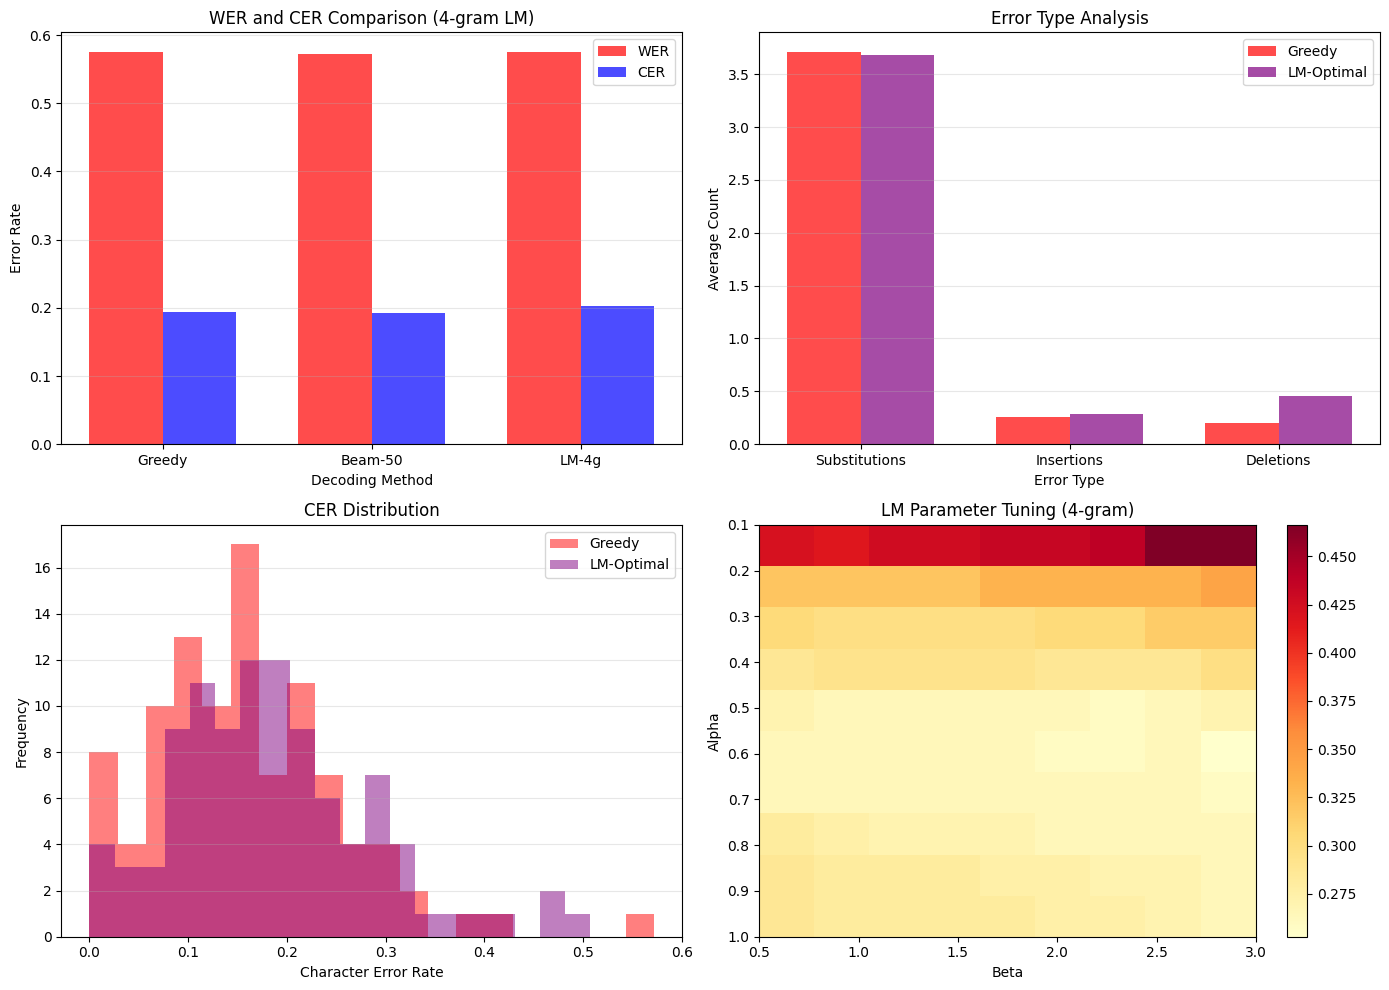


✅ Results saved to /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/test_results_4gram_lm_step_24500.csv
✅ Decoder saved to /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/best_4gram_decoder_step_24500.pkl

📊 FINAL SUMMARY (4-GRAM LM)
Model step: 24500
Test samples: 390

📈 Performance:
  Greedy WER: 0.5747
  Beam WER: 0.5718
  LM WER: 0.5752

⚠️ LM degrades WER by 0.06% absolute

✅ Testing complete!


In [ ]:
# @title
# Cell 18: Advanced LM-Enhanced ASR Testing with Best Models
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
import soundfile as sf
import os
import librosa
from pyctcdecode import build_ctcdecoder
import evaluate
import seaborn as sns
from collections import Counter
import Levenshtein
import subprocess
import pickle
import sys
import warnings
import glob
warnings.filterwarnings('ignore')  # Suppress warnings

# =============================
# STEP 1: Install and Import KenLM at TOP level
# =============================
def install_kenlm():
    """Install KenLM if not already installed"""
    import subprocess
    import os

    def run_silent(cmd):
        subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

    # Install build dependencies
    run_silent("apt-get update -qq")
    run_silent("apt-get install -y build-essential cmake libboost-system-dev libboost-thread-dev libboost-program-options-dev libboost-test-dev libeigen3-dev zlib1g-dev libbz2-dev liblzma-dev -qq")

    # Clone and build KenLM
    if not os.path.exists("/content/kenlm"):
        run_silent("git clone https://github.com/kpu/kenlm.git /content/kenlm")
        run_silent("mkdir -p /content/kenlm/build")
        run_silent("cd /content/kenlm/build && cmake .. && make -j2")

    # Add to PATH
    os.environ['PATH'] += ":/content/kenlm/build/bin"

    # Import kenlm and make it global
    import kenlm
    return kenlm

# Install and import kenlm
print("\n" + "="*60)
print("🔧 INSTALLING KENLM")
print("="*60)
kenlm = install_kenlm()
# Make kenlm available globally
globals()['kenlm'] = kenlm
print("✅ Kenlm installed and imported successfully!")
print(f"   Kenlm type: {type(kenlm)}")
print(f"   Kenlm dir: {dir(kenlm)[:10]}...")

# =============================
# STEP 2: Define paths and configuration
# =============================
BASE_DIR = "/content/drive/MyDrive/Awingi_ASR_Processed_Data"
WORK_DIR = f"{BASE_DIR}/awingi_asr_working"
DATA_DIR = f"{BASE_DIR}/processed"
BEST_MODEL_DIR = f"{WORK_DIR}/best_model"
TRAIN_CSV = f"{DATA_DIR}/train.csv"
VAL_CSV = f"{DATA_DIR}/val.csv"
TEST_CSV = f"{DATA_DIR}/test.csv"

# =============================
# CONFIGURABLE N-GRAM ORDER - CHANGE THIS VALUE
# =============================
NGRAM_ORDER = 4  # You can change this to 2,3,4,5,6,7
print(f"\n📊 Using {NGRAM_ORDER}-gram language model")

# KenLM paths with n-gram in filename
KENLM_ARPA = f"{WORK_DIR}/kenlm_{NGRAM_ORDER}gram.arpa"
KENLM_BIN = f"{WORK_DIR}/kenlm_{NGRAM_ORDER}gram.bin"
LM_TEXT_PATH = f"{WORK_DIR}/lm_text_combined.txt"

os.makedirs(WORK_DIR, exist_ok=True)

# =============================
# STEP 3: Find all best models
# =============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

best_model_dirs = glob.glob(os.path.join(BEST_MODEL_DIR, "best_model_step_*"))

def extract_step(folder_path):
    try:
        step_str = os.path.basename(folder_path).replace("best_model_step_", "")
        return int(step_str)
    except:
        return 0

best_model_dirs.sort(key=extract_step)

print(f"\n📂 Found {len(best_model_dirs)} best models:")
for i, model_dir in enumerate(best_model_dirs):
    step = extract_step(model_dir)
    print(f"   {i+1}. {os.path.basename(model_dir)} (Step: {step})")

# Select the latest model
selected_model = best_model_dirs[-1]
selected_step = extract_step(selected_model)
print(f"\n✅ Selected model: {os.path.basename(selected_model)} (Step: {selected_step})")

# =============================
# STEP 4: Load model and processor
# =============================
print(f"\n📂 Loading model from: {selected_model}")
model = Wav2Vec2ForCTC.from_pretrained(selected_model).to(device)
processor = Wav2Vec2Processor.from_pretrained(selected_model)
model.eval()

print("✅ Model and processor loaded successfully!")
print(f"   Vocab size: {len(processor.tokenizer.get_vocab())}")

# Get space and pipe indices
vocab_dict = processor.tokenizer.get_vocab()
space_idx = vocab_dict[' ']
pipe_idx = vocab_dict['|']
print(f"   Space token index: {space_idx}")
print(f"   Pipe token index: {pipe_idx}")

# =============================
# STEP 5: Load datasets
# =============================
print("\n📊 Loading CSV datasets...")
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print(f"✅ Train: {len(train_df)} samples")
print(f"✅ Validation: {len(val_df)} samples")
print(f"✅ Test: {len(test_df)} samples")

# =============================
# STEP 6: Build KenLM (if needed)
# =============================
print("\n" + "="*60)
print(f"🔧 CHECKING FOR EXISTING {NGRAM_ORDER}-GRAM KENLM MODEL")
print("="*60)

if os.path.exists(KENLM_BIN):
    print(f"✅ Found existing KenLM model: {KENLM_BIN}")
else:
    print(f"\n🔨 Building new {NGRAM_ORDER}-gram KenLM language model...")

    print("\n📝 Preparing text data for KenLM...")
    all_texts = []

    # Add training texts - replace | with space for LM
    for text in train_df['sentence'].dropna():
        text = ' '.join(str(text).split())
        text = text.replace("|", " ")
        if text.strip():
            all_texts.append(text)

    for text in val_df['sentence'].dropna():
        text = ' '.join(str(text).split())
        text = text.replace("|", " ")
        if text.strip():
            all_texts.append(text)

    print(f"✅ {len(all_texts)} sentences for LM training")
    print(f"✅ Total words: {sum(len(t.split()) for t in all_texts)}")

    with open(LM_TEXT_PATH, "w", encoding="utf-8") as f:
        for text in all_texts:
            f.write(text + "\n")

    print(f"\n🔨 Building KenLM {NGRAM_ORDER}-gram model...")
    !lmplz -o {NGRAM_ORDER} --text {LM_TEXT_PATH} --arpa {KENLM_ARPA} --discount_fallback 2>/dev/null
    !build_binary {KENLM_ARPA} {KENLM_BIN} 2>/dev/null
    print(f"✅ KenLM model built: {KENLM_BIN}")

# =============================
# STEP 7: Prepare test data
# =============================
print(f"\n📂 Loading test data...")
test_data = []
for _, row in test_df.iterrows():
    test_data.append({'audio_path': row['path'], 'text': row['sentence']})
print(f"✅ Loaded {len(test_data)} test samples")

# =============================
# STEP 8: Preprocessing function
# =============================
def preprocess_audio(sample):
    try:
        audio_path = sample['audio_path']
        if not os.path.exists(audio_path):
            alt_path = os.path.join(DATA_DIR, 'audio', os.path.basename(audio_path))
            if os.path.exists(alt_path):
                audio_path = alt_path
            else:
                return None

        audio, sr = sf.read(audio_path)

        if len(audio.shape) > 1:
            audio = audio.mean(axis=-1)

        if sr != 16000:
            audio = librosa.resample(audio, orig_sr=sr, target_sr=16000, res_type='kaiser_fast')

        max_length = 20 * 16000
        audio = audio[:max_length]

        inputs = processor(audio, sampling_rate=16000, return_tensors="pt")

        return {
            'input_values': inputs.input_values[0],
            'text': sample['text']
        }
    except Exception as e:
        return None

# =============================
# STEP 9: Process test data
# =============================
print("🔄 Processing test audio files...")
processed_test_data = []
for i, sample in enumerate(test_data):
    processed = preprocess_audio(sample)
    if processed is not None:
        processed_test_data.append(processed)
    if (i + 1) % 50 == 0:
        print(f"   Processed {i+1}/{len(test_data)} samples")

print(f"✅ Processed {len(processed_test_data)}/{len(test_data)} samples")

# =============================
# STEP 10: Create vocabulary - NO DUPLICATES
# =============================
print("\n🔄 Creating vocabulary for decoder...")
vocab_list = [None] * len(vocab_dict)
for token, idx in vocab_dict.items():
    vocab_list[idx] = token
print(f"✅ Vocab size: {len(vocab_list)}")

# =============================
# STEP 11: Extract unigrams from LM
# =============================
print("\n📊 Extracting unigrams from language model...")
unigrams = []
try:
    with open(KENLM_ARPA, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        in_unigrams = False
        for line in lines:
            if '\\1-grams:' in line:
                in_unigrams = True
                continue
            if in_unigrams and line.strip() and '\\2-grams' not in line:
                parts = line.strip().split('\t')
                if len(parts) >= 2:
                    word = parts[1].strip()
                    if word and len(word) > 0:
                        unigrams.append(word)
            if '\\2-grams' in line:
                break
    print(f"✅ Extracted {len(unigrams)} unigrams")
except Exception as e:
    print(f"⚠️ Could not extract unigrams: {e}")
    unigrams = None

# =============================
# STEP 12: Create custom decoder with probability merging
# =============================
print("\n⚙️ Creating decoders...")

# Decoder without LM
decoder_no_lm = build_ctcdecoder(labels=vocab_list)
print("✅ Beam search decoder created")

# Import kenlm again to ensure it's in this scope
import kenlm as kenlm_module

# Base decoder with LM (using original vocab)
print(f"📂 Loading KenLM model from: {KENLM_BIN}")
base_decoder = build_ctcdecoder(
    labels=vocab_list,
    kenlm_model_path=KENLM_BIN,
    unigrams=unigrams if unigrams else None,
    alpha=0.5,
    beta=1.0
)

# Custom decoder class that merges space and pipe probabilities
class MergedDecoder:
    def __init__(self, decoder, space_idx, pipe_idx):
        self.decoder = decoder
        self.space_idx = space_idx
        self.pipe_idx = pipe_idx

    def decode(self, logits, beam_width=100):
        # Convert logits to numpy if needed
        if torch.is_tensor(logits):
            logits_np = logits.cpu().numpy()
        else:
            logits_np = logits

        # Handle batched or single input
        if len(logits_np.shape) == 2:
            logits_np = logits_np[None, :, :]

        # Merge pipe logits into space logits (log-space addition)
        logits_np[..., self.space_idx] = np.logaddexp(
            logits_np[..., self.space_idx],
            logits_np[..., self.pipe_idx]
        )

        # Zero out pipe logits
        logits_np[..., self.pipe_idx] = -1e10

        # Convert to log softmax probabilities
        probs = torch.nn.functional.log_softmax(
            torch.tensor(logits_np), dim=-1
        ).numpy()

        return self.decoder.decode(probs[0], beam_width=beam_width)

# Create merged decoder
decoder_with_lm = MergedDecoder(base_decoder, space_idx, pipe_idx)
print(f"✅ {NGRAM_ORDER}-gram KenLM decoder with probability merging created!")

# =============================
# STEP 13: Decoding functions
# =============================
def decode_greedy(logits, processor):
    pred_ids = torch.argmax(logits, dim=-1)[0]
    return processor.decode(pred_ids)

def decode_beam_search(logits, decoder, beam_width=100):
    if hasattr(decoder, 'decode') and not isinstance(decoder, type(decoder_no_lm)):
        # Custom merged decoder
        return decoder.decode(logits, beam_width=beam_width)
    else:
        # Regular decoder
        logits_np = logits.cpu().numpy()[0]
        probs = torch.nn.functional.log_softmax(torch.tensor(logits_np), dim=-1).numpy()
        return decoder.decode(probs, beam_width=beam_width)

def post_process_for_wer(text):
    """Replace | with space for WER calculation only"""
    if text is None:
        return ""
    return text.replace("|", " ")

def detailed_error_analysis(target, prediction):
    target = target.replace("|", " ")
    prediction = prediction.replace("|", " ")

    target_words = target.split()
    pred_words = prediction.split()

    word_errors = sum(1 for t, p in zip(target_words, pred_words) if t != p)
    insertions = max(0, len(pred_words) - len(target_words))
    deletions = max(0, len(target_words) - len(pred_words))
    char_errors = Levenshtein.distance(target, prediction)

    return {
        "word_errors": word_errors,
        "insertions": insertions,
        "deletions": deletions,
        "substitutions": word_errors - insertions - deletions,
        "char_errors": char_errors,
        "char_error_rate": char_errors / max(len(target), 1)
    }

# =============================
# STEP 14: Tune LM parameters on validation set
# =============================
print("\n🎯 Tuning LM parameters on validation set...")

# Process validation samples
val_samples = []
for i, row in val_df.iterrows():
    if i >= 20:
        break
    processed = preprocess_audio({'audio_path': row['path'], 'text': row['sentence']})
    if processed:
        val_samples.append(processed)

# Test different alpha/beta combinations
alphas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
betas = [0.5, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]
wer_metric = evaluate.load("wer")

best_wer = float('inf')
best_params = (0.6, 2.0)
best_base_decoder = None
lm_tuning_results = []

for alpha in alphas:
    for beta in betas:
        try:
            # Create base decoder with these parameters
            test_base = build_ctcdecoder(
                labels=vocab_list,
                kenlm_model_path=KENLM_BIN,
                unigrams=unigrams if unigrams else None,
                alpha=alpha,
                beta=beta
            )

            # Wrap with merged decoder
            test_decoder = MergedDecoder(test_base, space_idx, pipe_idx)

            # Test on validation samples
            predictions = []
            targets = []

            for sample in val_samples:
                audio_input = sample['input_values'].unsqueeze(0).to(device)
                with torch.no_grad():
                    logits = model(audio_input).logits

                pred_text = decode_beam_search(logits, test_decoder, beam_width=50)
                predictions.append(pred_text)
                targets.append(post_process_for_wer(sample['text']))

            wer = wer_metric.compute(predictions=[post_process_for_wer(p) for p in predictions],
                                    references=targets)
            lm_tuning_results.append({"alpha": alpha, "beta": beta, "wer": wer})
            print(f"  α={alpha:.1f}, β={beta:.1f} → WER: {wer:.4f}")

            if wer < best_wer:
                best_wer = wer
                best_params = (alpha, beta)
                best_base_decoder = test_base

        except Exception as e:
            print(f"  α={alpha:.1f}, β={beta:.1f} → Error: {e}")
            continue

# Create final decoder with best parameters
if best_base_decoder is not None:
    decoder_with_lm = MergedDecoder(best_base_decoder, space_idx, pipe_idx)
    print(f"\n🏆 Best parameters: α={best_params[0]:.1f}, β={best_params[1]:.1f} (WER: {best_wer:.4f})")
else:
    print(f"\n⚠️ Using default parameters (α=0.6, β=2.0)")
    best_params = (0.6, 2.0)

# Save tuning results
if lm_tuning_results:
    df_tuning = pd.DataFrame(lm_tuning_results)
    tuning_path = os.path.join(WORK_DIR, f"lm_tuning_results_{NGRAM_ORDER}gram.csv")
    df_tuning.to_csv(tuning_path, index=False)

# =============================
# STEP 15: Run inference on test set
# =============================
print(f"\n🚀 Running inference on test set with {NGRAM_ORDER}-gram LM...")
results = []
detailed_metrics = {"greedy": [], "beam_50": [], "lm_best": []}

lm_key = f"lm_{NGRAM_ORDER}gram_α{best_params[0]}_β{best_params[1]}"

for i, sample in enumerate(processed_test_data):
    audio_input = sample['input_values'].unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(audio_input).logits

    greedy_text = decode_greedy(logits, processor)
    beam_text = decode_beam_search(logits, decoder_no_lm, beam_width=50)
    lm_text = decode_beam_search(logits, decoder_with_lm, beam_width=50)

    results.append({
        "target": sample['text'],
        "greedy": greedy_text,
        "beam_50": beam_text,
        lm_key: lm_text
    })

    if i < 100:
        detailed_metrics["greedy"].append(detailed_error_analysis(sample['text'], greedy_text))
        detailed_metrics["beam_50"].append(detailed_error_analysis(sample['text'], beam_text))
        detailed_metrics["lm_best"].append(detailed_error_analysis(sample['text'], lm_text))

    if i < 5:
        print(f"\n{'='*60}")
        print(f"📝 Sample {i+1}:")
        print(f"   Target    : {sample['text']}")
        print(f"   Greedy    : '{greedy_text}'")
        print(f"   Beam (50) : '{beam_text}'")
        print(f"   LM (best) : '{lm_text}'")
        print(f"{'='*60}")

    if (i + 1) % 50 == 0:
        print(f"   Processed {i+1}/{len(processed_test_data)} samples")

# =============================
# STEP 16: Compute final metrics
# =============================
print("\n📊 Computing final metrics...")

targets = [post_process_for_wer(r["target"]) for r in results]
greedy_preds = [post_process_for_wer(r["greedy"]) for r in results]
beam_preds = [post_process_for_wer(r["beam_50"]) for r in results]
lm_preds = [post_process_for_wer(r[lm_key]) for r in results]

greedy_wer = wer_metric.compute(predictions=greedy_preds, references=targets)
beam_wer = wer_metric.compute(predictions=beam_preds, references=targets)
lm_wer = wer_metric.compute(predictions=lm_preds, references=targets)

cer_metric = evaluate.load("cer")
greedy_cer = cer_metric.compute(predictions=greedy_preds, references=targets)
beam_cer = cer_metric.compute(predictions=beam_preds, references=targets)
lm_cer = cer_metric.compute(predictions=lm_preds, references=targets)

print(f"\n📊 RESULTS SUMMARY ({NGRAM_ORDER}-GRAM LM) - Step: {selected_step}")
print(f"{'Method':<20} {'WER':<10} {'CER':<10} {'Improvement':<15}")
print(f"{'-'*60}")
print(f"{'Greedy':<20} {greedy_wer:.4f}    {greedy_cer:.4f}    {'-':<15}")
print(f"{'Beam Search (50)':<20} {beam_wer:.4f}    {beam_cer:.4f}    {(greedy_wer-beam_wer)*100:+.2f}%")
print(f"{f'LM ({NGRAM_ORDER}g, α={best_params[0]}, β={best_params[1]})':<20} {lm_wer:.4f}    {lm_cer:.4f}    {(greedy_wer-lm_wer)*100:+.2f}%")

# =============================
# STEP 17: Generate plots
# =============================
print("\n📈 Generating analysis plots...")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: WER/CER comparison
methods = ['Greedy', 'Beam-50', f'LM-{NGRAM_ORDER}g']
wers = [greedy_wer, beam_wer, lm_wer]
cers = [greedy_cer, beam_cer, lm_cer]

x = np.arange(len(methods))
width = 0.35

axes[0, 0].bar(x - width/2, wers, width, label='WER', color='red', alpha=0.7)
axes[0, 0].bar(x + width/2, cers, width, label='CER', color='blue', alpha=0.7)
axes[0, 0].set_xlabel('Decoding Method')
axes[0, 0].set_ylabel('Error Rate')
axes[0, 0].set_title(f'WER and CER Comparison ({NGRAM_ORDER}-gram LM)')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(methods)
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# Plot 2: Error types
if detailed_metrics["greedy"]:
    error_types = ['Substitutions', 'Insertions', 'Deletions']
    greedy_err = [np.mean([m["substitutions"] for m in detailed_metrics["greedy"]]),
                  np.mean([m["insertions"] for m in detailed_metrics["greedy"]]),
                  np.mean([m["deletions"] for m in detailed_metrics["greedy"]])]
    lm_err = [np.mean([m["substitutions"] for m in detailed_metrics["lm_best"]]),
              np.mean([m["insertions"] for m in detailed_metrics["lm_best"]]),
              np.mean([m["deletions"] for m in detailed_metrics["lm_best"]])]

    x_err = np.arange(len(error_types))
    width_err = 0.35

    axes[0, 1].bar(x_err - width_err/2, greedy_err, width_err, label='Greedy', color='red', alpha=0.7)
    axes[0, 1].bar(x_err + width_err/2, lm_err, width_err, label='LM-Optimal', color='purple', alpha=0.7)
    axes[0, 1].set_xlabel('Error Type')
    axes[0, 1].set_ylabel('Average Count')
    axes[0, 1].set_title('Error Type Analysis')
    axes[0, 1].set_xticks(x_err)
    axes[0, 1].set_xticklabels(error_types)
    axes[0, 1].legend()
    axes[0, 1].grid(axis='y', alpha=0.3)

# Plot 3: CER distribution
if detailed_metrics["greedy"]:
    axes[1, 0].hist([m["char_error_rate"] for m in detailed_metrics["greedy"]],
                    bins=20, alpha=0.5, label='Greedy', color='red')
    axes[1, 0].hist([m["char_error_rate"] for m in detailed_metrics["lm_best"]],
                    bins=20, alpha=0.5, label='LM-Optimal', color='purple')
    axes[1, 0].set_xlabel('Character Error Rate')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('CER Distribution')
    axes[1, 0].legend()
    axes[1, 0].grid(axis='y', alpha=0.3)

# Plot 4: LM tuning heatmap
if lm_tuning_results:
    pivot_df = pd.DataFrame(lm_tuning_results).pivot(index='alpha', columns='beta', values='wer')
    im = axes[1, 1].imshow(pivot_df.values, cmap='YlOrRd', aspect='auto',
                           extent=[pivot_df.columns.min(), pivot_df.columns.max(),
                                   pivot_df.index.max(), pivot_df.index.min()])
    axes[1, 1].set_xlabel('Beta')
    axes[1, 1].set_ylabel('Alpha')
    axes[1, 1].set_title(f'LM Parameter Tuning ({NGRAM_ORDER}-gram)')
    plt.colorbar(im, ax=axes[1, 1])

plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, f'lm_analysis_{NGRAM_ORDER}gram_step_{selected_step}.png'), dpi=150)
plt.show()

# =============================
# STEP 18: Save results
# =============================
df_results = pd.DataFrame(results)
results_path = os.path.join(WORK_DIR, f"test_results_{NGRAM_ORDER}gram_lm_step_{selected_step}.csv")
df_results.to_csv(results_path, index=False, encoding="utf-8")
print(f"\n✅ Results saved to {results_path}")

decoder_path = os.path.join(WORK_DIR, f"best_{NGRAM_ORDER}gram_decoder_step_{selected_step}.pkl")
with open(decoder_path, "wb") as f:
    pickle.dump(decoder_with_lm, f)
print(f"✅ Decoder saved to {decoder_path}")

# =============================
# STEP 19: Summary
# =============================
print(f"\n{'='*60}")
print(f"📊 FINAL SUMMARY ({NGRAM_ORDER}-GRAM LM)")
print(f"{'='*60}")
print(f"Model step: {selected_step}")
print(f"Test samples: {len(results)}")
print(f"\n📈 Performance:")
print(f"  Greedy WER: {greedy_wer:.4f}")
print(f"  Beam WER: {beam_wer:.4f}")
print(f"  LM WER: {lm_wer:.4f}")

improvement = (greedy_wer - lm_wer) * 100
if improvement > 0:
    print(f"\n🎉 LM improves WER by {improvement:.2f}% absolute")
else:
    print(f"\n⚠️ LM degrades WER by {abs(improvement):.2f}% absolute")
print(f"{'='*60}")
print("\n✅ Testing complete!")

# Cell : Test both val and test set with LM

In [ ]:
# @title
# ==================== IMPORT REQUIRED MODULES ====================
import json
import torch
import numpy as np
import pandas as pd
import soundfile as sf
import os
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
import subprocess
import pickle
import glob
import warnings
import librosa
warnings.filterwarnings('ignore')

# =============================
# STEP 0: CONFIGURABLE N-GRAM ORDER
# =============================
NGRAM_ORDER = 3  # Change this to 1,2,3,4,5,6,7, etc.
print("\n" + "="*60)
print(f"📊 CONFIGURATION: Using {NGRAM_ORDER}-gram Language Model")
print("="*60)

# Define paths
BASE_DIR = "/content/drive/MyDrive/Awingi_ASR_Processed_Data"
WORK_DIR = f"{BASE_DIR}/awingi_asr_working"
DATA_DIR = f"{BASE_DIR}/processed"
BEST_MODEL_DIR = f"{WORK_DIR}/best_model"
TRAIN_CSV = f"{DATA_DIR}/train.csv"
VAL_CSV = f"{DATA_DIR}/val.csv"
TEST_CSV = f"{DATA_DIR}/test.csv"

# KenLM paths with n-gram in filename
LM_TEXT_PATH = f"{WORK_DIR}/lm_text_combined_{NGRAM_ORDER}gram.txt"
KENLM_ARPA = f"{WORK_DIR}/kenlm_{NGRAM_ORDER}gram.arpa"
KENLM_BIN = f"{WORK_DIR}/kenlm_{NGRAM_ORDER}gram.bin"

os.makedirs(WORK_DIR, exist_ok=True)

# ==================== INSTALL KENLM ====================
print("\n" + "="*60)
print("🔧 INSTALLING KENLM")
print("="*60)

# Install build dependencies
!apt-get update -qq
!apt-get install -y build-essential cmake libboost-system-dev libboost-thread-dev libboost-program-options-dev libboost-test-dev libeigen3-dev zlib1g-dev libbz2-dev liblzma-dev -qq

# Install KenLM via pip
!pip install https://github.com/kpu/kenlm/archive/master.zip -q
!pip install pyctcdecode -q

import kenlm
from pyctcdecode import build_ctcdecoder, Alphabet
print("✅ KenLM installed successfully!")

# ==================== LOAD YOUR BEST MODEL ====================
print("\n" + "="*60)
print("🤖 LOADING BEST ASR MODEL")
print("="*60)

# Find the best model
best_model_dirs = glob.glob(os.path.join(BEST_MODEL_DIR, "best_model_step_*"))

def extract_step(folder_path):
    try:
        step_str = os.path.basename(folder_path).replace("best_model_step_", "")
        return int(step_str)
    except:
        return 0

best_model_dirs.sort(key=extract_step)
selected_model = best_model_dirs[-1]  # Latest model
selected_step = extract_step(selected_model)

print(f"📂 Loading best model from: {selected_model}")

try:
    model = Wav2Vec2ForCTC.from_pretrained(selected_model)
    processor = Wav2Vec2Processor.from_pretrained(selected_model)
    print("✅ Model and processor loaded successfully!")

    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()
    print(f"✅ Model moved to: {device}")

    # Get vocabulary from processor
    vocab = processor.tokenizer.get_vocab()
    vocab_size = len(vocab)
    print(f"✅ Model vocabulary size: {vocab_size}")

    # Get space and pipe indices
    space_idx = vocab[' ']
    pipe_idx = vocab['|']
    print(f"✅ Space token index: {space_idx}, Pipe token index: {pipe_idx}")

except Exception as e:
    print(f"❌ Error loading model: {e}")
    raise

# ==================== LOAD DATASETS ====================
print("\n" + "="*60)
print("📊 LOADING DATASETS")
print("="*60)

# Load data from CSV
print(f"📂 Loading train data from: {TRAIN_CSV}")
train_df = pd.read_csv(TRAIN_CSV)
print(f"✅ Train samples: {len(train_df)}")

print(f"📂 Loading validation data from: {VAL_CSV}")
val_df = pd.read_csv(VAL_CSV)
print(f"✅ Validation samples: {len(val_df)}")

print(f"📂 Loading test data from: {TEST_CSV}")
test_df = pd.read_csv(TEST_CSV)
print(f"✅ Test samples: {len(test_df)}")

# Convert to list of dicts for consistency
train_data = train_df.to_dict('records')
val_data = val_df.to_dict('records')
test_data = test_df.to_dict('records')

# ==================== BUILD KENLM MODEL (if not exists) ====================
print("\n" + "="*60)
print(f"🔧 BUILDING {NGRAM_ORDER}-GRAM KENLM MODEL")
print("="*60)

# Check if KenLM model already exists
if os.path.exists(KENLM_BIN):
    print(f"✅ Found existing {NGRAM_ORDER}-gram model: {KENLM_BIN}")
else:
    print(f"\n📝 Preparing text data for {NGRAM_ORDER}-gram KenLM...")

    # Combine training and validation texts
    all_texts = []
    for item in train_data + val_data:
        text = item["sentence"]
        # Normalize spaces and convert | to space for word-level LM
        text = ' '.join(str(text).split())
        text = text.replace("|", " ")
        if text.strip():
            all_texts.append(text)

    print(f"✅ {len(all_texts)} sentences for LM training")
    print(f"✅ Total words: {sum(len(t.split()) for t in all_texts)}")

    # Save to file
    with open(LM_TEXT_PATH, "w", encoding="utf-8") as f:
        for text in all_texts:
            f.write(text + "\n")
    print(f"✅ Training text saved to: {LM_TEXT_PATH}")

    # Build ARPA file
    print(f"\n🔨 Building {NGRAM_ORDER}-gram ARPA model...")

    # Use lmplz with specified n-gram order
    cmd = f"lmplz -o {NGRAM_ORDER} --text {LM_TEXT_PATH} --arpa {KENLM_ARPA} --discount_fallback"
    result = subprocess.run(cmd, shell=True, capture_output=True, text=True)

    if os.path.exists(KENLM_ARPA):
        file_size = os.path.getsize(KENLM_ARPA) / (1024*1024)
        print(f"✅ ARPA file created: {KENLM_ARPA} ({file_size:.2f} MB)")

        # Try to build binary
        print(f"\n🔨 Converting to binary format...")
        result = subprocess.run(
            f"build_binary {KENLM_ARPA} {KENLM_BIN}",
            shell=True, capture_output=True, text=True
        )

        if os.path.exists(KENLM_BIN):
            bin_size = os.path.getsize(KENLM_BIN) / (1024*1024)
            print(f"✅ Binary file created: {KENLM_BIN} ({bin_size:.2f} MB)")
        else:
            print(f"⚠️ Binary creation failed, will use ARPA file directly")
            KENLM_BIN = KENLM_ARPA
    else:
        print(f"❌ Failed to create ARPA file")
        print(f"Error: {result.stderr}")
        raise FileNotFoundError(f"Could not create {NGRAM_ORDER}-gram KenLM model")

# ==================== CREATE VOCABULARY FOR DECODER ====================
print("\n🔧 Creating vocabulary for CTC decoder...")

# HuggingFace tokenizer vocab: token -> index
tokenizer_vocab = processor.tokenizer.get_vocab()

# Build labels list indexed EXACTLY like the model
vocab_list = [None] * len(tokenizer_vocab)
for token, idx in tokenizer_vocab.items():
    vocab_list[idx] = token

print(f"✅ Decoder vocab size: {len(vocab_list)} (matches model: {model.config.vocab_size})")

# ==================== CREATE CUSTOM DECODER WITH PROBABILITY MERGING ====================
print("\n🔄 Creating custom decoder with probability merging...")

class MergedDecoder:
    """Custom decoder that merges space and pipe probabilities during decoding"""
    def __init__(self, base_decoder, space_idx, pipe_idx):
        self.base_decoder = base_decoder
        self.space_idx = space_idx
        self.pipe_idx = pipe_idx

    def decode(self, logits, beam_width=100):
        # Convert logits to numpy if needed
        if torch.is_tensor(logits):
            logits_np = logits.cpu().numpy()
        else:
            logits_np = logits

        # Handle batched or single input
        if len(logits_np.shape) == 2:
            logits_np = logits_np[None, :, :]

        # Merge pipe logits into space logits (log-space addition)
        logits_np[..., self.space_idx] = np.logaddexp(
            logits_np[..., self.space_idx],
            logits_np[..., self.pipe_idx]
        )

        # Zero out pipe logits (optional, but helps)
        logits_np[..., self.pipe_idx] = -1e10

        # Convert to log softmax probabilities
        probs = torch.nn.functional.log_softmax(
            torch.tensor(logits_np), dim=-1
        ).numpy()

        return self.base_decoder.decode(probs[0], beam_width=beam_width)

# ==================== EXTRACT UNIGRAMS FROM LM ====================
print("\n📊 Extracting unigrams from language model...")

unigrams = []
if os.path.exists(KENLM_ARPA):
    try:
        with open(KENLM_ARPA, 'r', encoding='utf-8') as f:
            lines = f.readlines()
            in_unigrams = False
            for line in lines:
                if '\\1-grams:' in line:
                    in_unigrams = True
                    continue
                if in_unigrams and line.strip() and '\\2-grams' not in line:
                    parts = line.strip().split('\t')
                    if len(parts) >= 2:
                        word = parts[1].strip()
                        if word and len(word) > 0:
                            unigrams.append(word)
                if '\\2-grams' in line:
                    break
        print(f"✅ Extracted {len(unigrams)} unigrams from LM")
    except Exception as e:
        print(f"⚠️ Could not extract unigrams: {e}")
        unigrams = None
else:
    print(f"⚠️ ARPA file not found, using unigrams=None")
    unigrams = None

# ==================== CREATE BASE DECODER ====================
print("\n⚙️ Creating base CTC decoder...")

# Create base decoder with full vocabulary (size 264)
base_decoder = build_ctcdecoder(
    labels=vocab_list,
    kenlm_model_path=KENLM_BIN,
    unigrams=unigrams if unigrams else None,
    alpha=0.5,  # Will be tuned
    beta=1.0,   # Will be tuned
)

# Wrap with merged decoder
ctc_decoder = MergedDecoder(base_decoder, space_idx, pipe_idx)
print(f"✅ Merged decoder created (vocab size: {len(vocab_list)})")

# ==================== CREATE DECODING FUNCTIONS ====================
def decode_with_kenlm(logits, decoder, beam_width=100):
    """Decode using KenLM with beam search"""
    return decoder.decode(logits, beam_width=beam_width)

def decode_without_kenlm(logits, processor):
    """Decode without LM (greedy decoding)"""
    pred_ids = np.argmax(logits, axis=-1)
    decoded_text = processor.decode(pred_ids[0])
    return decoded_text.replace("|", " ").strip()

# ==================== PREPARE TUNING DATA FROM VALIDATION ====================
print("\n" + "="*60)
print(f"🎛️  PREPARING TUNING DATA FROM VALIDATION SET")
print("="*60)

# Use a subset for faster tuning
tune_samples = min(50, len(val_data))
print(f"📊 Preparing {tune_samples} validation samples for tuning...")

# Prepare tuning data
tune_audio_logits = []
tune_targets = []

for i in range(tune_samples):
    try:
        # Load and process audio
        audio_path = val_data[i]["path"]

        if not os.path.exists(audio_path):
            alt_path = os.path.join(DATA_DIR, 'audio', os.path.basename(audio_path))
            if os.path.exists(alt_path):
                audio_path = alt_path
            else:
                continue

        audio, sr = sf.read(audio_path)
        if audio.ndim > 1:
            audio = audio.mean(axis=1)

        if sr != 16000:
            audio = librosa.resample(audio, orig_sr=sr, target_sr=16000, res_type='kaiser_fast')

        # Process through model
        inputs = processor(audio, sampling_rate=16000, return_tensors="pt")

        with torch.no_grad():
            logits = model(inputs.input_values.to(device)).logits.cpu().numpy()

        tune_audio_logits.append(logits)
        tune_targets.append(val_data[i]["sentence"].replace("|", " "))

    except Exception as e:
        print(f"⚠️ Error processing tuning sample {i}: {e}")
        continue

print(f"✅ Prepared {len(tune_audio_logits)} validation samples for tuning")

# ==================== TUNE KENLM PARAMETERS ON VALIDATION ====================
print("\n" + "="*60)
print(f"🎛️  TUNING {NGRAM_ORDER}-GRAM KENLM PARAMETERS ON VALIDATION")
print("="*60)

# Import WER metric
from evaluate import load
wer_metric = load("wer")

# Try different alpha (LM weight) and beta (word insertion penalty) values
alpha_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
beta_values = [0.5, 0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]

tuning_results = []
best_wer = float('inf')
best_params = (0.5, 1.0)  # Default
best_base_decoder = None

print(f"\n🎯 Testing different parameter combinations for {NGRAM_ORDER}-gram LM on VALIDATION...")

for alpha in alpha_values:
    for beta in beta_values:
        print(f"  Testing alpha={alpha:.1f}, beta={beta:.1f}...", end=" ")

        try:
            # Create base decoder with these parameters
            test_base = build_ctcdecoder(
                labels=vocab_list,
                kenlm_model_path=KENLM_BIN,
                unigrams=unigrams if unigrams else None,
                alpha=alpha,
                beta=beta,
            )

            # Wrap with merged decoder
            test_decoder = MergedDecoder(test_base, space_idx, pipe_idx)

            # Evaluate on tuning set
            predictions = []
            references = []

            for j, logits in enumerate(tune_audio_logits):
                kenlm_text = decode_with_kenlm(logits, test_decoder, beam_width=50)
                predictions.append(kenlm_text)
                references.append(tune_targets[j])

            wer = wer_metric.compute(predictions=predictions, references=references)
            tuning_results.append({
                "alpha": alpha,
                "beta": beta,
                "wer": wer
            })

            print(f"WER: {wer:.4f}")

            if wer < best_wer:
                best_wer = wer
                best_params = (alpha, beta)
                best_base_decoder = test_base
                print(f"  🎯 NEW BEST!")

        except Exception as e:
            print(f"Error: {e}")
            continue

print(f"\n✅ Best parameters for {NGRAM_ORDER}-gram: alpha={best_params[0]:.1f}, beta={best_params[1]:.1f} with WER={best_wer:.4f}")

# ==================== CREATE FINAL CTC DECODER WITH BEST PARAMS ====================
print("\n" + "="*60)
print(f"⚙️ CREATING FINAL {NGRAM_ORDER}-GRAM CTC DECODER")
print("="*60)

# Create final decoder with best parameters
final_base_decoder = build_ctcdecoder(
    labels=vocab_list,
    kenlm_model_path=KENLM_BIN,
    unigrams=unigrams if unigrams else None,
    alpha=best_params[0],
    beta=best_params[1],
)

# Wrap with merged decoder
final_ctc_decoder = MergedDecoder(final_base_decoder, space_idx, pipe_idx)
print(f"✅ {NGRAM_ORDER}-gram CTC decoder with probability merging created!")
print(f"  LM weight (alpha): {best_params[0]:.1f}")
print(f"  Word insertion penalty (beta): {best_params[1]:.1f}")
print(f"  Vocabulary size: {len(vocab_list)} (matches model)")

# Save the decoder
print("\n💾 Saving CTC decoder...")
decoder_path = f"{WORK_DIR}/ctc_decoder_{NGRAM_ORDER}gram_optimized.pkl"
with open(decoder_path, "wb") as f:
    pickle.dump(final_ctc_decoder, f)
print(f"✅ CTC decoder saved to: {decoder_path}")

# Save tuning results
if tuning_results:
    df_tuning = pd.DataFrame(tuning_results)
    tuning_path = f"{WORK_DIR}/kenlm_tuning_results_{NGRAM_ORDER}gram.csv"
    df_tuning.to_csv(tuning_path, index=False)
    print(f"✅ Tuning results saved to: {tuning_path}")

# ==================== EVALUATE ON FULL TEST SET ====================
print("\n" + "="*60)
print(f"🧪 EVALUATING {NGRAM_ORDER}-GRAM LM ON FULL TEST SET")
print("="*60)

test_results = []
num_test_samples = len(test_data)

print(f"📊 Testing on {num_test_samples} test samples...")

for i in range(num_test_samples):
    try:
        # Load and process audio
        audio_path = test_data[i]["path"]

        if not os.path.exists(audio_path):
            alt_path = os.path.join(DATA_DIR, 'audio', os.path.basename(audio_path))
            if os.path.exists(alt_path):
                audio_path = alt_path
            else:
                continue

        audio, sr = sf.read(audio_path)
        if audio.ndim > 1:
            audio = audio.mean(axis=1)

        if sr != 16000:
            audio = librosa.resample(audio, orig_sr=sr, target_sr=16000, res_type='kaiser_fast')

        # Process through model
        inputs = processor(audio, sampling_rate=16000, return_tensors="pt")

        with torch.no_grad():
            logits = model(inputs.input_values.to(device)).logits.cpu().numpy()

        # Decode with different methods
        greedy_text = decode_without_kenlm(logits, processor)
        kenlm_text = decode_with_kenlm(logits, final_ctc_decoder, beam_width=100)
        target_text = test_data[i]["sentence"].replace("|", " ")

        test_results.append({
            "target": target_text,
            "greedy": greedy_text,
            "kenlm": kenlm_text
        })

        if (i + 1) % 50 == 0:
            print(f"  Processed {i+1}/{num_test_samples} test samples...")

    except Exception as e:
        print(f"⚠️ Error processing test sample {i}: {e}")
        continue

print(f"✅ Successfully processed {len(test_results)} test samples")

if test_results:
    # Calculate WER for test set
    print("\n🧮 Calculating WER on test set...")

    # Calculate WER for greedy decoding
    test_greedy_predictions = [r["greedy"] for r in test_results]
    test_greedy_references = [r["target"] for r in test_results]
    test_greedy_wer = wer_metric.compute(predictions=test_greedy_predictions, references=test_greedy_references)

    # Calculate WER for KenLM decoding
    test_kenlm_predictions = [r["kenlm"] for r in test_results]
    test_kenlm_references = [r["target"] for r in test_results]
    test_kenlm_wer = wer_metric.compute(predictions=test_kenlm_predictions, references=test_kenlm_references)

    print(f"📊 TEST SET RESULTS ({NGRAM_ORDER}-GRAM):")
    print(f"  Greedy decoding WER: {test_greedy_wer:.4f}")
    print(f"  KenLM decoding WER:  {test_kenlm_wer:.4f}")

    # Calculate improvement
    if test_greedy_wer > 0:
        test_improvement = ((test_greedy_wer - test_kenlm_wer) / test_greedy_wer) * 100
    else:
        test_improvement = 0

    print(f"  📈 Relative improvement: {test_improvement:.1f}%")

    if test_improvement > 0:
        print(f"  🎉 {NGRAM_ORDER}-gram KenLM reduced test set WER by {test_improvement:.1f}%!")
    else:
        print(f"  ⚠️  {NGRAM_ORDER}-gram KenLM did not improve test set WER with current tuning")

    # Save test results
    df_test_results = pd.DataFrame(test_results)
    test_results_path = f"{WORK_DIR}/kenlm_test_results_{NGRAM_ORDER}gram.csv"
    df_test_results.to_csv(test_results_path, index=False, encoding="utf-8")
    print(f"✅ Test results saved to: {test_results_path}")

# ==================== CREATE FINAL ASR SYSTEM ====================
print("\n" + "="*60)
print(f"🔧 CREATING FINAL ASR SYSTEM WITH {NGRAM_ORDER}-GRAM KENLM")
print("="*60)

class OptimizedAwingiASRWithKenLM:
    """Optimized ASR system with tuned KenLM decoding and probability merging"""

    def __init__(self, model_path, processor_path, decoder, ngram_order=None):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.ngram_order = ngram_order

        print(f"📂 Loading ASR model from: {model_path}")
        self.model = Wav2Vec2ForCTC.from_pretrained(model_path).to(self.device)
        self.processor = Wav2Vec2Processor.from_pretrained(processor_path)
        self.model.eval()
        self.decoder = decoder
        self.use_kenlm = True
        print(f"✅ {ngram_order}-gram KenLM decoder loaded")

    def transcribe(self, audio_path, use_kenlm=True, beam_width=100):
        """Transcribe audio file with optional KenLM decoding"""
        try:
            # Load audio
            audio, sr = sf.read(audio_path)
            if audio.ndim > 1:
                audio = audio.mean(axis=1)

            # Resample if needed
            if sr != 16000:
                audio = librosa.resample(audio, orig_sr=sr, target_sr=16000, res_type='kaiser_fast')

            # Process
            inputs = self.processor(audio, sampling_rate=16000, return_tensors="pt")

            # Inference
            with torch.no_grad():
                logits = self.model(inputs.input_values.to(self.device)).logits.cpu().numpy()

            # Decode
            if self.use_kenlm and use_kenlm:
                return self.decoder.decode(logits, beam_width=beam_width)
            else:
                pred_ids = np.argmax(logits, axis=-1)
                text = self.processor.decode(pred_ids[0])
                return text.replace("|", " ").strip()

        except Exception as e:
            return f"Error: {str(e)}"

    def batch_transcribe(self, audio_paths, use_kenlm=True, beam_width=100):
        """Transcribe multiple audio files"""
        return [self.transcribe(path, use_kenlm, beam_width) for path in audio_paths]

print(f"✅ Final ASR system class created with {NGRAM_ORDER}-gram support!")

# Test the final system
print("\n🚀 Testing the final system...")
final_asr_system = OptimizedAwingiASRWithKenLM(
    model_path=selected_model,
    processor_path=selected_model,
    decoder=final_ctc_decoder,
    ngram_order=NGRAM_ORDER
)

# Quick demonstration
if test_data:
    try:
        sample = test_data[0]
        audio_path = sample["path"]
        if not os.path.exists(audio_path):
            alt_path = os.path.join(DATA_DIR, 'audio', os.path.basename(audio_path))
            if os.path.exists(alt_path):
                audio_path = alt_path

        if os.path.exists(audio_path):
            print(f"\n🎧 DEMONSTRATION TRANSCRIPTION ({NGRAM_ORDER}-GRAM):")
            print(f"  Audio: {os.path.basename(audio_path)}")
            print(f"  Target: {sample['sentence'].replace('|', ' ')}")

            # Without KenLM
            text_greedy = final_asr_system.transcribe(audio_path, use_kenlm=False)
            print(f"  Greedy: {text_greedy}")

            # With KenLM
            text_kenlm = final_asr_system.transcribe(audio_path, use_kenlm=True)
            print(f"  KenLM:  {text_kenlm}")
    except Exception as e:
        print(f"⚠️ Error in demonstration: {e}")

print("\n" + "="*60)
print(f"🎉 FINAL RESULTS SUMMARY ({NGRAM_ORDER}-GRAM)")
print("="*60)

if test_results:
    print(f"📊 PERFORMANCE:")
    print(f"  Greedy WER: {test_greedy_wer:.4f}")
    print(f"  {NGRAM_ORDER}-gram KenLM WER:  {test_kenlm_wer:.4f}")

    if test_improvement > 0:
        print(f"  Improvement: +{test_improvement:.1f}%")
        print(f"  🎉 {NGRAM_ORDER}-gram KenLM improved test accuracy!")
    else:
        print(f"  Change: {test_improvement:.1f}%")
        print(f"  ⚠️  {NGRAM_ORDER}-gram KenLM did not improve test accuracy with current tuning")

print(f"\n📁 OUTPUT FILES:")
print(f"  ✅ Tuning results: {tuning_path if 'tuning_path' in locals() else 'Not generated'}")
print(f"  ✅ Optimized decoder: {decoder_path}")
print(f"  ✅ Test results: {test_results_path if 'test_results_path' in locals() else 'Not generated'}")
print(f"  ✅ KenLM model: {KENLM_BIN}")

print(f"\n🚀 USAGE:")
print(f"  asr = OptimizedAwingiASRWithKenLM('{selected_model}', '{selected_model}', decoder, ngram_order={NGRAM_ORDER})")
print(f"  text = asr.transcribe('audio.wav', use_kenlm=True)")

print("\n" + "="*60)
print(f"✅ {NGRAM_ORDER}-GRAM KENLM OPTIMIZATION COMPLETE!")
print("="*60)


📊 CONFIGURATION: Using 3-gram Language Model

🔧 INSTALLING KENLM
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✅ KenLM installed successfully!

🤖 LOADING BEST ASR MODEL
📂 Loading best model from: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/best_model/best_model_step_24500


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

✅ Model and processor loaded successfully!
✅ Model moved to: cuda
✅ Model vocabulary size: 264
✅ Space token index: 0, Pipe token index: 259

📊 LOADING DATASETS
📂 Loading train data from: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/train.csv
✅ Train samples: 6598
📂 Loading validation data from: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/val.csv
✅ Validation samples: 392
📂 Loading test data from: /content/drive/MyDrive/Awingi_ASR_Processed_Data/processed/test.csv
✅ Test samples: 390

🔧 BUILDING 3-GRAM KENLM MODEL
✅ Found existing 3-gram model: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_3gram.bin

🔧 Creating vocabulary for CTC decoder...
✅ Decoder vocab size: 264 (matches model: 264)

🔄 Creating custom decoder with probability merging...

📊 Extracting unigrams from language model...


✅ Extracted 27115 unigrams from LM

⚙️ Creating base CTC decoder...
✅ Merged decoder created (vocab size: 264)

🎛️  PREPARING TUNING DATA FROM VALIDATION SET
📊 Preparing 50 validation samples for tuning...
✅ Prepared 50 validation samples for tuning

🎛️  TUNING 3-GRAM KENLM PARAMETERS ON VALIDATION



🎯 Testing different parameter combinations for 3-gram LM on VALIDATION...
  Testing alpha=0.1, beta=0.5... 

WER: 0.9026
  🎯 NEW BEST!
  Testing alpha=0.1, beta=0.8... 

... (87 outputs left out)

WER: 0.8370
  Testing alpha=1.0, beta=3.0... 

WER: 0.8350

✅ Best parameters for 3-gram: alpha=0.8, beta=1.5 with WER=0.8330

⚙️ CREATING FINAL 3-GRAM CTC DECODER
✅ 3-gram CTC decoder with probability merging created!
  LM weight (alpha): 0.8
  Word insertion penalty (beta): 1.5
  Vocabulary size: 264 (matches model)

💾 Saving CTC decoder...
✅ CTC decoder saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/ctc_decoder_3gram_optimized.pkl
✅ Tuning results saved to: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_tuning_results_3gram.csv

🧪 EVALUATING 3-GRAM LM ON FULL TEST SET
📊 Testing on 390 test samples...
  Processed 50/390 test samples...
  Processed 100/390 test samples...
  Processed 150/390 test samples...
  Processed 200/390 test samples...
  Processed 250/390 test samples...
  Processed 300/390 test samples...
  Processed 350/390 test samples...
✅ Successfully processed 390 test samples

🧮 Calculating WER on test set...
📊 TEST SET RESULTS (3-GRAM):
  Greedy decoding WER:

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

✅ 3-gram KenLM decoder loaded

🎧 DEMONSTRATION TRANSCRIPTION (3-GRAM):
  Audio: 221126-050706_azo_5e8_elicit_0.wav
  Target: ዴንነቱ ዎክርዳ ቱኑኒ ክልልካሾ ቤቴናና ፋይንታኪ ማበሪዴስ ፍሾፀካማ ዎታድራ ፄዋና ሸው ስጋት ክኹጙ ሼው እፅካ
  Greedy: ዴንቱ ውክርዳ ቱኑኒ ክልልካሾ ቤቴናና ፋይንታኪ ማቢሪ ዴ ፍፅካማ ዎታድራ ፄዋና ሼው ስጋያትጝ ኽጙ ሼው እፅካ
  KenLM:  ዴንኔቱ ውክርዳ ቱኑኒ ክልልካሾ ቤቴናና ፋይንታኪ ማቢሪዴስ ፍሽፅካማ ዎታድር ፄዋና ሼው ስጋት ሼው እፅካ

🎉 FINAL RESULTS SUMMARY (3-GRAM)
📊 PERFORMANCE:
  Greedy WER: 0.5744
  3-gram KenLM WER:  0.6091
  Change: -6.0%
  ⚠️  3-gram KenLM did not improve test accuracy with current tuning

📁 OUTPUT FILES:
  ✅ Tuning results: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_tuning_results_3gram.csv
  ✅ Optimized decoder: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/ctc_decoder_3gram_optimized.pkl
  ✅ Test results: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_test_results_3gram.csv
  ✅ KenLM model: /content/drive/MyDrive/Awingi_ASR_Processed_Data/awingi_asr_working/kenlm_3g